# Questão 1 — Comparação de documentos parecidos: demonstração aplicada

Este caderno implementa, em escala de demonstração, a solução descrita no texto de entrega. Cada seção corresponde a uma parte do texto e a um item do enunciado. As afirmações do texto são verificadas com `assert`. Se alguma deixar de valer, o caderno para com erro.

| § | Seção | Item do enunciado |
|---|---|---|
| 0 | Configuração e limiares | — |
| 1 | Representação: normalização, parágrafos, hashes, shingles, campos | 1. Representação |
| 2 | Coleção de referência, gerador sintético e linguagem padrão (boilerplate) | 2. Quase iguais × vocabulário parecido |
| 3 | Alinhamento por parágrafos e evidências | 2, 3 |
| 4 | Decisão com motivos, subtipo (mesma peça × outra instância), relação por trecho, casos de borda | 2, 5 |
| 5 | Vocabulário parecido não é derivação | 2 |
| 6 | Busca semântica: onde ajuda e onde não decide | 2 |
| 7 | Documentos longos e LLM só em trechos | 3 |
| 8 | Sistema: ingestão de PDF, cabeçalho e carimbo, arquivos problemáticos, anexos por hash perceptual, idempotência, concorrência, isolamento | 1, 5 |
| 9 | Candidatos em casos grandes: índices exatos + índice de âncoras (contenção, *winnowing*) | 6 |
| 10 | Depois da classificação: grupos, direção, ações, revisão, reprocessamento, cache incremental por parágrafo | 5, 6 |
| 11 | Avaliação: teste gerado depois dos limiares, por par × por documento, classificador calibrado com risco controlado | 4, 6 |
| 12 | Custo e latência | 6 |
| 13 | Painel final e limitações | — |

**Como rodar:** testado com Python 3.14, `pymupdf`, `numpy` e `matplotlib` nas versões do `requirements.txt` (impressas na §0). Use *Restart & Run All*. Tudo é sintético e determinístico (seeds fixas). Nenhum dado real de cliente é usado.

## 0. Configuração e limiares

Todos os limiares ficam num único lugar. Eles foram escolhidos com os casos escritos à mão das §§1–5, **antes** de gerar o conjunto de teste da §11. Cada um tem uma intuição de uma linha. Os valores são pontos de partida a recalibrar com pares reais rotulados.

In [1]:
import hashlib
import json
import math
import random
import re
import shutil
import sqlite3
import sys
import time
import unicodedata
from collections import Counter, defaultdict
from dataclasses import dataclass, field, replace
from functools import lru_cache
from difflib import SequenceMatcher

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pymupdf

VERSAO_PIPELINE = "q1-v2"
K_SHINGLE = 5  # 5 palavras: curto o bastante para sobreviver a edições locais, longo o bastante para ser específico


@dataclass(frozen=True)
class Limiares:
    boilerplate_df: float = 0.05     # shingle presente em ≥5% da coleção de referência é linguagem padrão
    alinhamento_paragrafo: float = 0.50  # dois parágrafos se alinham se metade do conteúdo específico do menor reaparece no outro
    derivacao: float = 0.60          # ≥60% do conteúdo específico do documento menor reaparece, alinhado, no maior
    cobertura_maior: float = 0.50    # abaixo disso o menor está "embutido" num documento muito maior
    diferente: float = 0.20          # <20% de conteúdo específico em comum: documentos independentes
    min_shingles: int = 10           # menos que isso não há texto suficiente para afirmar nada
    semantico: float = 0.85          # similaridade de paráfrase entre parágrafos (só desvia "diferente" para revisão)


LIMIARES = Limiares()
print(f"Python {sys.version.split()[0]} | pymupdf {pymupdf.__version__} | numpy {np.__version__} | matplotlib {matplotlib.__version__}")
print(f"Pipeline {VERSAO_PIPELINE} | {LIMIARES}")

Python 3.14.6 | pymupdf 1.28.2 | numpy 2.5.4 | matplotlib 3.11.2
Pipeline q1-v2 | Limiares(boilerplate_df=0.05, alinhamento_paragrafo=0.5, derivacao=0.6, cobertura_maior=0.5, diferente=0.2, min_shingles=10, semantico=0.85)


## 1. Representação do documento

Cada documento vira **várias representações**, cada uma com um papel:

| Representação | Papel |
|---|---|
| SHA-256 dos bytes do arquivo | prova de cópia exata |
| SHA-256 do texto extraído | cópia em outro arquivo (reexportação, metadados diferentes) |
| Cabeçalho/rodapé (fora do corpo, dentro da igualdade) | nº do processo no cabeçalho não pode sumir da comparação (§8.3) |
| Impressões não textuais: imagens e assinatura digital | peça carimbada/assinada × rascunho com o mesmo texto (§8.3) |
| Chave cosmética (texto após normalização de lista branca) | detecta “cópia com ressalva” |
| Parágrafos com página e offsets | unidade de alinhamento e de evidência |
| Shingles de 5 palavras por parágrafo | recuperar candidatos e ancorar o alinhamento |
| Campos críticos (valores, datas, CPF/CNPJ, nº do processo) | destacar alterações para o revisor |

**Normalização de lista branca:** só entram transformações que nunca mudam o sentido: Unicode NFC, ligaduras, aspas e travessões tipográficos, hifenização de quebra de linha, linhas de numeração de página, caixa e espaços. Tudo o que não está na lista (vírgula, dígito, espaço dentro de número, palavra) é diferença material. Como “cópia” exige igualdade depois dessa normalização, **o risco de chamar versão de cópia fica concentrado nesta função**. Por isso ela é pequena e testada caso a caso.

In [2]:
TIPOGRAFIA = str.maketrans({
    "“": '"', "”": '"', "„": '"', "«": '"', "»": '"', "‘": "'", "’": "'",
    "–": "-", "—": "-", "−": "-", " ": " ", " ": " ", " ": " ",
    "ﬁ": "fi", "ﬂ": "fl",
})
RE_HIFEN_QUEBRA = re.compile(r"(\w)-\n(\w)")
RE_LINHA_PAGINA = re.compile(r"^[ \t]*(?:p[áa]gina|p[áa]g\.?|fls?\.?)[ \t]*\d+(?:[ \t]*(?:de|/)[ \t]*\d+)?[ \t]*(?:\n|$)", re.IGNORECASE | re.MULTILINE)
RE_TOKEN = re.compile(r"\d+(?:[.,/-]\d+)*|\w+|[^\w\s]")


def preparar_exibicao(texto):
    """Ajustes que preservam a caixa: usado para exibir trechos e para segmentar."""
    texto = unicodedata.normalize("NFC", texto).translate(TIPOGRAFIA)
    texto = RE_LINHA_PAGINA.sub("", texto)          # antes da hifenização: a palavra pode estar partida em volta do rodapé
    return RE_HIFEN_QUEBRA.sub(r"\1\2", texto)


def normalizar(texto):
    """Lista branca de mudanças cosméticas. Nada aqui pode alterar o sentido."""
    linhas = [re.sub(r"[ \t]+", " ", linha).strip() for linha in preparar_exibicao(texto).casefold().split("\n")]
    return "\n".join(linha for linha in linhas if linha)


def chave_cosmetica(texto):
    # Quebras de linha e de parágrafo também são cosméticas (reexportar um PDF muda onde o parágrafo quebra).
    return re.sub(r"\s+", " ", normalizar(texto)).strip()


def tokens(texto):
    return RE_TOKEN.findall(texto)


def palavras(texto_normalizado):
    # Pontuação fica de fora dos shingles (recuperação robusta), mas continua no diff (decisão).
    return [t for t in tokens(texto_normalizado) if t[0].isalnum() or t[0] == "_"]


def shingles_de(lista_palavras, k=K_SHINGLE):
    if not lista_palavras:
        return []
    if len(lista_palavras) < k:
        return [tuple(lista_palavras)]
    return [tuple(lista_palavras[i:i + k]) for i in range(len(lista_palavras) - k + 1)]


def sha256(dados):
    if isinstance(dados, str):
        dados = dados.encode("utf-8")
    return hashlib.sha256(dados).hexdigest()


# Exemplos da lista branca: tudo à esquerda é igual à direita depois da normalização.
exemplos_cosmeticos = {
    "NFD × NFC": ("A petição foi protocolada.", unicodedata.normalize("NFD", "A petição foi protocolada.")),
    "hifenização de quebra de linha": ("serviços de manutenção predial", "serviços de manu-\ntenção predial"),
    "linha de numeração de página": ("Primeiro parágrafo.\nSegundo parágrafo.", "Primeiro parágrafo.\nPágina 2 de 9\nSegundo parágrafo."),
    "palavra hifenizada em volta do rodapé": ("a consumidora pagou", "a cons-\nPágina 1 de 9\numidora pagou"),
    "aspas e travessão tipográficos": ('o "contrato" - assinado', "o “contrato” — assinado"),
    "caixa e espaços": ("Requer a citação da ré.", "REQUER  a   citação da ré."),
    "parágrafo quebrado em dois": ("A autora contratou a ré e pagou.", "A autora contratou a ré\ne pagou."),
}
for nome, (a, b) in exemplos_cosmeticos.items():
    assert a != b and chave_cosmetica(a) == chave_cosmetica(b), nome
    print(f"cosmético ✅  {nome}")

exemplos_materiais = {
    "vírgula removida": ("Não, houve pagamento.", "Não houve pagamento."),
    "espaço dentro de número": ("R$ 12.500,00", "R$ 1 2.500,00"),
    "palavras unidas": ("a ré pagou", "aré pagou"),
    "um centavo": ("R$ 12.500,00", "R$ 12.500,01"),
    "negação": ("houve quitação", "não houve quitação"),
}
for nome, (a, b) in exemplos_materiais.items():
    assert chave_cosmetica(a) != chave_cosmetica(b), nome
    print(f"material  ✅  {nome}")

cosmético ✅  NFD × NFC
cosmético ✅  hifenização de quebra de linha
cosmético ✅  linha de numeração de página
cosmético ✅  palavra hifenizada em volta do rodapé
cosmético ✅  aspas e travessão tipográficos
cosmético ✅  caixa e espaços
cosmético ✅  parágrafo quebrado em dois
material  ✅  vírgula removida
material  ✅  espaço dentro de número
material  ✅  palavras unidas
material  ✅  um centavo
material  ✅  negação


### 1.1 Campos críticos

Os campos servem **só para destacar** alterações ao revisor. Eles nunca liberam “cópia”: quem decide cópia é a chave cosmética. Se a extração de um campo falhar, a proteção continua no diff. Nomes de partes não são extraídos aqui (exigiriam NER); eles aparecem no diff.

In [3]:
MESES = "janeiro|fevereiro|março|abril|maio|junho|julho|agosto|setembro|outubro|novembro|dezembro"
PADROES_CAMPOS = {
    "valor": re.compile(r"r\$ ?\d{1,3}(?:\.\d{3})*,\d{2}"),
    "data": re.compile(rf"\b\d{{1,2}}/\d{{1,2}}/\d{{4}}\b|\b\d{{1,2}} de (?:{MESES}) de \d{{4}}\b"),
    "cpf": re.compile(r"\b\d{3}\.\d{3}\.\d{3}-\d{2}\b"),
    "cnpj": re.compile(r"\b\d{2}\.\d{3}\.\d{3}/\d{4}-\d{2}\b"),
    "processo": re.compile(r"\b\d{7}-\d{2}\.\d{4}\.\d\.\d{2}\.\d{4}\b"),
}
NEGACOES = {"não", "nunca", "jamais", "nem", "exceto", "salvo", "sem"}


def extrair_campos(texto):
    plano = chave_cosmetica(texto)
    return {nome: Counter(padrao.findall(plano)) for nome, padrao in PADROES_CAMPOS.items()}


def alteracoes_de_campos(campos_a, campos_b):
    saida = {}
    for nome in PADROES_CAMPOS:
        removidos = sorted((campos_a[nome] - campos_b[nome]).elements())
        incluidos = sorted((campos_b[nome] - campos_a[nome]).elements())
        if removidos or incluidos:
            saida[nome] = {"antes": removidos, "depois": incluidos}
    return saida


exemplo = "Processo 0001234-56.2024.8.26.0100. CPF 123.456.789-09, valor R$ 12.500,00, vencido em 15 de março de 2024."
print(json.dumps({k: list(v) for k, v in extrair_campos(exemplo).items()}, ensure_ascii=False))
print(alteracoes_de_campos(extrair_campos(exemplo), extrair_campos(exemplo.replace("12.500,00", "18.900,00"))))

{"valor": ["r$ 12.500,00"], "data": ["15 de março de 2024"], "cpf": ["123.456.789-09"], "cnpj": [], "processo": ["0001234-56.2024.8.26.0100"]}
{'valor': {'antes': ['r$ 12.500,00'], 'depois': ['r$ 18.900,00']}}


### 1.2 Parágrafos com página e offsets

O parágrafo é a unidade de comparação e de evidência. Ele guarda a página e a posição no texto extraído, para que o revisor vá direto ao trecho. Uma quebra de linha com hifenização não separa parágrafos, e linhas de numeração de página são descartadas.

In [4]:
@dataclass
class Paragrafo:
    indice: int
    pagina: int
    inicio: int          # offset no texto extraído
    fim: int
    texto: str           # para exibição: preserva caixa
    normalizado: str
    palavras: list
    shingles: list
    chave: str = ""      # chave cosmética do parágrafo, pré-calculada (a comparação só junta chaves)


@dataclass
class Documento:
    doc_id: str
    texto_extraido: str
    paragrafos: list
    sha256_arquivo: str | None
    sha256_texto: str
    chave: str
    campos: dict
    extracao_ok: bool = True
    motivo_extracao: str = ""
    cabecalho: str = ""                                   # cabeçalho/rodapé removidos do corpo, mas comparados (§8)
    partes: tuple = ()                                    # nomes das partes na qualificação (identidade da peça, §4)
    nao_textual: dict = field(default_factory=dict)       # impressões de imagens e assinatura digital (§8)
    # Preenchidos na indexação (§3): shingles específicos e máscara de palavras específicas por parágrafo.
    informativos: list = None
    mascara: list = None


def _segmentos(pagina):
    """Divide a página em linhas-parágrafo, sem cortar palavras hifenizadas na quebra de linha."""
    inicio = 0
    for m in re.finditer(r"\n", pagina):
        i = m.start()
        if i >= 2 and re.match(r"\w-", pagina[i - 2:i]) and i + 1 < len(pagina) and pagina[i + 1].isalnum():
            continue
        yield inicio, i
        inicio = i + 1
    yield inicio, len(pagina)


RE_QUALIFICACAO = re.compile(r"\b(?:CPF|CNPJ|RG)\b", re.IGNORECASE)
RE_ACAO = re.compile(r"\b(?:vem|vêm|propor|ajuizar|em face de)\b", re.IGNORECASE)
RE_NOME = re.compile(r"^[^\W\d_]+(?:[ ][^\W\d_]+){1,7}$")
RE_REU = re.compile(r"em face de ([^,]+),", re.IGNORECASE)


def extrair_partes(paragrafos):
    """Partes da QUALIFICAÇÃO: o parágrafo que tem CPF/CNPJ/RG e o verbo da ação. Autor = texto antes da 1ª vírgula;
    réu = depois de 'em face de'. Nomes citados no resto do texto (testemunhas, advogados) não contam.
    Heurística de demonstração; em produção, extração estruturada (NER ou LLM sobre o 1º parágrafo) conferida com o cadastro do caso."""
    partes = set()
    for texto in paragrafos[:6]:
        if not (RE_QUALIFICACAO.search(texto) and RE_ACAO.search(texto)):
            continue
        autor = re.sub(r"\s+", " ", texto.split(",")[0]).strip()
        if RE_NOME.match(autor):
            partes.add(autor.casefold())
        partes.update(re.sub(r"\s+", " ", m).strip().casefold() for m in RE_REU.findall(texto))
    return tuple(sorted(partes))


def representar(doc_id, paginas, sha256_arquivo=None, extracao_ok=True, motivo_extracao="", cabecalho="", nao_textual=None):
    if isinstance(paginas, str):
        paginas = [paginas]
    texto_extraido = "\n".join(paginas)
    paragrafos, deslocamento = [], 0
    for numero_pagina, pagina in enumerate(paginas, start=1):
        for ini, fim in _segmentos(pagina):
            bruto = pagina[ini:fim]
            normalizado = normalizar(bruto)
            if not normalizado:
                continue  # linha vazia ou numeração de página
            lista = palavras(normalizado)
            paragrafos.append(Paragrafo(len(paragrafos), numero_pagina, deslocamento + ini, deslocamento + fim,
                                        preparar_exibicao(bruto).strip(), normalizado, lista, shingles_de(lista),
                                        re.sub(r"\s+", " ", normalizado).strip()))
        deslocamento += len(pagina) + 1
    return Documento(doc_id, texto_extraido, paragrafos, sha256_arquivo, sha256(texto_extraido),
                     chave_cosmetica(texto_extraido), extrair_campos(texto_extraido), extracao_ok, motivo_extracao,
                     cabecalho, extrair_partes([p.texto for p in paragrafos]), nao_textual or {})


demo = representar("demo", ["Primeiro parágrafo com manu-\ntenção predial.\nPágina 1 de 2", "Segundo parágrafo, já na página dois."])
for p in demo.paragrafos:
    print(f"§{p.indice} pág.{p.pagina} [{p.inicio}:{p.fim}] {p.texto!r} → {len(p.shingles)} shingles")
assert len(demo.paragrafos) == 2 and demo.paragrafos[0].texto == "Primeiro parágrafo com manutenção predial."

§0 pág.1 [0:44] 'Primeiro parágrafo com manutenção predial.' → 1 shingles
§1 pág.2 [59:96] 'Segundo parágrafo, já na página dois.' → 2 shingles


## 2. Coleção de referência e linguagem padrão

Petições compartilham muito texto padrão (“Ante o exposto…”, “Termos em que pede deferimento”). Se esse texto contar como evidência, duas petições independentes parecem derivadas uma da outra. A solução estima o que é padrão pela **frequência numa coleção histórica independente**: um shingle presente em ≥5% dos documentos de referência é *boilerplate* e não conta como evidência de derivação.

Para a demonstração uso um **gerador sintético** de petições de 4 áreas, com texto padrão, qualificação das partes, fatos combinatórios e campos aleatórios. O mesmo gerador cria a coleção de referência (seed 0), os casos das §§4–10 e o conjunto de teste da §11 (outras seeds). Limitação honesta: é um gerador combinatório, e petições reais têm outra distribuição.

In [5]:
NOMES = ["Maria", "Marina", "Ana", "Beatriz", "Carla", "Daniela", "Eduarda", "Fernanda", "Gabriela", "Helena",
         "João", "Pedro", "Rafael", "Lucas", "Mateus", "Carlos", "Bruno", "Tiago", "André", "Felipe"]
SOBRENOMES = ["Silva", "Souza", "Oliveira", "Santos", "Pereira", "Costa", "Rodrigues", "Almeida", "Nascimento", "Lima",
              "Araújo", "Fernandes", "Carvalho", "Gomes", "Martins", "Rocha", "Ribeiro", "Barbosa", "Teixeira", "Moreira"]
EMPRESAS = ["Alfa", "Atlas", "Horizonte", "Nova Era", "Prisma", "Vértice", "Solaris", "Delta", "Orion", "Aurora"]
RAMOS = ["Serviços Prediais", "Telecomunicações", "Comércio Varejista", "Logística", "Engenharia", "Imóveis", "Saúde"]
CIDADES = ["São Paulo", "Campinas", "Santos", "Curitiba", "Belo Horizonte", "Porto Alegre", "Recife", "Salvador"]
MESES_LISTA = MESES.split("|")

BOILERPLATE = [
    "Ante o exposto, requer o regular prosseguimento do feito, com observância das formalidades legais e intimação das partes para todos os atos processuais.",
    "Requer a citação da parte ré, por via postal, para, querendo, apresentar contestação no prazo legal, sob pena de revelia e confissão quanto à matéria de fato.",
    "Protesta provar o alegado por todos os meios de prova em direito admitidos, especialmente prova documental, testemunhal e pericial, se necessária.",
    "Requer a concessão dos benefícios da justiça gratuita, nos termos do artigo 98 do Código de Processo Civil, por não possuir condições de arcar com as custas.",
    "Requer a inversão do ônus da prova, nos termos do artigo 6º, inciso VIII, do Código de Defesa do Consumidor, diante da verossimilhança das alegações.",
    "Manifesta interesse na realização de audiência de conciliação, nos termos do artigo 319, inciso VII, do Código de Processo Civil.",
    "Por tais razões, requer o acolhimento integral dos pedidos formulados na presente petição inicial, com a condenação da ré ao pagamento das custas e honorários advocatícios.",
    "Requer que todas as intimações sejam realizadas exclusivamente em nome do advogado subscritor, sob pena de nulidade, nos termos do artigo 272 do Código de Processo Civil.",
    "Dá-se à causa o valor indicado na planilha anexa, para todos os efeitos legais e fiscais, nos termos do artigo 292 do Código de Processo Civil.",
    "Nestes termos, a parte autora confia no elevado senso de justiça deste juízo para a procedência dos pedidos, como medida de inteira e lídima justiça.",
]
# Dois trechos padrão que NÃO existem na coleção de referência: usados na §11 para medir o limite do método.
BOILERPLATE_DESCONHECIDO = [
    "Registra, por oportuno, que a presente demanda observa os princípios da cooperação, da boa-fé processual e da duração razoável do processo, conforme os artigos 5º e 6º do Código de Processo Civil.",
    "Esclarece, ainda, que os documentos que instruem a inicial são cópias fiéis dos originais, declaradas autênticas pelo advogado subscritor, sob sua responsabilidade pessoal.",
]

AREAS = {
    "serviços": {
        "acao": "COBRANÇA",
        "sujeito": ["A autora", "A contratada", "A equipe técnica da autora", "O responsável técnico", "A prestadora", "O encarregado da obra",
                    "O síndico do edifício", "O gerente da ré", "O preposto da ré", "A fiscalização da ré", "O engenheiro responsável", "A coordenação do contrato"],
        "acao_verbo": ["realizou", "concluiu", "comprovou", "apresentou", "enviou", "recebeu", "reconheceu", "registrou", "aprovou", "efetuou", "acompanhou", "validou"],
        "objeto": ["a troca das bombas hidráulicas", "a revisão do quadro elétrico", "a pintura das áreas comuns", "a substituição dos elevadores",
                   "a impermeabilização da cobertura", "o reparo da rede de esgoto", "a manutenção do sistema de incêndio", "a instalação das câmeras",
                   "o relatório de execução", "a medição mensal dos serviços", "a nota fiscal de serviços", "o termo de aceite parcial"],
        "complemento": ["na unidade comercial {n}", "no bloco {letra} do edifício", "conforme ordem de serviço nº {num}", "dentro do prazo do cronograma",
                        "com acompanhamento do síndico", "após a vistoria técnica", "segundo o laudo de {data}", "mediante protocolo nº {num}",
                        "no valor de {valor}", "com prazo de garantia de {n} meses", "sem qualquer ressalva formal", "com registro fotográfico datado"],
    },
    "consumo": {
        "acao": "INDENIZAÇÃO POR DANOS MORAIS E MATERIAIS",
        "sujeito": ["O autor", "A consumidora", "A central de atendimento", "O atendente da ré", "A operadora", "O fornecedor",
                    "O setor de cobrança da ré", "A ouvidoria da ré", "O técnico credenciado", "A instituição financeira", "O vendedor da loja", "A transportadora"],
        "acao_verbo": ["realizou", "cancelou", "cobrou", "comprovou", "recebeu", "registrou", "reconheceu", "enviou", "negou", "efetuou", "apresentou", "estornou"],
        "objeto": ["a cobrança do pacote adicional", "o cancelamento da linha telefônica", "a entrega do produto adquirido", "a troca do aparelho defeituoso",
                   "o estorno das parcelas indevidas", "a reclamação formal da consumidora", "a fatura com lançamentos desconhecidos", "o contrato de adesão",
                   "o pedido de portabilidade", "a negativação do nome do autor", "o reparo em garantia", "a oferta anunciada no site"],
        "complemento": ["no protocolo de atendimento nº {num}", "em {data}", "no valor de {valor}", "após {n} tentativas de contato",
                        "sem autorização expressa", "conforme gravação da ligação", "dentro do prazo de garantia", "segundo a nota fiscal nº {num}",
                        "por meio do aplicativo", "na loja da cidade de {cidade}", "com cobrança de multa de {valor}", "sem resposta da ouvidoria"],
    },
    "trabalhista": {
        "acao": "RECLAMAÇÃO TRABALHISTA",
        "sujeito": ["O reclamante", "A reclamante", "O supervisor imediato", "A empresa reclamada", "O setor de recursos humanos", "O gerente da filial",
                    "A testemunha indicada", "O coordenador de turno", "A empregadora", "O sindicato da categoria", "O médico do trabalho", "O encarregado do setor"],
        "acao_verbo": ["realizou", "cumpriu", "recebeu", "comprovou", "registrou", "exigiu", "pagou", "reconheceu", "apresentou", "assinou", "efetuou", "anotou"],
        "objeto": ["a jornada de doze horas diárias", "as horas extras habituais", "o intervalo intrajornada reduzido", "o adicional de insalubridade",
                   "as verbas rescisórias", "o depósito do FGTS", "o aviso prévio indenizado", "as metas abusivas de vendas",
                   "o controle de ponto britânico", "a dispensa sem justa causa", "o atestado médico", "a transferência de unidade"],
        "complemento": ["entre {data} e {data2}", "na filial de {cidade}", "conforme cartões de ponto", "sem pagamento correspondente",
                        "no valor de {valor}", "durante {n} meses consecutivos", "segundo o contracheque de {data}", "conforme convenção coletiva",
                        "por determinação da gerência", "sem anotação na carteira", "com aviso de {n} dias", "mediante recibo nº {num}"],
    },
    "locação": {
        "acao": "DESPEJO CUMULADA COM COBRANÇA DE ALUGUÉIS",
        "sujeito": ["O locador", "A locatária", "A administradora do imóvel", "O fiador", "O vistoriador", "O corretor responsável",
                    "A imobiliária", "O condomínio", "O inquilino", "A proprietária", "O avaliador contratado", "O síndico"],
        "acao_verbo": ["realizou", "pagou", "recebeu", "comprovou", "devolveu", "enviou", "registrou", "reconheceu", "apresentou", "assinou", "efetuou", "notificou"],
        "objeto": ["o contrato de locação residencial", "os aluguéis vencidos", "a vistoria de entrada", "as chaves do imóvel",
                   "o depósito caução", "a notificação extrajudicial", "o reajuste anual do aluguel", "as cotas condominiais",
                   "o laudo de vistoria de saída", "a multa contratual", "o seguro fiança", "o termo de entrega das chaves"],
        "complemento": ["em {data}", "no valor de {valor}", "referente ao imóvel da rua {num}", "conforme cláusula {n} do contrato",
                        "com prazo de {n} dias", "por meio da administradora", "sem qualquer justificativa", "segundo recibo nº {num}",
                        "na cidade de {cidade}", "após {n} meses de atraso", "com registro em cartório", "acompanhado de fotografias"],
    },
}
DIREITO = {
    "serviços": "Nos termos dos artigos 389 e 395 do Código Civil, o devedor responde por perdas e danos, juros e atualização monetária quando não cumpre a obrigação no tempo e modo devidos.",
    "consumo": "Nos termos do artigo 14 do Código de Defesa do Consumidor, o fornecedor responde, independentemente de culpa, pela reparação dos danos causados aos consumidores por defeitos na prestação dos serviços.",
    "trabalhista": "Nos termos do artigo 7º da Constituição Federal e do artigo 59 da Consolidação das Leis do Trabalho, a jornada excedente deve ser remunerada com adicional mínimo de cinquenta por cento.",
    "locação": "Nos termos do artigo 9º, inciso III, da Lei 8.245 de 1991, a locação pode ser desfeita em decorrência da falta de pagamento do aluguel e demais encargos.",
}
VERBOS_NEGAVEIS = sorted({v for area in AREAS.values() for v in area["acao_verbo"]}, key=len, reverse=True)


@dataclass
class Peca:
    area: str
    paragrafos: list
    campos: dict

    @property
    def texto(self):
        return "\n".join(self.paragrafos)


def _valor(rng):
    reais = rng.randint(1_000, 250_000)
    return f"R$ {reais:,}".replace(",", ".") + f",{rng.randint(0, 99):02d}"


def _data(rng):
    return f"{rng.randint(1, 28)} de {rng.choice(MESES_LISTA)} de {rng.randint(2019, 2025)}"


def _cpf(rng):
    d = [rng.randint(0, 9) for _ in range(11)]
    return f"{d[0]}{d[1]}{d[2]}.{d[3]}{d[4]}{d[5]}.{d[6]}{d[7]}{d[8]}-{d[9]}{d[10]}"


def _cnpj(rng):
    d = "".join(str(rng.randint(0, 9)) for _ in range(14))
    return f"{d[:2]}.{d[2:5]}.{d[5:8]}/{d[8:12]}-{d[12:]}"


def _frase(rng, area):
    g = AREAS[area]
    complemento = rng.choice(g["complemento"]).format(
        n=rng.randint(2, 60), num=rng.randint(1000, 99999), letra=rng.choice("ABCDEF"), data=_data(rng), data2=_data(rng),
        valor=_valor(rng), cidade=rng.choice(CIDADES))
    return f"{rng.choice(g['sujeito'])} {rng.choice(g['acao_verbo'])} {rng.choice(g['objeto'])} {complemento}."


def paragrafo_de_fatos(rng, area, frases=(2, 4)):
    return " ".join(_frase(rng, area) for _ in range(rng.randint(*frases)))


def gerar_peca(rng, area=None, n_fatos=(3, 7), boilerplate=BOILERPLATE, n_boilerplate=(2, 4)):
    area = area or rng.choice(list(AREAS))
    autor = f"{rng.choice(NOMES)} {rng.choice(SOBRENOMES)} {rng.choice(SOBRENOMES)}"
    re_ = f"{rng.choice(EMPRESAS)} {rng.choice(RAMOS)} Ltda."
    campos = {"autor": autor, "re": re_, "cidade": rng.choice(CIDADES), "valor": _valor(rng), "data": _data(rng)}
    paragrafos = [
        f"EXCELENTÍSSIMO SENHOR DOUTOR JUIZ DE DIREITO DA {rng.randint(1, 40)}ª VARA CÍVEL DA COMARCA DE {campos['cidade'].upper()}",
        f"{autor}, CPF nº {_cpf(rng)}, com endereço em {campos['cidade']}, vem, por seu advogado, propor a presente "
        f"AÇÃO DE {AREAS[area]['acao']} em face de {re_}, CNPJ nº {_cnpj(rng)}, pelos fatos e fundamentos a seguir expostos.",
        "DOS FATOS",
    ]
    paragrafos += [paragrafo_de_fatos(rng, area) for _ in range(rng.randint(*n_fatos))]
    paragrafos += ["DO DIREITO", DIREITO[area], "DOS PEDIDOS",
                   f"Requer a condenação de {re_} ao pagamento de {campos['valor']}, acrescido de correção monetária desde {campos['data']} e juros de mora desde a citação."]
    paragrafos += rng.sample(boilerplate, rng.randint(*n_boilerplate))
    paragrafos += ["Termos em que pede deferimento.", f"{campos['cidade']}, {_data(rng)}.",
                   f"{rng.choice(NOMES)} {rng.choice(SOBRENOMES)} - OAB/SP {rng.randint(100000, 499999)}"]
    return Peca(area, paragrafos, campos)


rng_ref = random.Random(0)
colecao_referencia = [gerar_peca(rng_ref).texto for _ in range(400)]
print(f"Coleção de referência: {len(colecao_referencia)} petições sintéticas (seed 0), independentes dos casos de teste.")
print("\nExemplo de petição gerada (seed 7):\n")
print(gerar_peca(random.Random(7), "serviços", n_fatos=(2, 2)).texto)

Coleção de referência: 400 petições sintéticas (seed 0), independentes dos casos de teste.

Exemplo de petição gerada (seed 7):

EXCELENTÍSSIMO SENHOR DOUTOR JUIZ DE DIREITO DA 3ª VARA CÍVEL DA COMARCA DE CAMPINAS
João Pereira Carvalho, CPF nº 166.131.860-91, com endereço em Campinas, vem, por seu advogado, propor a presente AÇÃO DE COBRANÇA em face de Alfa Serviços Prediais Ltda., CNPJ nº 39.099.603/0824-62, pelos fatos e fundamentos a seguir expostos.
DOS FATOS
A fiscalização da ré realizou a medição mensal dos serviços com acompanhamento do síndico. A coordenação do contrato apresentou a revisão do quadro elétrico dentro do prazo do cronograma. A equipe técnica da autora recebeu a pintura das áreas comuns com prazo de garantia de 21 meses. A fiscalização da ré registrou a revisão do quadro elétrico mediante protocolo nº 6138.
A prestadora validou a manutenção do sistema de incêndio com acompanhamento do síndico. A equipe técnica da autora validou a substituição dos elevadores sem qu

### 2.1 Índice de referência: o que é linguagem padrão

A frequência de documento (DF) de cada shingle é calculada **uma vez** sobre a coleção de referência. Um shingle é *específico* (informativo) quando aparece em menos de 5% dela. Uma palavra é específica quando é coberta por pelo menos um shingle específico. Assim, nomes, valores, fatos e combinações raras ficam, e fórmulas repetidas saem.

In [6]:
class IndiceReferencia:
    def __init__(self, textos, limiares=LIMIARES):
        self.n = len(textos)
        self.limiar = limiares.boilerplate_df
        self.df = Counter()
        for texto in textos:
            doc = representar("ref", texto)
            self.df.update({s for p in doc.paragrafos for s in p.shingles})

    def frequencia(self, shingle):
        return self.df.get(shingle, 0) / self.n

    def eh_padrao(self, shingle):
        return self.frequencia(shingle) >= self.limiar


inicio = time.perf_counter()
INDICE = IndiceReferencia(colecao_referencia)
print(f"Índice com {len(INDICE.df):,} shingles distintos em {time.perf_counter() - inicio:.1f}s")

for trecho in [BOILERPLATE[0], BOILERPLATE_DESCONHECIDO[0], "A autora realizou a troca das bombas hidráulicas na unidade comercial 17."]:
    sh = shingles_de(palavras(normalizar(trecho)))
    padrao = sum(INDICE.eh_padrao(s) for s in sh)
    print(f"{padrao:>3}/{len(sh):<3} shingles padrão | {trecho[:80]}…")

Índice com 37,127 shingles distintos em 0.3s
 19/19  shingles padrão | Ante o exposto, requer o regular prosseguimento do feito, com observância das fo…
  1/31  shingles padrão | Registra, por oportuno, que a presente demanda observa os princípios da cooperaç…
  1/8   shingles padrão | A autora realizou a troca das bombas hidráulicas na unidade comercial 17.…


## 3. Indexação, alinhamento por parágrafos e evidências

**Indexar** um documento marca, em cada parágrafo, os shingles e as palavras específicas. **Comparar** dois documentos segue três passos:

1. **Âncoras:** um índice invertido de shingles específicos aponta quais parágrafos de B compartilham conteúdo com cada parágrafo de A. Assim nunca comparamos todos com todos, o que viabiliza documentos de centenas de páginas (§7).
2. **Alinhamento 1:1 ou 1:N:** parágrafos com ≥50% de conteúdo específico em comum são ligados. Cada componente desse grafo vira um grupo alinhado. Se de um lado há um parágrafo só e do outro vários, é um parágrafo **dividido ou unido** (outro extrator, DOCX × PDF) e o grupo é aceito inteiro. Se há vários dos dois lados, o casamento volta a ser 1:1, do par mais parecido para o menos parecido. A ordem não importa, então parágrafos reordenados continuam alinhados.
3. **Cobertura:** dentro de cada grupo alinhado, um diff de palavras conta quantas palavras específicas se mantiveram. A cobertura de um documento é a fração das suas palavras específicas que reaparecem alinhadas no outro. Ela é calculada **por massa de texto**, não por número de blocos, e por isso não depende do tamanho do documento nem de quantas edições ele sofreu.

O resultado é uma `Evidencia`: números para a decisão e trechos (com página) para o revisor.

**A medida de similaridade do desenho é a cobertura, calculada nos dois sentidos.** Um número único (cosseno, Jaccard) não distingue “B é uma versão de A” de “A está dentro de B” nem de “B é A abreviado”, e não diz *o que* mudou. As duas coberturas distinguem, e o diff por grupo diz o resto.

In [7]:
def indexar(doc, indice=None):
    indice = indice or INDICE
    doc.informativos, doc.mascara = [], []
    for p in doc.paragrafos:
        especificos = [not indice.eh_padrao(s) for s in p.shingles]
        mascara = [False] * len(p.palavras)
        if len(p.palavras) < K_SHINGLE:
            mascara = [bool(especificos and especificos[0])] * len(p.palavras)
        else:
            for i, especifico in enumerate(especificos):
                if especifico:
                    for j in range(i, i + K_SHINGLE):
                        mascara[j] = True
        doc.informativos.append({s for s, e in zip(p.shingles, especificos) if e})
        doc.mascara.append(mascara)
    return doc


class UniaoBusca:
    """Union-find: usado no alinhamento (aqui) e nos grupos de documentos (§10)."""
    def __init__(self):
        self.pai = {}

    def achar(self, x):
        self.pai.setdefault(x, x)
        while self.pai[x] != x:
            self.pai[x] = self.pai[self.pai[x]]
            x = self.pai[x]
        return x

    def unir(self, x, y):
        self.pai[self.achar(x)] = self.achar(y)


@dataclass
class Evidencia:
    a: str
    b: str
    bytes_iguais: bool
    texto_igual: bool            # texto do corpo e cabeçalho idênticos
    so_cosmetico: bool           # corpo e cabeçalho iguais após a normalização de lista branca
    nao_textual_igual: bool      # mesmas imagens e mesma presença de assinatura digital
    extracao_ok: bool
    motivo_extracao: str
    informativos_a: int
    informativos_b: int
    cobertura_a: float           # fração das palavras específicas de A que reaparecem alinhadas em B
    cobertura_b: float
    jaccard_especifico: float    # só para contraste com o baseline; não entra em nenhuma decisão
    alinhados: list = field(default_factory=list)       # (parágrafos de A, parágrafos de B, similaridade)
    modificados: list = field(default_factory=list)     # grupos alterados, com página e diff
    removidos: list = field(default_factory=list)       # parágrafos específicos de A sem par em B
    adicionados: list = field(default_factory=list)
    padrao_alterado: int = 0                            # parágrafos só de texto padrão que mudaram
    reordenado: bool = False
    campos: dict = field(default_factory=dict)
    negacoes: list = field(default_factory=list)
    parafrase: float | None = None                      # preenchido pela §6 (opcional)
    nao_textual_diferencas: list = field(default_factory=list)
    nao_textual_critico: bool = False                     # imagem a mais/a menos ou assinatura diferente (recompressão não conta)
    observacoes: list = field(default_factory=list)       # diferenças que não bloqueiam "cópia com ressalva", mas o revisor deve ver
    trocas_identidade: list = field(default_factory=list) # parte ou processo trocados: "outra instância do modelo" (§4)
    trecho: dict | None = None                            # onde o documento menor aparece dentro do maior (§4)

    @property
    def cobertura_menor(self):
        return max(self.cobertura_a, self.cobertura_b)

    @property
    def cobertura_maior(self):
        return min(self.cobertura_a, self.cobertura_b)


def diff_palavras(texto_a, texto_b):
    """Diff de tokens que preserva a caixa original; compara pela forma normalizada."""
    ta, tb = tokens(texto_a), tokens(texto_b)
    ka, kb = [t.casefold() for t in ta], [t.casefold() for t in tb]
    partes, negacoes = [], []
    for op, i1, i2, j1, j2 in SequenceMatcher(a=ka, b=kb, autojunk=False).get_opcodes():
        if op == "equal":
            continue
        antes, depois = " ".join(ta[i1:i2]), " ".join(tb[j1:j2])
        partes.append(f"[-{antes}-]→[+{depois}+]" if antes and depois else (f"[-{antes}-]" if antes else f"[+{depois}+]"))
        negacoes += [t for t in ka[i1:i2] + kb[j1:j2] if t in NEGACOES]
    return partes, negacoes


def _palavras_mantidas(pa, pb, mascara_a, mascara_b):
    """Quantas palavras específicas de cada lado ficam em blocos iguais do diff."""
    ma = mb = 0
    for bloco in SequenceMatcher(a=pa, b=pb, autojunk=False).get_matching_blocks():
        ma += sum(mascara_a[bloco.a:bloco.a + bloco.size])
        mb += sum(mascara_b[bloco.b:bloco.b + bloco.size])
    return ma, mb


def _alinhar(a, b, limiares):
    """Âncoras → grafo de parágrafos → grupos 1:1 ou 1:N; componentes N:M voltam ao casamento 1:1 guloso."""
    invertido = defaultdict(set)
    for j, conjunto in enumerate(b.informativos):
        for s in conjunto:
            invertido[s].add(j)
    arestas = []
    for i, conjunto in enumerate(a.informativos):
        contagem = Counter(j for s in conjunto for j in invertido.get(s, ()))
        for j, comum in contagem.items():
            similaridade = comum / min(len(conjunto), len(b.informativos[j]))
            if similaridade >= limiares.alinhamento_paragrafo:
                arestas.append((similaridade, comum, i, j))
    uf = UniaoBusca()
    for _, _, i, j in arestas:
        uf.unir(("a", i), ("b", j))
    componentes = defaultdict(lambda: (set(), set()))
    for _, _, i, j in arestas:
        raiz = uf.achar(("a", i))
        componentes[raiz][0].add(i)
        componentes[raiz][1].add(j)
    grupos = []
    for raiz, (lado_a, lado_b) in componentes.items():
        if len(lado_a) == 1 or len(lado_b) == 1:
            sim = max(e[0] for e in arestas if e[2] in lado_a and e[3] in lado_b)
            grupos.append((tuple(sorted(lado_a)), tuple(sorted(lado_b)), round(sim, 3)))
            continue
        usados_a, usados_b = set(), set()
        internas = [e for e in arestas if e[2] in lado_a and e[3] in lado_b]
        for similaridade, _, i, j in sorted(internas, key=lambda e: (-e[0], -e[1], e[2], e[3])):
            if i not in usados_a and j not in usados_b:
                usados_a.add(i)
                usados_b.add(j)
                grupos.append(((i,), (j,), round(similaridade, 3)))
    return sorted(grupos)


def _juntar(doc, indices):
    texto = " ".join(doc.paragrafos[k].texto for k in indices)
    lista = [w for k in indices for w in doc.paragrafos[k].palavras]
    mascara = [m for k in indices for m in doc.mascara[k]]
    return texto, lista, mascara


def _parecidos(x, y, limiar=0.8):
    return SequenceMatcher(None, x.casefold(), y.casefold()).ratio() >= limiar


def processos_proprios(doc, inicio=0):
    """Nº do processo do PRÓPRIO documento: cabeçalho e preâmbulo (3 primeiros parágrafos). Precedentes citados no corpo não contam."""
    preambulo = " ".join(p.chave for p in doc.paragrafos[inicio:inicio + 3])
    cabecalho = doc.cabecalho if inicio == 0 else ""
    return set(PADROES_CAMPOS["processo"].findall(cabecalho)) | set(PADROES_CAMPOS["processo"].findall(preambulo))


def _identidade(a, b, trecho=None):
    """Identidade da peça = partes da qualificação + processo próprio. Nomes parecidos (erro de digitação) não contam como troca.
    Se o menor está dentro do maior, a identidade do maior é a do TRECHO (os autos têm a qualificação de outras peças)."""
    partes_a, partes_b = a.partes, b.partes
    proc_a, proc_b = processos_proprios(a), processos_proprios(b)
    if trecho:
        maior = a if trecho["documento"] == a.doc_id else b
        lo, hi = trecho["paragrafos"]
        partes_trecho = extrair_partes([maior.paragrafos[k].texto for k in range(lo, hi + 1)])
        proc_trecho = processos_proprios(maior, lo)
        if maior is a:
            partes_a, proc_a = partes_trecho, proc_trecho
        else:
            partes_b, proc_b = partes_trecho, proc_trecho
    trocas = []
    sem_par_a = [p for p in partes_a if not any(_parecidos(p, q) for q in partes_b)]
    sem_par_b = [q for q in partes_b if not any(_parecidos(q, p) for p in partes_a)]
    if sem_par_a and sem_par_b:
        trocas.append(f"parte: {', '.join(sem_par_a)} → {', '.join(sem_par_b)}")
    if proc_a and proc_b and not proc_a & proc_b:
        trocas.append(f"processo: {', '.join(sorted(proc_a))} → {', '.join(sorted(proc_b))}")
    return trocas


def _bruto(doc, k):
    p = doc.paragrafos[k]
    return doc.texto_extraido[p.inicio:p.fim]


def _trecho(menor, maior, grupos, lado_menor):
    """Região do maior onde o menor aparece. Usa a menor janela que cobre 90% dos grupos alinhados,
    para que um parágrafo alinhado por acaso fora da região não a 'estique'."""
    pares = sorted((g[1 - lado_menor][0], g[lado_menor][0]) for g in grupos)   # (posição no maior, posição no menor)
    if not pares:
        return None
    k = max(1, math.ceil(0.9 * len(pares)))
    inicio = min(range(len(pares) - k + 1), key=lambda i: pares[i + k - 1][0] - pares[i][0])
    janela = pares[inicio:inicio + k]
    lo = max(0, min(j - i for j, i in janela))
    hi = min(len(maior.paragrafos) - 1, max(j + (len(menor.paragrafos) - 1 - i) for j, i in janela))
    texto_trecho = "\n".join(_bruto(maior, x) for x in range(lo, hi + 1))
    texto_menor = "\n".join(_bruto(menor, x) for x in range(len(menor.paragrafos)))
    return {"documento": maior.doc_id, "paragrafos": (lo, hi),
            "paginas": (maior.paragrafos[lo].pagina, maior.paragrafos[hi].pagina),
            "contiguo": (janela[-1][0] - janela[0][0] + 1) <= 1.5 * len(menor.paragrafos),
            "igual": texto_trecho == texto_menor, "cosmetico": chave_cosmetica(texto_trecho) == chave_cosmetica(texto_menor),
            "cabecalho_fora": bool(menor.cabecalho)}


def comparar(a, b, limiares=LIMIARES):
    for doc in (a, b):
        if doc.informativos is None:
            indexar(doc)
    grupos = _alinhar(a, b, limiares)
    # Cobertura por massa de palavras específicas + diff dos grupos alterados.
    total_a = sum(sum(m) for m in a.mascara)
    total_b = sum(sum(m) for m in b.mascara)
    mantidas_a = mantidas_b = 0
    modificados, negacoes = [], []
    for lado_a, lado_b, similaridade in grupos:
        texto_a, palavras_a, mascara_a = _juntar(a, lado_a)
        texto_b, palavras_b, mascara_b = _juntar(b, lado_b)
        ma, mb = _palavras_mantidas(palavras_a, palavras_b, mascara_a, mascara_b)
        mantidas_a += ma
        mantidas_b += mb
        if " ".join(a.paragrafos[i].chave for i in lado_a) != " ".join(b.paragrafos[j].chave for j in lado_b):
            partes, neg = diff_palavras(texto_a, texto_b)
            negacoes += neg
            modificados.append({"par": (lado_a, lado_b), "paginas": (a.paragrafos[lado_a[0]].pagina, b.paragrafos[lado_b[0]].pagina),
                                "similaridade": similaridade, "diff": partes})
    usados_a = {i for lado_a, _, _ in grupos for i in lado_a}
    usados_b = {j for _, lado_b, _ in grupos for j in lado_b}
    # Parágrafos sem conteúdo específico (texto padrão): comparados pela chave cosmética, sem contar como evidência.
    padrao_a = Counter(p.chave for p, inf in zip(a.paragrafos, a.informativos) if not inf)
    padrao_b = Counter(p.chave for p, inf in zip(b.paragrafos, b.informativos) if not inf)
    ordem_b = [lado_b[0] for _, lado_b, _ in grupos]
    inf_a = set().union(*a.informativos) if a.informativos else set()
    inf_b = set().union(*b.informativos) if b.informativos else set()
    campos = alteracoes_de_campos(a.campos, b.campos)
    observacoes = []
    # Cabeçalho ALTERADO (os dois têm, e diferem) é material; cabeçalho AUSENTE num lado (ex.: .txt × PDF) é só observado.
    cabecalho_alterado = bool(a.cabecalho and b.cabecalho) and chave_cosmetica(a.cabecalho) != chave_cosmetica(b.cabecalho)
    if cabecalho_alterado:
        campos["cabeçalho"] = {"antes": [a.cabecalho], "depois": [b.cabecalho]}
    elif bool(a.cabecalho) != bool(b.cabecalho):
        observacoes.append("cabeçalho presente em só um dos documentos: " + (a.cabecalho or b.cabecalho))
    # Só compara o que os dois formatos conhecem: um .txt não "tem imagens diferentes" de um PDF, ele só não tem a informação.
    diferencas = [f"{k}: {a.nao_textual[k]!r} × {b.nao_textual[k]!r}"
                  for k in sorted(set(a.nao_textual) & set(b.nao_textual)) if a.nao_textual[k] != b.nao_textual[k]]
    cobertura_a = mantidas_a / total_a if total_a else 0.0
    cobertura_b = mantidas_b / total_b if total_b else 0.0
    trecho = None
    if max(cobertura_a, cobertura_b) >= limiares.derivacao and min(cobertura_a, cobertura_b) < limiares.cobertura_maior:
        trecho = _trecho(a, b, grupos, 0) if cobertura_a >= cobertura_b else _trecho(b, a, grupos, 1)
    return Evidencia(
        a=a.doc_id, b=b.doc_id,
        bytes_iguais=bool(a.sha256_arquivo) and a.sha256_arquivo == b.sha256_arquivo,
        texto_igual=a.sha256_texto == b.sha256_texto and a.cabecalho == b.cabecalho,
        so_cosmetico=a.chave == b.chave and not cabecalho_alterado,
        nao_textual_igual=not diferencas,
        extracao_ok=a.extracao_ok and b.extracao_ok,
        motivo_extracao="; ".join(m for m in (a.motivo_extracao, b.motivo_extracao) if m),
        informativos_a=len(inf_a), informativos_b=len(inf_b),
        cobertura_a=cobertura_a,
        cobertura_b=cobertura_b,
        jaccard_especifico=len(inf_a & inf_b) / len(inf_a | inf_b) if inf_a | inf_b else 0.0,
        alinhados=grupos, modificados=modificados,
        removidos=[(i, a.paragrafos[i].pagina) for i, inf in enumerate(a.informativos) if inf and i not in usados_a],
        adicionados=[(j, b.paragrafos[j].pagina) for j, inf in enumerate(b.informativos) if inf and j not in usados_b],
        padrao_alterado=sum(((padrao_a - padrao_b) + (padrao_b - padrao_a)).values()),
        reordenado=ordem_b != sorted(ordem_b),
        campos=campos,
        negacoes=sorted(set(negacoes)),
        nao_textual_diferencas=diferencas,
        nao_textual_critico=any(a.nao_textual.get(k) != b.nao_textual.get(k) for k in ("assinatura_digital",) if k in a.nao_textual and k in b.nao_textual)
        or ("imagens" in a.nao_textual and "imagens" in b.nao_textual and len(a.nao_textual["imagens"]) != len(b.nao_textual["imagens"])),
        observacoes=observacoes,
        trocas_identidade=_identidade(a, b, trecho),
        trecho=trecho,
    )

## 4. Decisão com motivos

A decisão é uma sequência curta de regras legíveis. Cada saída carrega os motivos que a justificam. A ordem importa: **“cópia” só sai por igualdade** (bytes, texto, ou texto após a normalização de lista branca). Nenhum limiar numérico leva a “cópia”. Por isso o erro *versão → cópia* só pode vir da **representação**: de `normalizar` (§1) ou da extração, que poderia esconder uma diferença. Por isso a igualdade também exige o mesmo cabeçalho e os mesmos elementos não textuais (imagens, assinatura digital). Os dois casos aparecem na §8.

| Ordem | Condição | Classe |
|---|---|---|
| 1 | bytes iguais | cópia |
| 2 | extração falhou (OCR ausente/ruim) | revisão necessária |
| 3 | texto e cabeçalho idênticos, mesmos elementos não textuais | cópia |
| 3b | texto idêntico, mas imagens/assinatura diferentes | cópia com ressalva (conferir qual é a peça assinada) |
| 4 | iguais após normalização de lista branca | cópia com ressalva |
| 5 | menos de 10 shingles específicos em algum lado | revisão necessária |
| 6 | cobertura do menor ≥ 60% e do maior ≥ 50% | versão |
| 7 | cobertura do menor ≥ 60%, maior < 50%, e o menor aparece **contíguo** dentro do maior | cópia / cópia com ressalva / versão **do trecho** (pelas mesmas regras de igualdade, aplicadas ao trecho) |
| 7b | idem, mas espalhado pelo maior | revisão necessária |
| 8 | cobertura do menor < 20% e sem sinal de paráfrase | diferente |
| 9 | qualquer outro caso (20–60%, ou paráfrase) | revisão necessária |

**Atributos** (taxonomia pública: as 3 classes do enunciado + “em revisão”, com atributos em vez de mais classes):
- **cópia:** *exata* ou *com ressalva*;
- **versão:** *mesma peça* (a identidade é a mesma: partes e processo) ou *outra instância do modelo* (o mesmo texto-base usado para outra parte ou outro processo). Para o advogado, uma substitui a anterior; a outra é um documento independente;
- **relação:** *documento inteiro* ou *trecho* (“B contém A nas páginas x–y”), o caso típico de petição juntada com anexos ou de autos completos.

In [8]:
CLASSES = ["cópia", "cópia com ressalva", "versão", "diferente", "revisão necessária"]


@dataclass
class Decisao:
    classe: str
    motivos: list
    evidencia: Evidencia
    subtipo: str = ""            # versão: "mesma peça" | "outra instância do modelo"
    relacao: str = "documento"   # "documento" | "trecho"


def rotulo_publico(decisao):
    """Como o advogado vê: classe do enunciado + atributos."""
    if decisao.classe == "revisão necessária":
        return "em revisão"
    rotulo = {"cópia": "cópia · exata", "cópia com ressalva": "cópia · com ressalva", "diferente": "diferente"}.get(
        decisao.classe, f"versão · {decisao.subtipo}")
    if decisao.relacao == "trecho":
        t = decisao.evidencia.trecho
        rotulo += f" · trecho (págs. {t['paginas'][0]}–{t['paginas'][1]} de {t['documento']})"
    return rotulo


def _resumo_alteracoes(ev):
    itens = []
    if ev.modificados:
        itens.append(f"{len(ev.modificados)} parágrafo(s) alterado(s)")
    if ev.adicionados:
        itens.append(f"{len(ev.adicionados)} incluído(s)")
    if ev.removidos:
        itens.append(f"{len(ev.removidos)} removido(s)")
    if ev.padrao_alterado:
        itens.append(f"{ev.padrao_alterado} trecho(s) padrão alterado(s)")
    if ev.reordenado:
        itens.append("ordem dos parágrafos alterada")
    if ev.campos:
        itens.append("campos alterados: " + ", ".join(ev.campos))
    if ev.negacoes:
        itens.append("negação no diff: " + ", ".join(ev.negacoes))
    return itens or ["diferença material fora dos parágrafos específicos (ex.: pontuação)"]


def decidir(ev, limiares=LIMIARES):
    if ev.bytes_iguais:
        return Decisao("cópia", ["bytes idênticos (SHA-256)"], ev)
    if not ev.extracao_ok:
        return Decisao("revisão necessária", [f"extração insuficiente: {ev.motivo_extracao}"], ev)
    if ev.texto_igual:
        if ev.nao_textual_igual:
            return Decisao("cópia", ["texto extraído idêntico; arquivos diferentes (ex.: reexportação)"], ev)
        return Decisao("cópia com ressalva", ["texto idêntico, mas diferem elementos não textuais: " + "; ".join(ev.nao_textual_diferencas),
                                              "conferir qual é a peça assinada/protocolada"], ev)
    if ev.so_cosmetico:
        motivos = ["iguais após normalização de lista branca (caixa, espaços, Unicode, hifenização, paginação)"]
        if not ev.nao_textual_igual:
            motivos.append("diferem elementos não textuais: " + "; ".join(ev.nao_textual_diferencas))
        return Decisao("cópia com ressalva", motivos + ev.observacoes, ev)
    if min(ev.informativos_a, ev.informativos_b) < limiares.min_shingles:
        return Decisao("revisão necessária", [f"conteúdo específico insuficiente ({ev.informativos_a} e {ev.informativos_b} shingles)"], ev)
    cobertura = f"cobertura do menor {ev.cobertura_menor:.0%}, do maior {ev.cobertura_maior:.0%}"
    subtipo = "outra instância do modelo" if ev.trocas_identidade else "mesma peça"
    identidade = [f"identidade diferente: {'; '.join(ev.trocas_identidade)}"] if ev.trocas_identidade else []
    if ev.cobertura_menor >= limiares.derivacao:
        if ev.cobertura_maior >= limiares.cobertura_maior:
            return Decisao("versão", [cobertura] + identidade + _resumo_alteracoes(ev), ev, subtipo)
        t = ev.trecho
        if t and t["contiguo"]:
            onde = f"o menor aparece nas págs. {t['paginas'][0]}–{t['paginas'][1]} de {t['documento']} (parágrafos {t['paragrafos'][0]}–{t['paragrafos'][1]})"
            if t["igual"] and not t["cabecalho_fora"]:
                return Decisao("cópia", [onde, "trecho idêntico"], ev, relacao="trecho")
            if t["igual"] or t["cosmetico"]:
                obs = ["o cabeçalho do documento não aparece no trecho"] if t["cabecalho_fora"] else []
                return Decisao("cópia com ressalva", [onde, "trecho igual após normalização de lista branca"] + obs, ev, relacao="trecho")
            return Decisao("versão", [onde, cobertura] + identidade + _resumo_alteracoes(ev), ev, subtipo, "trecho")
        return Decisao("revisão necessária", [cobertura, "o conteúdo do menor aparece espalhado num documento muito maior"], ev)
    if ev.cobertura_menor < limiares.diferente:
        if ev.parafrase is not None and ev.parafrase >= 0.5:
            return Decisao("revisão necessária", [cobertura, f"possível paráfrase: {ev.parafrase:.0%} dos parágrafos têm vizinho semântico"], ev)
        return Decisao("diferente", [cobertura, "conteúdo específico em comum abaixo do mínimo"], ev)
    return Decisao("revisão necessária", [cobertura, "sobreposição parcial: reescrita extensa ou trechos compartilhados"], ev)


def classificar(texto_a, texto_b, arquivo_a=None, arquivo_b=None, **kwargs):
    a = indexar(representar("A", texto_a, sha256_arquivo=arquivo_a, **kwargs.get("extra_a", {})))
    b = indexar(representar("B", texto_b, sha256_arquivo=arquivo_b, **kwargs.get("extra_b", {})))
    return decidir(comparar(a, b))


def mostrar(decisao, max_diffs=6):
    ev = decisao.evidencia
    print(f"classe = {decisao.classe!r}  →  {rotulo_publico(decisao)}")
    for motivo in decisao.motivos:
        print(f"  • {motivo}")
    rotulo = lambda lado: f"§{lado[0]}" if len(lado) == 1 else f"§{lado[0]}–{lado[-1]}"
    for m in ev.modificados[:max_diffs]:
        print(f"  pág. {m['paginas'][0]}→{m['paginas'][1]}  {rotulo(m['par'][0])}→{rotulo(m['par'][1])}: {' '.join(m['diff'])[:220]}")
    if ev.campos:
        print("  campos:", json.dumps(ev.campos, ensure_ascii=False))

### 4.1 Exemplo trabalhado: mesma tese, outra parte, outro valor

É o exemplo do enunciado e do texto de entrega: duas petições com a mesma estrutura e tese, mas nome, valor, data e alguns parágrafos diferentes. O par é derivado (versão), mas a **parte mudou na qualificação**: não é uma nova versão da peça de Maria Silva, e sim o mesmo modelo usado para Marina Souza. Por isso o subtipo é “outra instância do modelo”: o advogado não deve substituir uma pela outra.

In [9]:
peticao_a = """MARIA SILVA, brasileira, empresária, inscrita no CPF sob o nº 123.456.789-09, residente em Campinas, vem propor AÇÃO DE COBRANÇA em face de CONDOMÍNIO EDIFÍCIO CENTRAL, inscrito no CNPJ sob o nº 12.345.678/0001-90.
A autora contratou a empresa ré para executar serviços de manutenção predial em unidades comerciais durante o primeiro trimestre deste ano. Maria Silva informa que o valor cobrado é R$ 12.500,00 e pede pagamento com juros legais.
O contrato estabeleceu cronograma de atendimento, padrões de qualidade e emissão de notas fiscais após aceite formal pelo responsável técnico. O serviço ocorreu no edifício Central, com troca de bombas hidráulicas e revisão elétrica.
A autora afirma que concluiu as etapas previstas e encaminhou relatórios de execução, recibos de materiais e registros fotográficos ao departamento financeiro. A nota fiscal foi enviada em 10 de abril de 2024, e a empresa confirmou o recebimento por e-mail.
Apesar das cobranças administrativas e das tentativas de conciliação, não houve quitação integral da obrigação nem apresentação de justificativa documental. Requer condenação pelo saldo em aberto, correção monetária e honorários previstos no contrato. Alega ainda que o atraso comprometeu a compra de materiais para outro serviço já contratado e juntou recibos de peças substituídas, por planilha assinada."""
peticao_b = """MARINA SOUZA, brasileira, empresária, inscrita no CPF sob o nº 987.654.321-00, residente em Campinas, vem propor AÇÃO DE COBRANÇA em face de CONDOMÍNIO EDIFÍCIO CENTRAL, inscrito no CNPJ sob o nº 12.345.678/0001-90.
A autora contratou a empresa ré para executar serviços de manutenção predial em unidades comerciais durante o primeiro trimestre deste ano. Marina Souza informa que o valor cobrado é R$ 18.900,00 e pede pagamento com juros legais.
O contrato estabeleceu cronograma de atendimento, padrões de qualidade e emissão de notas fiscais após aceite formal pelo responsável técnico. O serviço ocorreu no edifício Central, com substituição de elevadores e pintura das áreas comuns.
A autora afirma que concluiu as etapas previstas e encaminhou relatórios de execução, recibos de materiais e registros fotográficos ao departamento financeiro. A nota fiscal foi enviada em 22 de maio de 2024, e a empresa acusou recebimento no sistema interno.
Apesar das cobranças administrativas e das tentativas de conciliação, não houve quitação integral da obrigação nem apresentação de justificativa documental. Requer condenação pelo saldo em aberto, correção monetária e honorários previstos no contrato. Sustenta que o atraso impediu a compra de peças para atividade de manutenção em outro edifício e comprovou custos dos reparos executados, por registro digital."""

exemplo_trabalhado = classificar(peticao_a, peticao_b)
mostrar(exemplo_trabalhado)
ev = exemplo_trabalhado.evidencia
print(f"\nSó para contraste: Jaccard dos shingles específicos = {ev.jaccard_especifico:.2f}. Ele é simétrico e cai com a diferença de tamanho;"
      " a decisão usa as duas coberturas.")
assert exemplo_trabalhado.classe == "versão" and exemplo_trabalhado.subtipo == "outra instância do modelo"
assert {"valor", "data", "cpf"} <= set(exemplo_trabalhado.evidencia.campos)

classe = 'versão'  →  versão · outra instância do modelo
  • cobertura do menor 84%, do maior 84%
  • identidade diferente: parte: maria silva → marina souza
  • 5 parágrafo(s) alterado(s)
  • campos alterados: valor, data, cpf
  pág. 1→1  §0→§0: [-MARIA SILVA-]→[+MARINA SOUZA+] [-123.456.789-09-]→[+987.654.321-00+]
  pág. 1→1  §1→§1: [-Maria Silva-]→[+Marina Souza+] [-12.500,00-]→[+18.900,00+]
  pág. 1→1  §2→§2: [-troca-]→[+substituição+] [-bombas hidráulicas-]→[+elevadores+] [-revisão elétrica-]→[+pintura das áreas comuns+]
  pág. 1→1  §3→§3: [-10-]→[+22+] [-abril-]→[+maio+] [-confirmou o-]→[+acusou+] [-por e - mail-]→[+no sistema interno+]
  pág. 1→1  §4→§4: [-Alega ainda-]→[+Sustenta+] [-comprometeu-]→[+impediu+] [-materiais-]→[+peças+] [+atividade de manutenção em+] [-serviço já contratado-]→[+edifício+] [-juntou recibos de peças substituídas-]→[+comprovou custos dos repar
  campos: {"valor": {"antes": ["r$ 12.500,00"], "depois": ["r$ 18.900,00"]}, "data": {"antes": ["10 de abril 

### 4.2 Casos de borda

Cada linha é um teste. Quando o esperado traz atributos (“versão · mesma peça · trecho”), o teste confere também o rótulo público. Os casos marcados com **★** são os que uma regra mais simples erraria: Jaccard ≥ 0,95 depende do tamanho do documento, e contar blocos alinhados pune justamente o documento que mudou pouco. A base é uma petição sintética de serviços. A tabela é gerada pelo próprio código, e a célula falha se algum caso divergir.

**Declaração:** o cenário “reescrita extensa” foi definido como 2/3 dos parágrafos de fatos reescritos *depois* de ver que, com metade reescrita, a cobertura fica logo acima do limiar e o resultado é “versão”. O limiar não mudou. A fronteira é impressa abaixo da tabela, porque é exatamente a região a calibrar com dados reais.

In [10]:
base = gerar_peca(random.Random(11), "serviços", n_fatos=(6, 6))
TB = base.texto
P = base.paragrafos
valor_base = base.campos["valor"]
curta = peticao_a.split("\n")[1] + "\n" + peticao_a.split("\n")[4]   # ~110 palavras
outra = gerar_peca(random.Random(12), "serviços", n_fatos=(6, 6))
anexo_pequeno = [paragrafo_de_fatos(random.Random(13), "serviços") for _ in range(2)]
documento_grande = gerar_peca(random.Random(14), "serviços", n_fatos=(25, 25)).paragrafos
QUAL_REAL = ("MARIA DA SILVA SOUZA, brasileira, casada, empresária, portadora do RG nº 12.345.678-9, inscrita no CPF sob o nº 123.456.789-09, "
             "residente na Rua das Flores, 100, Campinas, vem, por seu advogado, propor a presente AÇÃO DE COBRANÇA em face de ALFA SERVIÇOS PREDIAIS LTDA., "
             "inscrita no CNPJ sob o nº 12.345.678/0001-90, pelos fatos a seguir expostos.")
enchimento = [paragrafo_de_fatos(random.Random(2000 + k), "serviços") for k in range(3 * len(P))]
pos_fato = next(i for i, p in enumerate(P) if any(re.search(rf"\b{v}\b", p) for v in VERBOS_NEGAVEIS) and i > 2)
verbo = next(v for v in VERBOS_NEGAVEIS if re.search(rf"\b{v}\b", P[pos_fato]))


def com_paragrafos(paragrafos):
    return "\n".join(paragrafos)


def substituir_paragrafo(i, novo):
    return com_paragrafos(P[:i] + [novo] + P[i + 1:])


fatos = [i for i, p in enumerate(P) if i > 2 and p not in BOILERPLATE and len(p) > 150]
casos = [
    # (nome, texto_a, texto_b, esperado, kwargs)
    ("arquivo idêntico (mesmos bytes)", TB, TB, "cópia", {"arquivo_a": sha256(TB), "arquivo_b": sha256(TB)}),
    ("texto idêntico em outro arquivo", TB, TB, "cópia", {"arquivo_a": "pdf-v1", "arquivo_b": "pdf-v2"}),
    ("NFD × NFC", TB, unicodedata.normalize("NFD", TB), "cópia com ressalva", {}),
    ("hifenização de quebra de linha", TB, TB.replace("manutenção", "manu-\ntenção", 1) if "manutenção" in TB else re.sub(r"(\w{4})(\w{4,})", r"\1-\n\2", TB, count=1), "cópia com ressalva", {}),
    ("'Página X de Y' inserido", TB, "\n".join(p + (f"\nPágina {k + 1} de {len(P)}" if k % 4 == 3 else "") for k, p in enumerate(P)), "cópia com ressalva", {}),
    ("caixa, espaços e aspas", TB, TB.upper().replace(" ", "  "), "cópia com ressalva", {}),
    ("★ petição curta, só o valor trocado", curta, curta.replace("12.500,00", "13.000,00"), "versão", {}),
    ("um centavo de diferença", TB, TB.replace(valor_base, valor_base[:-1] + str((int(valor_base[-1]) + 1) % 10), 1), "versão", {}),
    ("espaço dentro de número", TB, TB.replace(valor_base, valor_base.replace("R$ ", "R$ 1 ", 1), 1), "versão", {}),
    ("vírgula removida", TB, TB.replace(",", "", 1), "versão", {}),
    ("negação inserida", TB, substituir_paragrafo(pos_fato, re.sub(rf"\b{verbo}\b", f"não {verbo}", P[pos_fato], count=1)), "versão", {}),
    ("uma frase reescrita", TB, substituir_paragrafo(fatos[0], P[fatos[0]].split(". ")[0] + ". " + paragrafo_de_fatos(random.Random(5), "serviços", (1, 1))), "versão", {}),
    ("★ A + anexo menor que A", TB, com_paragrafos(P + anexo_pequeno), "versão", {}),
    ("★ parágrafos reordenados", TB, com_paragrafos(P[:3] + [P[fatos[2]], P[fatos[0]], P[fatos[1]]] + P[fatos[2] + 1:]), "versão", {}),
    ("versão abreviada (2 parágrafos a menos)", TB, com_paragrafos([p for k, p in enumerate(P) if k not in fatos[1:3]]), "versão", {}),
    ("★ cada frase vira um parágrafo (outro extrator)", TB, "\n".join(f for p in P for f in re.split(r"(?<=\.) (?=[A-Z])", p)), "cópia com ressalva", {}),
    ("★ frases viram parágrafos + valor trocado", TB, "\n".join(f for p in P for f in re.split(r"(?<=\.) (?=[A-Z])", p)).replace(valor_base, "R$ 1,00", 1), "versão", {}),
    ("parágrafo duplicado", TB, com_paragrafos(P + [P[fatos[0]]]), "versão", {}),
    ("★ A embutido inteiro num documento 4× maior", TB, com_paragrafos(documento_grande[:10] + P + documento_grande[10:]), "cópia · exata · trecho", {}),
    ("A embutido com valor trocado", TB, com_paragrafos(documento_grande[:10] + [p.replace(valor_base, "R$ 7,00") for p in P] + documento_grande[10:]), "versão · mesma peça · trecho", {}),
    ("A espalhado num documento 4× maior", TB, com_paragrafos([x for k, p in enumerate(P) for x in [p] + enchimento[3 * k:3 * k + 3]]), "em revisão", {}),
    ("qualificação realista, parte trocada", TB.replace(P[1], QUAL_REAL), TB.replace(P[1], QUAL_REAL.replace("MARIA DA SILVA SOUZA", "JOANA PRADO LINS")), "versão · outra instância do modelo", {}),
    ("qualificação realista, só o CPF corrigido", TB.replace(P[1], QUAL_REAL), TB.replace(P[1], QUAL_REAL.replace("123.456.789-09", "123.456.789-90")), "versão · mesma peça", {}),
    ("testemunha citada trocou de nome", substituir_paragrafo(fatos[0], P[fatos[0]] + " Testemunha: Ana Costa Lima."), substituir_paragrafo(fatos[0], P[fatos[0]] + " Testemunha: Bruno Reis Alves."), "versão · mesma peça", {}),
    ("precedentes citados diferentes", substituir_paragrafo(fatos[1], P[fatos[1]] + " Precedente: processo nº 0000001-11.2020.8.26.0100."), substituir_paragrafo(fatos[1], P[fatos[1]] + " Precedente: processo nº 0000002-22.2021.8.26.0100."), "versão · mesma peça", {}),
    ("advogado trocado (substabelecimento)", TB, TB.replace(P[-1], "Rafael Moreira Lima - OAB/SP 123456"), "versão · mesma peça", {}),    ("nome da parte trocado", TB, TB.replace(base.campos["autor"], "Joana Prado Lins"), "versão · outra instância do modelo", {}),
    ("nome da parte corrigido (erro de digitação)", TB, TB.replace(base.campos["autor"], base.campos["autor"][:-1] + "z"), "versão · mesma peça", {}),
    ("CPF da parte corrigido", TB, re.sub(r"\d{3}\.\d{3}\.\d{3}-\d{2}", "111.222.333-44", TB), "versão · mesma peça", {}),
    ("reescrita extensa (2/3 dos fatos novos)", TB, com_paragrafos([paragrafo_de_fatos(random.Random(k), "serviços") if k in fatos[:4] else p for k, p in enumerate(P)]), "revisão necessária", {}),
    ("mesmo modelo e área, fatos diferentes", TB, outra.texto, "diferente", {}),
    ("texto curto demais", "O réu pagou o valor.", "O réu não pagou o valor.", "revisão necessária", {}),
    ("texto vazio", "", "", "revisão necessária", {"extra_a": {"extracao_ok": False, "motivo_extracao": "sem texto"}}),
    ("página sem texto e sem OCR", TB, TB, "revisão necessária", {"extra_b": {"extracao_ok": False, "motivo_extracao": "página 2 sem camada de texto"}}),
]

tabela_borda, falhas = [], []
for nome, texto_a, texto_b, esperado, kwargs in casos:
    d = classificar(texto_a, texto_b, **kwargs)
    obtido = d.classe if esperado in CLASSES else re.sub(r" \(págs\..*\)", "", rotulo_publico(d))
    ok = obtido == esperado
    tabela_borda.append((nome, esperado, obtido, ok, d.motivos[0]))
    if not ok:
        falhas.append(nome)
largura = max(len(l[0]) for l in tabela_borda)
larg_classe = max(len(l[1]) for l in tabela_borda)
print(f"{'caso':<{largura}} | {'esperado':<{larg_classe}} | {'obtido':<{larg_classe}} |   | motivo principal")
for nome, esperado, obtido, ok, motivo in tabela_borda:
    print(f"{nome:<{largura}} | {esperado:<{larg_classe}} | {obtido:<{larg_classe}} | {'✅' if ok else '❌'} | {motivo[:60]}")
print(f"\n{len(tabela_borda) - len(falhas)}/{len(tabela_borda)} casos de borda corretos")
assert not falhas, falhas

metade = classificar(TB, com_paragrafos([paragrafo_de_fatos(random.Random(k), "serviços") if k in fatos[::2] else p for k, p in enumerate(P)]))
print(f"Fronteira (sem assert): metade dos fatos reescrita → {metade.classe}, {metade.motivos[0]}")

caso                                            | esperado                           | obtido                             |   | motivo principal
arquivo idêntico (mesmos bytes)                 | cópia                              | cópia                              | ✅ | bytes idênticos (SHA-256)
texto idêntico em outro arquivo                 | cópia                              | cópia                              | ✅ | texto extraído idêntico; arquivos diferentes (ex.: reexporta
NFD × NFC                                       | cópia com ressalva                 | cópia com ressalva                 | ✅ | iguais após normalização de lista branca (caixa, espaços, Un
hifenização de quebra de linha                  | cópia com ressalva                 | cópia com ressalva                 | ✅ | iguais após normalização de lista branca (caixa, espaços, Un
'Página X de Y' inserido                        | cópia com ressalva                 | cópia com ressalva                 | ✅ | iguais

## 5. Vocabulário jurídico parecido não é derivação

Três demonstrações para o item 2 do enunciado:

1. **Mesmo tema, fatos diferentes:** duas petições independentes da mesma área compartilham muito vocabulário (cosseno de palavras alto), mas quase nenhum trecho específico alinhado.
2. **O filtro de linguagem padrão em ação:** dois documentos diferentes que compartilham três parágrafos padrão. Com o filtro, esses parágrafos não contam. Sem o filtro (todo shingle tratado como específico), a cobertura sobe artificialmente.
3. **Limite:** texto padrão que *não* está na coleção de referência conta como específico. O efeito é empurrar o par para “revisão”, não para “versão”. A falha é segura, mas custa revisão. Por isso a coleção de referência é atualizada periodicamente.

In [11]:
def cosseno_palavras(texto_a, texto_b):
    va, vb = Counter(palavras(normalizar(texto_a))), Counter(palavras(normalizar(texto_b)))
    produto = sum(va[t] * vb[t] for t in va)
    return produto / (math.sqrt(sum(x * x for x in va.values())) * math.sqrt(sum(x * x for x in vb.values())))


print("1) Mesmo tema e mesma estrutura, fatos diferentes (5 pares da área de serviços)")
for k in range(5):
    peca_x = gerar_peca(random.Random(100 + k), "serviços").texto
    peca_y = gerar_peca(random.Random(200 + k), "serviços").texto
    d = classificar(peca_x, peca_y)
    sx, sy = set(shingles_de(palavras(normalizar(peca_x)))), set(shingles_de(palavras(normalizar(peca_y))))
    print(f"   cosseno de palavras {cosseno_palavras(peca_x, peca_y):.2f} | Jaccard de shingles brutos {len(sx & sy) / len(sx | sy):.2f}"
          f" | cobertura específica {d.evidencia.cobertura_menor:.0%} → {d.classe}")
    assert d.classe == "diferente"

print("\n2) Três parágrafos padrão em comum, fatos diferentes")
padrao_comum = BOILERPLATE[:3]
doc_x = "\n".join(gerar_peca(random.Random(300), "consumo", n_fatos=(2, 2), n_boilerplate=(0, 0)).paragrafos[:5] + padrao_comum)
doc_y = "\n".join(gerar_peca(random.Random(301), "consumo", n_fatos=(2, 2), n_boilerplate=(0, 0)).paragrafos[:5] + padrao_comum)


class SemFiltro:
    """Índice que considera todo shingle específico: o que aconteceria sem coleção de referência."""
    def eh_padrao(self, shingle):
        return False


com = decidir(comparar(indexar(representar("x", doc_x)), indexar(representar("y", doc_y))))
sem = decidir(comparar(indexar(representar("x", doc_x), SemFiltro()), indexar(representar("y", doc_y), SemFiltro())))
print(f"   com filtro: cobertura {com.evidencia.cobertura_menor:.0%} → {com.classe}")
print(f"   sem filtro: cobertura {sem.evidencia.cobertura_menor:.0%} → {sem.classe}")
assert com.classe == "diferente" and sem.evidencia.cobertura_menor > com.evidencia.cobertura_menor + 0.2

print("\n3) Limite: texto padrão desconhecido pela coleção de referência")
x2 = "\n".join(gerar_peca(random.Random(302), "consumo", n_fatos=(2, 2), n_boilerplate=(0, 0)).paragrafos[:5] + BOILERPLATE_DESCONHECIDO)
y2 = "\n".join(gerar_peca(random.Random(303), "consumo", n_fatos=(2, 2), n_boilerplate=(0, 0)).paragrafos[:5] + BOILERPLATE_DESCONHECIDO)
lim = classificar(x2, y2)
print(f"   cobertura {lim.evidencia.cobertura_menor:.0%} → {lim.classe} (nunca 'cópia'; o custo é revisão)")
assert lim.classe in ("revisão necessária", "diferente")

1) Mesmo tema e mesma estrutura, fatos diferentes (5 pares da área de serviços)
   cosseno de palavras 0.93 | Jaccard de shingles brutos 0.17 | cobertura específica 0% → diferente
   cosseno de palavras 0.92 | Jaccard de shingles brutos 0.17 | cobertura específica 0% → diferente
   cosseno de palavras 0.94 | Jaccard de shingles brutos 0.10 | cobertura específica 0% → diferente
   cosseno de palavras 0.91 | Jaccard de shingles brutos 0.21 | cobertura específica 0% → diferente
   cosseno de palavras 0.91 | Jaccard de shingles brutos 0.18 | cobertura específica 0% → diferente

2) Três parágrafos padrão em comum, fatos diferentes
   com filtro: cobertura 0% → diferente
   sem filtro: cobertura 37% → revisão necessária

3) Limite: texto padrão desconhecido pela coleção de referência
   cobertura 33% → revisão necessária (nunca 'cópia'; o custo é revisão)


## 6. Busca semântica: onde ajuda e onde não decide

Embeddings recuperam **paráfrases** que o método lexical não vê. No desenho, eles são uma extensão com um único papel: impedir que uma paráfrase vire “diferente”, mandando o par para revisão. Eles **nunca** produzem “cópia” ou “versão”.

Aqui o embedding é **didático**: um vetor de conceitos com um mapa de sinônimos escrito à mão. Ele serve para mostrar o fluxo e não mede a qualidade de um modelo real. Com `USAR_E5 = True` e `sentence-transformers` instalado, o mesmo fluxo usa `intfloat/multilingual-e5-base` (caminho de código **não executado** nesta entrega).

In [12]:
USAR_E5 = False
# Mapa de sinônimos escrito à mão para os parágrafos deste exemplo: é o que torna o vetor "semântico".
SINONIMOS = {
    "requerente": "autora", "demandada": "ré", "contratada": "contratou", "frente": "fachada", "edifício": "prédio",
    "finalizou": "entregou", "serviço": "obra", "cronograma": "prazo", "ajustado": "combinado", "aprovado": "aprovadas",
    "medição": "medições", "receber": "entrega", "quitou": "pagar", "deixou": "não", "finais": "últimas", "ajuste": "contrato",
    "desconsiderou": "ignorou", "avisos": "notificações", "remetidos": "enviadas", "requer": "pede", "condenada": "condenação",
    "quitar": "pagamento", "prestações": "parcelas", "vencidas": "atraso", "atualização": "correção", "reparar": "indenização",
    "danos": "prejuízos", "suportados": "sofridos", "concluída": "entregou", "entregou": "entregou",
}
PALAVRAS_VAZIAS = {"a", "o", "as", "os", "de", "da", "do", "das", "dos", "e", "em", "no", "na", "com", "por", "para", "que",
                   "um", "uma", "pela", "pelo", "ao", "à", "dentro", "tendo", "seja", "cada", "todas", "além", "mesmo",
                   "apesar", "após", "sem", "se", "foi", "acrescidas"}


def embedding_didatico(texto):
    conceitos = Counter(SINONIMOS.get(t, t) for t in palavras(normalizar(texto)) if t not in PALAVRAS_VAZIAS)
    norma = math.sqrt(sum(v * v for v in conceitos.values())) or 1.0
    return {k: v / norma for k, v in conceitos.items()}


@lru_cache(maxsize=1)
def modelo_e5():  # caminho de produção, não executado nesta entrega; em produção os vetores ficam pré-calculados por parágrafo
    from sentence_transformers import SentenceTransformer
    return SentenceTransformer("intfloat/multilingual-e5-base")


def similaridade_semantica(texto_a, texto_b):
    if USAR_E5:
        va, vb = modelo_e5().encode([f"passage: {texto_a}", f"passage: {texto_b}"], normalize_embeddings=True)
        return float(va @ vb)
    ea, eb = embedding_didatico(texto_a), embedding_didatico(texto_b)
    return sum(v * eb.get(k, 0.0) for k, v in ea.items())


def sinal_parafrase(a, b, limiares=LIMIARES):
    """Fração dos parágrafos específicos de A com um vizinho semântico em B (em produção: busca ANN em vetores pré-calculados)."""
    pa = [p.texto for p, inf in zip(a.paragrafos, a.informativos) if inf]
    pb = [p.texto for p, inf in zip(b.paragrafos, b.informativos) if inf]
    if not pa or not pb:
        return 0.0
    return sum(max(similaridade_semantica(x, y) for y in pb) >= limiares.semantico for x in pa) / len(pa)


def classificar_com_semantica(texto_a, texto_b):
    a, b = indexar(representar("A", texto_a)), indexar(representar("B", texto_b))
    ev = comparar(a, b)
    if ev.cobertura_menor < LIMIARES.diferente:   # só gasta embedding em quem seria "diferente"
        ev.parafrase = sinal_parafrase(a, b)
    return decidir(ev)


texto_original = """A autora contratou a empresa ré para reformar a fachada do prédio e entregou a obra concluída no prazo combinado, com todas as medições aprovadas pelo fiscal.
Mesmo após a entrega, a ré deixou de pagar as três últimas parcelas do contrato e ignorou as notificações enviadas pela autora.
A autora pede a condenação da ré ao pagamento das parcelas em atraso, com juros e correção, além de indenização pelos prejuízos sofridos."""
texto_parafraseado = """A requerente foi contratada pela demandada para reformar a frente do edifício e finalizou o serviço dentro do cronograma ajustado, tendo o fiscal aprovado cada medição.
Apesar de receber a obra, a demandada não quitou as três parcelas finais do ajuste e desconsiderou os avisos remetidos pela requerente.
A requerente requer que a demandada seja condenada a quitar as prestações vencidas, acrescidas de juros e atualização, e a reparar os danos suportados."""
texto_independente = """O autor prestou serviços de jardinagem ao condomínio réu durante dois anos, com visitas semanais registradas em planilha assinada pelo zelador.
O condomínio rescindiu o contrato sem aviso prévio e reteve o pagamento do último trimestre, alegando falhas que nunca foram documentadas.
O autor requer o pagamento do trimestre retido e da multa rescisória prevista na cláusula oitava do contrato de prestação de serviços."""

so_lexical = classificar(texto_original, texto_parafraseado)
com_semantica = classificar_com_semantica(texto_original, texto_parafraseado)
independente = classificar_com_semantica(texto_original, texto_independente)
print("Paráfrase escrita à mão:")
print(f"   só lexical:   cobertura {so_lexical.evidencia.cobertura_menor:.0%} → {so_lexical.classe}")
print(f"   + semântica:  {com_semantica.evidencia.parafrase:.0%} dos parágrafos com vizinho semântico → {com_semantica.classe}")
print("Petição independente do mesmo tipo (cobrança de serviço):")
print(f"   cobertura {independente.evidencia.cobertura_menor:.0%}, paráfrase {independente.evidencia.parafrase:.0%} → {independente.classe}")
assert so_lexical.classe == "diferente" and com_semantica.classe == "revisão necessária" and independente.classe == "diferente"


print("\nLimite do embedding: negação quase não muda o vetor")
frase = "A ré pagou a dívida no prazo combinado."
negada = "A ré não pagou a dívida no prazo combinado."
print(f"   similaridade didática = {similaridade_semantica(frase, negada):.2f} (≥ {LIMIARES.semantico} = 'paráfrase')")
print(f"   diff: {diff_palavras(frase, negada)[0]} → a decisão continua no diff")

Paráfrase escrita à mão:
   só lexical:   cobertura 0% → diferente
   + semântica:  100% dos parágrafos com vizinho semântico → revisão necessária
Petição independente do mesmo tipo (cobrança de serviço):
   cobertura 0%, paráfrase 0% → diferente

Limite do embedding: negação quase não muda o vetor
   similaridade didática = 0.91 (≥ 0.85 = 'paráfrase')
   diff: ['[+não+]'] → a decisão continua no diff


## 7. Documentos longos: o documento inteiro nunca entra no LLM

Um documento de ~300 páginas é comparado **inteiro e sem LLM**: o índice invertido limita as comparações a parágrafos que compartilham âncoras, e o diff roda só dentro de grupos alinhados. O LLM é opcional. Ele recebe apenas os trechos alterados já alinhados, com orçamento fixo de tokens e com partes, CPF, CNPJ, nº de processo, e-mail, telefone e OAB trocados por pseudônimos estáveis (minimização, LGPD; nomes de terceiros fora da qualificação exigiriam NER), e devolve um resumo estruturado para o revisor. **Ele não decide a classe.**

In [13]:
def paginar(paragrafos, por_pagina=6):
    return ["\n".join(paragrafos[i:i + por_pagina]) for i in range(0, len(paragrafos), por_pagina)]


longa = gerar_peca(random.Random(500), "serviços", n_fatos=(1700, 1700))
Lp = list(longa.paragrafos)
Lv = list(Lp)
alvos = [200, 700, 1100, 1500]
Lv[alvos[0]] = re.sub(rf"\b({'|'.join(VERBOS_NEGAVEIS)})\b", r"não \1", Lv[alvos[0]], count=1)
Lv[alvos[1]] = Lv[alvos[1]] + " " + "A ré foi notificada em 3 de maio de 2024 e permaneceu inerte."
del Lv[alvos[2]]
Lv.insert(alvos[3], paragrafo_de_fatos(random.Random(501), "serviços"))
Lv = [p.replace(longa.campos["valor"], "R$ 1.250.000,00") for p in Lv]
Lv[1] = PADROES_CAMPOS["cpf"].sub("987.654.321-00", Lv[1])   # CPF da parte corrigido na qualificação

paginas_a, paginas_b = paginar(Lp), paginar(Lv)
t0 = time.perf_counter()
doc_longo_a = indexar(representar("longo_A", paginas_a))
doc_longo_b = indexar(representar("longo_B", paginas_b))
t1 = time.perf_counter()
decisao_longa = decidir(comparar(doc_longo_a, doc_longo_b))
t2 = time.perf_counter()
n_palavras = sum(len(p.palavras) for p in doc_longo_a.paragrafos)
print(f"{len(paginas_a)} páginas, {len(doc_longo_a.paragrafos)} parágrafos, {n_palavras:,} palavras por documento")
print(f"indexação dos dois: {t1 - t0:.2f}s | comparação: {t2 - t1:.2f}s")
mostrar(decisao_longa, max_diffs=4)
assert decisao_longa.classe == "versão" and decisao_longa.evidencia.negacoes == ["não"]


def estimar_tokens(texto):
    return math.ceil(len(texto) / 4)  # aproximação; em produção, o contador de tokens do provedor


IDENTIFICADORES = [
    ("CNPJ", r"\b\d{2}\.\d{3}\.\d{3}/\d{4}-\d{2}\b"), ("PROCESSO", r"\b\d{7}-\d{2}\.\d{4}\.\d\.\d{2}\.\d{4}\b"),
    ("CPF", r"\b\d{3}\.\d{3}\.\d{3}-\d{2}\b"), ("EMAIL", r"\b[\w.+-]+@[\w-]+\.[\w.]+\b"),
    ("TELEFONE", r"\(?\b\d{2}\)?\s?9?\d{4}-\d{4}\b"), ("OAB", r"\bOAB/[A-Z]{2}\s?\d+"),
]


def pseudonimizar(itens, nomes=()):
    """Partes, CPF, CNPJ, processo, e-mail, telefone e OAB viram pseudônimos estáveis (PARTE_1, CPF_1 → CPF_2…):
    o LLM vê que algo mudou, mas não vê o dado. Nomes fora da qualificação (testemunhas) exigiriam NER."""
    mapa = {}

    def pseudonimo(tipo, valor):
        if valor not in mapa:
            mapa[valor] = f"{tipo}_{sum(1 for v in mapa.values() if v.startswith(tipo)) + 1}"
        return mapa[valor]

    padroes = [("PARTE", re.escape(n)) for n in sorted(nomes, key=len, reverse=True)] + IDENTIFICADORES
    for item in itens:
        for chave in ("antes", "depois"):
            if chave in item:
                for tipo, padrao in padroes:
                    item[chave] = re.sub(padrao, lambda m: pseudonimo(tipo, m.group(0).casefold()), item[chave], flags=re.IGNORECASE)
    return itens


def montar_payload_llm(decisao, doc_a, doc_b, orcamento_tokens=3000):
    """Só trechos alterados e alinhados; prioriza negação e campos críticos; pseudonimiza identificadores; respeita o orçamento."""
    ev = decisao.evidencia
    itens = []
    for m in ev.modificados:
        lado_a, lado_b = m["par"]
        texto_diff = " ".join(m["diff"])
        prioridade = 0 if any(n in texto_diff.casefold() for n in NEGACOES) else (1 if re.search(r"\d", texto_diff) else 2)
        itens.append((prioridade, {"tipo": "alterado", "pagina_a": m["paginas"][0], "pagina_b": m["paginas"][1],
                                   "antes": " ".join(doc_a.paragrafos[i].texto for i in lado_a),
                                   "depois": " ".join(doc_b.paragrafos[j].texto for j in lado_b)}))
    for j, pagina in ev.adicionados:
        itens.append((3, {"tipo": "incluído", "pagina_b": pagina, "depois": doc_b.paragrafos[j].texto}))
    for i, pagina in ev.removidos:
        itens.append((3, {"tipo": "removido", "pagina_a": pagina, "antes": doc_a.paragrafos[i].texto}))
    instrucoes = ("Você recebe trechos alterados entre duas versões de um documento jurídico. Para cada item, diga em uma frase "
                  "o que mudou e se a mudança altera fato, valor, prazo ou pedido. Não classifique os documentos. "
                  'Responda em JSON: {"itens": [{"id": int, "mudanca": str, "relevancia": "alta|media|baixa"}]}')
    usados, omitidos, total = [], 0, estimar_tokens(instrucoes)
    pseudonimizar([item for _, item in itens], nomes=set(doc_a.partes) | set(doc_b.partes))
    for _, item in sorted(itens, key=lambda x: x[0]):
        custo = estimar_tokens(json.dumps(item, ensure_ascii=False))
        if total + custo > orcamento_tokens:
            omitidos += 1
            continue
        usados.append({"id": len(usados), **item})
        total += custo
    return {"instrucoes": instrucoes, "itens": usados, "omitidos": omitidos, "tokens_estimados": total}


def llm_simulado(payload):
    """Substitui a chamada real nesta demonstração: devolve o formato esperado, sem inventar classe."""
    saida = []
    for item in payload["itens"]:
        partes, negacoes = diff_palavras(item.get("antes", ""), item.get("depois", ""))
        relevancia = "alta" if negacoes or any(re.search(r"\d", p) for p in partes) else "media"
        saida.append({"id": item["id"], "mudanca": f"{item['tipo']}: {' '.join(partes)[:120]}", "relevancia": relevancia})
    return {"itens": saida}


payload = montar_payload_llm(decisao_longa, doc_longo_a, doc_longo_b)
tokens_documento = estimar_tokens(doc_longo_a.texto_extraido)
print(f"\nDocumento inteiro: ~{tokens_documento:,} tokens | payload para o LLM: ~{payload['tokens_estimados']:,} tokens "
      f"({len(payload['itens'])} itens, {payload['omitidos']} omitidos)")
print(json.dumps(llm_simulado(payload), ensure_ascii=False, indent=1)[:900])
assert payload["tokens_estimados"] <= 3000 < tokens_documento
texto_payload = json.dumps(payload, ensure_ascii=False)
print("Pseudônimos no payload:", sorted(set(re.findall(r"\b(?:PARTE|CPF|CNPJ|PROCESSO|EMAIL|TELEFONE|OAB)_\d+\b", texto_payload))),
      "| CPF em claro:", bool(PADROES_CAMPOS["cpf"].search(texto_payload)), "| nome da parte em claro:",
      any(n in texto_payload.casefold() for n in doc_longo_a.partes))
assert not PADROES_CAMPOS["cpf"].search(texto_payload) and not PADROES_CAMPOS["cnpj"].search(texto_payload)
assert not any(n in texto_payload.casefold() for n in doc_longo_a.partes + doc_longo_b.partes)

286 páginas, 1714 parágrafos, 73,408 palavras por documento
indexação dos dois: 0.27s | comparação: 0.16s
classe = 'versão'  →  versão · mesma peça
  • cobertura do menor 100%, do maior 100%
  • 4 parágrafo(s) alterado(s)
  • 1 incluído(s)
  • 1 removido(s)
  • campos alterados: valor, data, cpf
  • negação no diff: não
  pág. 1→1  §1→§1: [-035.364.015-79-]→[+987.654.321-00+]
  pág. 34→34  §200→§200: [+não+]
  pág. 117→117  §700→§700: [+A ré foi notificada em 3 de maio de 2024 e permaneceu inerte .+]
  pág. 285→285  §1706→§1706: [-56.794,13-]→[+1.250.000,00+]
  campos: {"valor": {"antes": ["r$ 56.794,13"], "depois": ["r$ 1.250.000,00"]}, "data": {"antes": [], "depois": ["3 de maio de 2024"]}, "cpf": {"antes": ["035.364.015-79"], "depois": ["987.654.321-00"]}}

Documento inteiro: ~112,758 tokens | payload para o LLM: ~826 tokens (6 itens, 0 omitidos)
{
 "itens": [
  {
   "id": 0,
   "mudanca": "alterado: [+não+]",
   "relevancia": "alta"
  },
  {
   "id": 1,
   "mudanca": "alterado: [-C

## 8. Sistema: do upload à decisão

Esta seção monta uma versão mínima da plataforma, com SQLite em memória e PDFs reais gerados e lidos com PyMuPDF.

- **Modelo de dados:** `cliente → caso → documento`. Os pares têm chave única `(caso, doc_menor, doc_maior, versão do pipeline)`.
- **Ingestão:** o arquivo é preservado e a extração é feita por página. Cabeçalhos e rodapés repetidos saem do corpo, mas o texto deles é guardado e comparado. Imagens e assinatura digital entram como impressões não textuais. Página sem camada de texto vai para OCR, ou para revisão quando não há OCR. Arquivo vazio, corrompido, protegido ou reparado vira pendência do documento, nunca uma exceção no pipeline.
- **Idempotência:** reenviar o mesmo `upload_id` não cria nada novo. Um *novo* upload do mesmo arquivo cria uma nova instância e reaproveita a extração (cache por hash do arquivo e versão do pipeline).
- **Ordem segura:** cada documento é indexado antes de ser comparado. Dois uploads simultâneos se veem, e a chave única impede par duplicado.
- **Isolamento:** um documento só é comparado com documentos do **mesmo caso**.

In [14]:
TEM_OCR = shutil.which("tesseract") is not None
A4_LARGURA, A4_ALTURA = pymupdf.paper_size("a4")
MARGEM = 60


def gerar_pdf(paragrafos, cabecalho, fonte=11, titulo="Petição", autor="Escritório Exemplo", paginas_escaneadas=()):
    """Gera um PDF real: parágrafos em caixas de texto, cabeçalho e rodapé 'Página i de n' em todas as páginas."""
    pdf = pymupdf.open()
    topo, base = MARGEM + 30, A4_ALTURA - MARGEM - 20
    pagina, y = pdf.new_page(width=A4_LARGURA, height=A4_ALTURA), topo
    for texto in paragrafos:
        for _ in range(2):
            if base - y < fonte * 3:
                pagina, y = pdf.new_page(width=A4_LARGURA, height=A4_ALTURA), topo
            caixa = pymupdf.Rect(MARGEM, y, A4_LARGURA - MARGEM, base)
            sobra = pagina.insert_textbox(caixa, texto, fontsize=fonte, fontname="helv")
            if sobra >= 0:
                y += caixa.height - sobra + fonte * 0.8
                break
            pagina, y = pdf.new_page(width=A4_LARGURA, height=A4_ALTURA), topo
        else:
            raise ValueError("parágrafo maior que uma página")
    total = pdf.page_count
    for numero, pagina in enumerate(pdf, start=1):
        pagina.insert_text((MARGEM, MARGEM), cabecalho, fontsize=8, fontname="helv")
        pagina.insert_text((A4_LARGURA / 2 - 30, A4_ALTURA - MARGEM + 20), f"Página {numero} de {total}", fontsize=8, fontname="helv")
    for numero in paginas_escaneadas:  # substitui a página por uma imagem dela: sem camada de texto, como num scan
        imagem = pdf[numero - 1].get_pixmap(dpi=90)
        pdf.delete_page(numero - 1)
        nova = pdf.new_page(pno=numero - 1, width=A4_LARGURA, height=A4_ALTURA)
        nova.insert_image(nova.rect, pixmap=imagem)
    pdf.set_metadata({"title": titulo, "author": autor})
    return pdf.tobytes()


@dataclass
class Extracao:
    paginas: list
    ok: bool
    motivo: str = ""
    cabecalho: str = ""          # texto do cabeçalho/rodapé (1ª ocorrência), fora do corpo mas dentro da igualdade
    nao_textual: dict = field(default_factory=dict)
    removidos: list = field(default_factory=list)


def extrair_pdf(dados):
    """Texto por página; cada bloco vira um parágrafo; cabeçalho/rodapé repetidos saem do corpo; falhas viram pendência."""
    try:
        pdf = pymupdf.open(stream=dados, filetype="pdf")
    except Exception as erro:  # arquivo vazio, corrompido, não-PDF
        return Extracao([], False, f"arquivo ilegível ({type(erro).__name__})")
    if pdf.needs_pass:
        return Extracao([], False, "PDF protegido por senha")
    if pdf.is_repaired:
        return Extracao([], False, "PDF danificado (reparado na abertura): conteúdo pode estar incompleto")
    blocos_por_pagina, sem_texto, imagens = [], [], []
    for numero, pagina in enumerate(pdf, start=1):
        blocos = [b[4].strip() for b in pagina.get_text("blocks", sort=True) if b[6] == 0 and b[4].strip()]
        if not blocos and TEM_OCR:  # caminho de OCR (não executado aqui: tesseract ausente)
            blocos = [b[4].strip() for b in pagina.get_text("blocks", textpage=pagina.get_textpage_ocr(language="por")) if b[4].strip()]
        if not blocos:
            sem_texto.append(numero)
        blocos_por_pagina.append(blocos)
        imagens += [sha256(pdf.extract_image(img[0])["image"])[:16] for img in pagina.get_images(full=True)]
    # Cabeçalho/rodapé: primeiro/último bloco que se repete (com dígitos mascarados) em ≥60% das páginas com texto.
    mascarar = lambda texto: re.sub(r"\d+", "#", texto)
    bordas = Counter(mascarar(b) for blocos in blocos_por_pagina if blocos for b in {blocos[0], blocos[-1]})
    com_texto = sum(1 for blocos in blocos_por_pagina if blocos)
    repetidos = {k for k, v in bordas.items() if com_texto >= 2 and v / com_texto >= 0.6}
    # O texto do cabeçalho sai do corpo, mas entra na comparação: a 1ª ocorrência de cada um (sem as linhas de numeração de página).
    primeira = {}
    for blocos in blocos_por_pagina:
        for b in blocos:
            if mascarar(b) in repetidos and not RE_LINHA_PAGINA.fullmatch(b):
                primeira.setdefault(mascarar(b), b)
    paginas = []
    for blocos in blocos_por_pagina:
        uteis = [b for b in blocos if mascarar(b) not in repetidos]
        # Dentro de um bloco, quebras de linha são de layout: viram espaço (hifenização de fim de linha é preservada como '-\n').
        paginas.append("\n".join(re.sub(r"(?<!\w-)\n", " ", b) for b in uteis))
    nao_textual = {"imagens": tuple(sorted(imagens)), "assinatura_digital": pdf.get_sigflags() > 0}
    motivo = f"página(s) {sem_texto} sem camada de texto e OCR indisponível" if sem_texto else ""
    return Extracao(paginas, not sem_texto, motivo, "\n".join(primeira[k] for k in sorted(primeira)), nao_textual, sorted(repetidos))


def extrair_texto(dados):
    """Arquivo de texto: UTF-8 estrito; se falhar, Windows-1252 (e o fato fica registrado)."""
    if not dados.strip():
        return Extracao([], False, "arquivo vazio")
    try:
        return Extracao([dados.decode("utf-8")], True)
    except UnicodeDecodeError:
        return Extracao([dados.decode("cp1252", errors="replace")], True, "texto convertido de Windows-1252")


def extrair(nome, dados):
    return extrair_pdf(dados) if nome.lower().endswith(".pdf") else extrair_texto(dados)


LIMIAR_IMAGEM = 0.15   # fração de bits diferentes na pior página (medido na §8.4)


def _imagem_cinza(pagina, dpi, ruido, brilho, rng):
    pix = pagina.get_pixmap(dpi=dpi, colorspace=pymupdf.csGRAY)
    img = np.frombuffer(pix.samples, dtype=np.uint8).reshape(pix.height, pix.width).astype(float)
    return np.clip(img + brilho + rng.normal(0, ruido, img.shape), 0, 255)   # ruído e brilho simulam outro scanner


def _recortar_conteudo(img, contraste=40, fracao=0.02):
    """Recorta as margens: linhas/colunas com pelo menos 2% de pixels bem mais escuros que o fundo."""
    escuro = img < np.median(img) - contraste
    linhas, colunas = np.where(escuro.mean(axis=1) > fracao)[0], np.where(escuro.mean(axis=0) > fracao)[0]
    return img if len(linhas) == 0 or len(colunas) == 0 else img[linhas[0]:linhas[-1] + 1, colunas[0]:colunas[-1] + 1]


def _ahash(img):
    blocos = np.array([[b.mean() for b in np.array_split(linha, 8, axis=1)] for linha in np.array_split(img, 8, axis=0)])
    return (blocos < np.median(blocos)).flatten()


def hashes_imagem_pdf(dados, dpi=60, ruido=0.0, brilho=0, seed=0):
    """Por página: aHash 8×8 do conteúdo recortado, nas 4 rotações (o scan pode vir girado)."""
    rng_img = np.random.default_rng(seed)
    return [[_ahash(np.rot90(_recortar_conteudo(_imagem_cinza(p, dpi, ruido, brilho, rng_img)), k)) for k in range(4)]
            for p in pymupdf.open(stream=dados, filetype="pdf")]


def distancia_imagem(ha, hb):
    """Pior página, melhor rotação; None se o número de páginas difere."""
    if len(ha) != len(hb):
        return None
    return max(min(float((pa[0] != pb[k]).mean()) for k in range(4)) for pa, pb in zip(ha, hb))


class CacheDeAnalise:
    """Análise local por parágrafo, em cache por (cliente, versão do pipeline, hash do parágrafo normalizado) (§10.2)."""
    def __init__(self, versao=VERSAO_PIPELINE):
        self.versao, self.resultados = versao, {}

    def analisar(self, doc, escopo="demo"):
        """`escopo` = cliente: o cache nunca é compartilhado entre clientes (isolamento)."""
        reaproveitados, novos, tokens_pagos, tokens_total = 0, 0, 0, 0
        for p in doc.paragrafos:
            chave = (escopo, self.versao, sha256(p.chave))
            custo = estimar_tokens(p.texto)
            tokens_total += custo
            if chave in self.resultados:
                reaproveitados += 1
            else:
                self.resultados[chave] = f"análise local de §{p.indice}"   # aqui entraria a chamada ao LLM
                novos += 1
                tokens_pagos += custo
        return {"parágrafos": len(doc.paragrafos), "reaproveitados": reaproveitados, "novos": novos,
                "tokens pagos": tokens_pagos, "economia": 1 - tokens_pagos / max(1, tokens_total)}


def chaves_exatas(doc):
    return [("arquivo", doc.sha256_arquivo), ("texto", doc.sha256_texto), ("chave", sha256(doc.chave))]


JANELA_WINNOWING = 4   # garante 1 impressão em comum para todo trecho específico comum de ≥ 4 + 5 − 1 = 8 palavras
MIN_ANCORAS = 3        # âncoras em comum, no mínimo
MIN_CONTENCAO = 0.10   # contenção estimada (em algum sentido) para virar candidato: metade do corte de "diferente" (20%), como margem


def _winnow(hashes, janela=JANELA_WINNOWING):
    if len(hashes) <= janela:
        return {min(hashes)}
    return {min(hashes[i:i + janela]) for i in range(len(hashes) - janela + 1)}


def impressoes(doc):
    """Winnowing (como no MOSS) sobre os shingles ESPECÍFICOS de cada parágrafo: em cada janela de hashes consecutivos,
    guarda o menor. Shingles padrão quebram a sequência, então o texto padrão nunca vira âncora."""
    selecionadas = set()
    for paragrafo, especificos in zip(doc.paragrafos, doc.informativos):
        corrida = []
        for s in paragrafo.shingles + [None]:
            if s is not None and s in especificos:
                corrida.append(int.from_bytes(hashlib.blake2b(repr(s).encode(), digest_size=8).digest(), "big"))
            elif corrida:
                selecionadas |= _winnow(corrida)
                corrida = []
    return selecionadas


class IndiceAncoras:
    """Índice invertido impressão → documentos, por caso. A consulta devolve, para cada documento que divide âncoras
    com o novo, quantas divide e a contenção estimada nos dois sentidos (não um Jaccard: o que importa é 'quanto de X está em Y')."""
    def __init__(self):
        self.postings, self.tamanho = defaultdict(set), {}

    def inserir(self, doc_id, imps):
        for h in imps:
            self.postings[h].add(doc_id)
        self.tamanho[doc_id] = len(imps)

    def consultar(self, imps, min_ancoras=MIN_ANCORAS, min_contencao=MIN_CONTENCAO):
        comuns = Counter(d for h in imps for d in self.postings.get(h, ()))
        minimo = min(min_ancoras, max(1, len(imps)))
        saida = {}
        for d, n in comuns.items():
            info = {"ancoras": n, "contencao_novo": n / max(1, len(imps)), "contencao_outro": n / max(1, self.tamanho[d])}
            if n >= minimo and max(info["contencao_novo"], info["contencao_outro"]) >= min_contencao:
                saida[d] = info
        return saida


base_pdf = gerar_peca(random.Random(800), "serviços", n_fatos=(8, 8))
pdf_v1 = gerar_pdf(base_pdf.paragrafos, "Silva & Associados | Processo 0001234-56.2024.8.26.0100")
extracao_v1 = extrair_pdf(pdf_v1)
print(f"PDF real: {len(pdf_v1):,} bytes, {len(extracao_v1.paginas)} páginas | padrões de cabeçalho/rodapé removidos do corpo: {extracao_v1.removidos}")
print(f"Cabeçalho guardado para comparação: {extracao_v1.cabecalho!r} | não textual: {extracao_v1.nao_textual}")
print("Início da página 2 extraída:", extracao_v1.paginas[1][:160], "…")

PDF real: 8,508 bytes, 2 páginas | padrões de cabeçalho/rodapé removidos do corpo: ['Página # de #', 'Silva & Associados | Processo #-#.#.#.#.#']
Cabeçalho guardado para comparação: 'Silva & Associados | Processo 0001234-56.2024.8.26.0100' | não textual: {'imagens': (), 'assinatura_digital': False}
Início da página 2 extraída: DO DIREITO
Nos termos dos artigos 389 e 395 do Código Civil, o devedor responde por perdas e danos, juros e atualização monetária quando não cumpre a obrigação  …


In [15]:
ESQUEMA = """
CREATE TABLE clientes (id TEXT PRIMARY KEY, nome TEXT);
CREATE TABLE casos (id TEXT PRIMARY KEY, cliente_id TEXT NOT NULL REFERENCES clientes(id), partes_json TEXT, processo TEXT);
CREATE TABLE documentos (
    id TEXT PRIMARY KEY, caso_id TEXT NOT NULL REFERENCES casos(id), upload_id TEXT UNIQUE NOT NULL,
    nome TEXT, sha256_arquivo TEXT, recebido_em INTEGER, data_protocolo TEXT, status TEXT);
CREATE TABLE extracoes (
    sha256_arquivo TEXT, versao_pipeline TEXT, extracao_json TEXT,
    PRIMARY KEY (sha256_arquivo, versao_pipeline));
CREATE TABLE pares (
    caso_id TEXT, doc_menor TEXT, doc_maior TEXT, versao_pipeline TEXT,
    classe_sistema TEXT, relacao TEXT, motivos_json TEXT, cobertura REAL, classe_final TEXT, revisado_por TEXT,
    PRIMARY KEY (caso_id, doc_menor, doc_maior, versao_pipeline));
CREATE TABLE eventos (seq INTEGER PRIMARY KEY AUTOINCREMENT, tipo TEXT, caso_id TEXT, doc_id TEXT, detalhe TEXT);
CREATE TABLE rotulos (caso_id TEXT, doc_menor TEXT, doc_maior TEXT, classe TEXT, origem TEXT);
"""


class Plataforma:
    """Pipeline completo: ingestão → extração (com cache) → indexação (índices exatos e de âncoras) →
    identidade × cadastro do caso → análise incremental → candidatos → decisão → ações por classe e relação."""

    def __init__(self, versao=VERSAO_PIPELINE, limite_forca_bruta=200, decisor=None):
        self.db = sqlite3.connect(":memory:")
        self.db.executescript(ESQUEMA)
        self.versao = versao
        self.relogio = 0
        self.limite_forca_bruta = limite_forca_bruta
        self.decisor = decisor or decidir          # a §11.3 injeta o classificador calibrado aqui
        self.arquivos = {}                         # em produção: armazenamento de objetos, imutável
        self.representacoes = {}                   # em produção: parágrafos/shingles persistidos
        self.indices_exatos = defaultdict(lambda: defaultdict(set))   # caso → (tipo, hash) → documentos
        self.ancoras = defaultdict(IndiceAncoras)  # caso → índice de âncoras (§9), usado quando o caso passa do limite
        self.impressoes = {}
        self.hashes_imagem = {}                    # documentos só de imagem → hashes por página
        self.cache = CacheDeAnalise(versao)

    def _evento(self, tipo, caso_id, doc_id, detalhe=""):
        self.db.execute("INSERT INTO eventos (tipo, caso_id, doc_id, detalhe) VALUES (?, ?, ?, ?)", (tipo, caso_id, doc_id, detalhe))

    def criar_caso(self, cliente_id, caso_id, partes=(), processo=None):
        self.db.execute("INSERT OR IGNORE INTO clientes VALUES (?, ?)", (cliente_id, cliente_id))
        self.db.execute("INSERT INTO casos VALUES (?, ?, ?, ?)", (caso_id, cliente_id, json.dumps([p.casefold() for p in partes]), processo))

    def _caso(self, doc_id):
        return self.db.execute("SELECT caso_id FROM documentos WHERE id = ?", (doc_id,)).fetchone()[0]

    def enviar(self, caso_id, nome, dados, upload_id, data_protocolo=None):
        existente = self.db.execute("SELECT id FROM documentos WHERE upload_id = ?", (upload_id,)).fetchone()
        if existente:
            self._evento("reenvio_ignorado", caso_id, existente[0], upload_id)
            return existente[0]
        self.relogio += 1
        doc_id = f"{caso_id}/{nome}#{self.relogio}"
        self.db.execute("INSERT INTO documentos VALUES (?, ?, ?, ?, ?, ?, ?, 'recebido')",
                        (doc_id, caso_id, upload_id, nome, sha256(dados), self.relogio, data_protocolo))
        self._evento("recebido", caso_id, doc_id)
        self.arquivos[doc_id] = dados
        return doc_id

    def indexar(self, doc_id):
        caso_id, nome, hash_arquivo = self.db.execute("SELECT caso_id, nome, sha256_arquivo FROM documentos WHERE id = ?", (doc_id,)).fetchone()
        cache = self.db.execute("SELECT extracao_json FROM extracoes WHERE sha256_arquivo = ? AND versao_pipeline = ?",
                                (hash_arquivo, self.versao)).fetchone()
        if cache:
            dados = json.loads(cache[0])
            extracao = Extracao(**{**dados, "nao_textual": {k: tuple(v) if isinstance(v, list) else v for k, v in dados["nao_textual"].items()}})
            self._evento("extracao_reaproveitada", caso_id, doc_id)
        else:
            extracao = extrair(nome, self.arquivos[doc_id])
            self.db.execute("INSERT INTO extracoes VALUES (?, ?, ?)", (hash_arquivo, self.versao, json.dumps(extracao.__dict__)))
        doc = indexar(representar(doc_id, extracao.paginas, hash_arquivo, extracao.ok, extracao.motivo, extracao.cabecalho, extracao.nao_textual))
        self.representacoes[doc_id] = doc
        if doc.extracao_ok:
            for chave in chaves_exatas(doc):
                if chave[1]:
                    self.indices_exatos[caso_id][chave].add(doc_id)
            self.impressoes[doc_id] = impressoes(doc)
            self.ancoras[caso_id].inserir(doc_id, self.impressoes[doc_id])
        self.db.execute("UPDATE documentos SET status = 'indexado' WHERE id = ?", (doc_id,))  # visível para comparações

    def candidatos(self, caso_id, doc_id):
        # Isolamento: a consulta só enxerga documentos do mesmo caso.
        todos = [r[0] for r in self.db.execute(
            "SELECT id FROM documentos WHERE caso_id = ? AND id != ? AND status IN ('indexado', 'classificado') ORDER BY recebido_em",
            (caso_id, doc_id))]
        if len(todos) <= self.limite_forca_bruta:
            return todos
        doc = self.representacoes[doc_id]
        exatos = {d for chave in chaves_exatas(doc) if chave[1] for d in self.indices_exatos[caso_id].get(chave, ())}
        por_ancora = set(self.ancoras[caso_id].consultar(self.impressoes[doc_id]))
        return [d for d in todos if d in exatos | por_ancora]

    def _verificar_identidade(self, caso_id, doc_id):
        partes_json, processo = self.db.execute("SELECT partes_json, processo FROM casos WHERE id = ?", (caso_id,)).fetchone()
        partes_caso, doc = json.loads(partes_json or "[]"), self.representacoes[doc_id]
        estranhas = [p for p in doc.partes if not any(_parecidos(p, q) for q in partes_caso)]
        if partes_caso and estranhas:
            self._evento("alerta_identidade", caso_id, doc_id, f"partes fora do cadastro do caso: {', '.join(estranhas)}")
        proprios = processos_proprios(doc)
        if processo and proprios and processo not in proprios:
            self._evento("alerta_identidade", caso_id, doc_id, f"o documento é do processo {', '.join(sorted(proprios))}; o caso é {processo}")

    def comparar_no_caso(self, doc_id):
        caso_id = self._caso(doc_id)
        ambiguos = []
        for outro in self.candidatos(caso_id, doc_id):
            menor, maior = sorted((doc_id, outro))
            ja_existe = self.db.execute("SELECT 1 FROM pares WHERE caso_id = ? AND doc_menor = ? AND doc_maior = ? AND versao_pipeline = ?",
                                        (caso_id, menor, maior, self.versao)).fetchone()
            if ja_existe:
                continue
            decisao = self.decisor(comparar(self.representacoes[menor], self.representacoes[maior]))
            cursor = self.db.execute("INSERT OR IGNORE INTO pares VALUES (?, ?, ?, ?, ?, ?, ?, ?, NULL, NULL)",
                                     (caso_id, menor, maior, self.versao, decisao.classe, decisao.relacao,
                                      json.dumps(decisao.motivos, ensure_ascii=False), decisao.evidencia.cobertura_menor))
            if cursor.rowcount:
                if decisao.classe == "revisão necessária":
                    ambiguos.append(f"{outro} ({decisao.motivos[0]})")
                else:
                    self._acoes(caso_id, doc_id, outro, decisao)
        if ambiguos:  # um item de fila por documento, com todos os pares ambíguos dele
            self._evento("fila_revisao", caso_id, doc_id, f"{len(ambiguos)} par(es) ambíguo(s): " + " | ".join(ambiguos))
        self.db.execute("UPDATE documentos SET status = 'classificado' WHERE id = ?", (doc_id,))

    def _caminho_imagem(self, caso_id, doc_id):
        """Documento sem texto: compara por hash perceptual com os outros documentos só de imagem do caso (§8.4)."""
        hashes = hashes_imagem_pdf(self.arquivos[doc_id])
        for outro, h in self.hashes_imagem.items():
            d = distancia_imagem(hashes, h) if self._caso(outro) == caso_id else None
            if d is not None and d <= LIMIAR_IMAGEM:
                self._evento("fila_revisao", caso_id, doc_id, f"provável cópia por imagem de {outro} (distância {d:.2f}): confirmar em lote")
        self.hashes_imagem[doc_id] = hashes

    def processar(self, doc_id):
        self.indexar(doc_id)
        caso_id, doc = self._caso(doc_id), self.representacoes[doc_id]
        if not doc.extracao_ok:
            # Uma pendência por documento, não uma revisão por par: sem texto confiável não há o que comparar.
            self.db.execute("UPDATE documentos SET status = 'pendente_extracao' WHERE id = ?", (doc_id,))
            if "sem camada de texto" in doc.motivo_extracao:
                self._caminho_imagem(caso_id, doc_id)
            self._evento("fila_revisao", caso_id, doc_id, f"documento: {doc.motivo_extracao}; reprocessar após correção/OCR")
            return
        self._verificar_identidade(caso_id, doc_id)
        cliente = self.db.execute("SELECT cliente_id FROM casos WHERE id = ?", (caso_id,)).fetchone()[0]
        analise = self.cache.analisar(doc, escopo=cliente)
        self._evento("analise_incremental", caso_id, doc_id, f"{analise['reaproveitados']}/{analise['parágrafos']} parágrafos reaproveitados")
        self.comparar_no_caso(doc_id)

    def _acoes(self, caso_id, novo, existente, decisao):
        ev = decisao.evidencia
        if decisao.relacao == "trecho":
            # Relação parcial: nunca "este documento já existe"; o reaproveitamento vem do cache por parágrafo.
            t = ev.trecho
            contido = existente if t["documento"] == novo else novo
            self._evento("vincular_trecho", caso_id, novo,
                         f"{contido} está contido em {t['documento']}, págs. {t['paginas'][0]}–{t['paginas'][1]} ({rotulo_publico(decisao).split(' · trecho')[0]})")
            if decisao.classe == "versão" and (ev.campos or ev.negacoes):
                self._evento("alerta_critico", caso_id, novo, f"o trecho difere de {existente} em {', '.join(list(ev.campos) + (['negação'] if ev.negacoes else []))}")
            return
        if decisao.classe in ("cópia", "cópia com ressalva"):
            self._evento("vincular_grupo", caso_id, novo, f"{rotulo_publico(decisao)} de {existente}")
            self._evento("notificar", caso_id, novo, f"Este documento já existe no caso ({existente}).")
            self._evento("reaproveitar_analises", caso_id, novo, f"análises de {existente} valem para esta instância")
            if ev.nao_textual_critico:
                self._evento("alerta_critico", caso_id, novo, f"mesmo texto de {existente}, mas assinatura/imagens diferentes: conferir qual é a peça protocolada")
        elif decisao.classe == "versão":
            self._evento("vincular_versao", caso_id, novo, f"{rotulo_publico(decisao)} de {existente}; diff disponível")
            if decisao.subtipo == "outra instância do modelo":
                self._evento("notificar", caso_id, novo, f"mesmo modelo de {existente}, mas outra parte/processo: não substitui o anterior")
            if ev.nao_textual_critico:
                self._evento("alerta_critico", caso_id, novo, f"assinatura/imagens diferentes de {existente}")
            if ev.campos or ev.negacoes:
                criticos = list(ev.campos) + (["negação"] if ev.negacoes else [])
                self._evento("alerta_critico", caso_id, novo, f"alterações em {', '.join(criticos)} frente a {existente}")

    def revisar(self, caso_id, doc_a, doc_b, classe, revisor):
        menor, maior = sorted((doc_a, doc_b))
        anterior = self.db.execute("SELECT classe_sistema, classe_final FROM pares WHERE caso_id = ? AND doc_menor = ? AND doc_maior = ? AND versao_pipeline = ?",
                                   (caso_id, menor, maior, self.versao)).fetchone()
        self.db.execute("UPDATE pares SET classe_final = ?, revisado_por = ? WHERE caso_id = ? AND doc_menor = ? AND doc_maior = ? AND versao_pipeline = ?",
                        (classe, revisor, caso_id, menor, maior, self.versao))
        self.db.execute("INSERT INTO rotulos VALUES (?, ?, ?, ?, ?)", (caso_id, menor, maior, classe, f"revisão:{revisor}"))
        self._evento("reclassificado", caso_id, doc_a, f"{anterior[1] or anterior[0]} → {classe} por {revisor} (decisão anterior preservada)")

    def pares(self, caso_id):
        return self.db.execute("SELECT doc_menor, doc_maior, classe_sistema, classe_final, round(cobertura, 2), relacao FROM pares "
                               "WHERE caso_id = ? AND versao_pipeline = ? ORDER BY doc_menor, doc_maior", (caso_id, self.versao)).fetchall()

    def eventos(self, caso_id=None, tipos=None):
        linhas = self.db.execute("SELECT tipo, doc_id, detalhe FROM eventos WHERE (? IS NULL OR caso_id = ?) ORDER BY seq", (caso_id, caso_id)).fetchall()
        return [l for l in linhas if not tipos or l[0] in tipos]


def nome_curto(doc_id):
    return doc_id.split("/")[1].split("#")[0]

### 8.1 Uma história de uploads num caso

Os uploads do caso `C-001` exercitam os caminhos do sistema. Alguns são PDFs reais e outros são texto. Dois comportamentos aparecem aqui:
- Reexportar o PDF com outra fonte e outros metadados muda os bytes, mas não o texto extraído, e resulta em **cópia**.
- Um documento com página sem texto não é comparado: ele vira **uma** pendência de OCR/revisão, e não uma revisão por par. Depois do OCR, é reprocessado.
- Pares ambíguos de um mesmo documento viram **um** item na fila de revisão, e não um item por par (a conta de custo da §12 depende disso).

In [16]:
plataforma = Plataforma()
plataforma.criar_caso("cliente-1", "C-001")
plataforma.criar_caso("cliente-1", "C-002")
v1 = base_pdf.paragrafos
v2 = [p.replace(base_pdf.campos["valor"], "R$ 250.000,00") for p in v1]
v2[4] = re.sub(rf"\b({'|'.join(VERBOS_NEGAVEIS)})\b", r"não \1", v2[4], count=1)
v3 = v2[:8] + [paragrafo_de_fatos(random.Random(801), "serviços")] + v2[8:]
contestacao = gerar_peca(random.Random(802), "serviços", n_fatos=(6, 6)).paragrafos
cab = "Silva & Associados | Processo 0001234-56.2024.8.26.0100"

uploads = [
    ("peticao_v1.pdf", pdf_v1, "up-1", "2024-03-01"),
    ("peticao_v1.pdf", pdf_v1, "up-1", "2024-03-01"),                                    # reenvio do mesmo upload (retry)
    ("peticao_v1_de_novo.pdf", pdf_v1, "up-2", None),                                    # mesmo arquivo, novo upload
    ("peticao_v1_reexportada.pdf", gerar_pdf(v1, cab, fonte=12, autor="Outro"), "up-3", None),  # outro layout e metadados
    ("peticao_v1_colada.txt", unicodedata.normalize("NFD", "\n".join(v1)).replace(". ", ".  ").encode("utf-8"), "up-3b", None),  # texto colado do Word/macOS
    ("peticao_v2.pdf", gerar_pdf(v2, cab), "up-4", "2024-04-10"),                       # valor + negação
    ("peticao_v3.txt", "\n".join(v3).encode("utf-8"), "up-5", None),                    # v2 + um parágrafo
    ("contestacao.pdf", gerar_pdf(contestacao, "Pereira Advogados"), "up-6", None),     # outro documento
    ("peticao_v1_escaneada.pdf", gerar_pdf(v1, cab, paginas_escaneadas=(2,)), "up-7", None),  # página 2 sem texto
]
ids = []
for nome, dados, upload_id, protocolo in uploads:
    doc_id = plataforma.enviar("C-001", nome, dados, upload_id, protocolo)
    if doc_id not in ids:
        plataforma.processar(doc_id)
        ids.append(doc_id)
print(f"{len(uploads)} uploads → {len(ids)} documentos no caso (o reenvio de 'up-1' foi ignorado)\n")

classes_c001 = {}
print(f"{'documento A':<28} {'documento B':<28} {'classe':<20} cobertura")
for menor, maior, classe, _, cobertura, _ in plataforma.pares("C-001"):
    classes_c001[(nome_curto(menor), nome_curto(maior))] = classe
    print(f"{nome_curto(menor):<28} {nome_curto(maior):<28} {classe:<20} {cobertura}")


def classe_entre(x, y):
    return classes_c001.get((x, y)) or classes_c001.get((y, x))


assert len(ids) == 8
assert classe_entre("peticao_v1.pdf", "peticao_v1_de_novo.pdf") == "cópia"
assert classe_entre("peticao_v1.pdf", "peticao_v1_reexportada.pdf") == "cópia"          # layout muda, texto extraído não
assert classe_entre("peticao_v1.pdf", "peticao_v1_colada.txt") == "cópia com ressalva"
assert classe_entre("peticao_v1.pdf", "peticao_v2.pdf") == "versão"
assert classe_entre("peticao_v2.pdf", "peticao_v3.txt") == "versão"
assert classe_entre("peticao_v1.pdf", "contestacao.pdf") == "diferente"
escaneada = next(d for d in ids if "escaneada" in d)
assert not any("escaneada" in a or "escaneada" in b for a, b in classes_c001)
print("\nPendências por documento:", [(nome_curto(d), det) for t, d, det in plataforma.eventos("C-001", {"fila_revisao"}) if d == escaneada])
assert ("extracao_reaproveitada", ids[1], "") in plataforma.eventos("C-001", {"extracao_reaproveitada"})

9 uploads → 8 documentos no caso (o reenvio de 'up-1' foi ignorado)

documento A                  documento B                  classe               cobertura
contestacao.pdf              peticao_v1.pdf               diferente            0.0
contestacao.pdf              peticao_v1_colada.txt        diferente            0.0
contestacao.pdf              peticao_v1_de_novo.pdf       diferente            0.0
contestacao.pdf              peticao_v1_reexportada.pdf   diferente            0.0
contestacao.pdf              peticao_v2.pdf               diferente            0.0
contestacao.pdf              peticao_v3.txt               diferente            0.0
peticao_v1.pdf               peticao_v1_colada.txt        cópia com ressalva   1.0
peticao_v1.pdf               peticao_v1_de_novo.pdf       cópia                1.0
peticao_v1.pdf               peticao_v1_reexportada.pdf   cópia                1.0
peticao_v1.pdf               peticao_v2.pdf               versão               1.0
peticao_v1.p

### 8.2 Dois uploads simultâneos e isolamento entre casos

Os dois uploads são **indexados antes** de qualquer comparação, simulando dois workers em paralelo. Cada worker compara o seu documento com tudo o que já está indexado no caso, então os dois enxergam o par, mas a chave única grava uma linha só. Depois, o mesmo arquivo da petição v1 chega no caso `C-002`: ele não é comparado com nada do `C-001`.

In [17]:
laudo = "\n".join(gerar_peca(random.Random(803), "serviços", n_fatos=(5, 5)).paragrafos).encode("utf-8")
laudo_1 = plataforma.enviar("C-001", "laudo_scan_1.txt", laudo, "up-8")
laudo_2 = plataforma.enviar("C-001", "laudo_scan_2.txt", laudo, "up-9")
plataforma.indexar(laudo_1)
plataforma.indexar(laudo_2)            # os dois indexados antes de qualquer comparação
plataforma.comparar_no_caso(laudo_1)   # worker 1 vê o laudo 2
plataforma.comparar_no_caso(laudo_2)   # worker 2 vê o laudo 1; a chave única impede a duplicata
linhas_xy = plataforma.db.execute("SELECT COUNT(*) FROM pares WHERE doc_menor = ? AND doc_maior = ?", tuple(sorted((laudo_1, laudo_2)))).fetchone()[0]
print(f"Pares gravados entre os dois uploads simultâneos: {linhas_xy}")
assert linhas_xy == 1

outro_caso = plataforma.enviar("C-002", "peticao_v1.pdf", pdf_v1, "up-10")
plataforma.processar(outro_caso)
cruzados = plataforma.db.execute("SELECT COUNT(*) FROM pares WHERE (doc_menor LIKE 'C-001%' AND doc_maior LIKE 'C-002%') "
                                 "OR (doc_menor LIKE 'C-002%' AND doc_maior LIKE 'C-001%')").fetchone()[0]
print(f"Pares entre C-001 e C-002: {cruzados} (o mesmo arquivo existe nos dois casos, mas casos não se comparam)")
assert cruzados == 0 and plataforma.pares("C-002") == []

Pares gravados entre os dois uploads simultâneos: 1
Pares entre C-001 e C-002: 0 (o mesmo arquivo existe nos dois casos, mas casos não se comparam)


### 8.3 O que a extração poderia esconder, e arquivos problemáticos

A garantia “cópia só por igualdade” vale só se a **representação** não esconder diferenças. Dois casos em que um sistema ingênuo diria “cópia”:

1. **Corpo idêntico, cabeçalho com outro número de processo.** O cabeçalho sai do corpo (para não poluir o alinhamento), mas o texto dele é comparado e aparece como campo alterado. Como o processo mudou, o subtipo é “outra instância do modelo”.
2. **Mesmo texto, mas um dos PDFs tem um carimbo ou uma assinatura em imagem.** Para um escritório, a peça protocolada e o rascunho não são a mesma coisa. O resultado é “cópia com ressalva” e um alerta.

Por fim, arquivos vazios, corrompidos ou em outra codificação não podem derrubar o pipeline.

In [18]:
pdf_outro_processo = gerar_pdf(base_pdf.paragrafos, "Silva & Associados | Processo 0009999-11.2023.8.26.0001")
pdf_carimbado = pymupdf.open(stream=pdf_v1, filetype="pdf")
carimbo = pymupdf.Pixmap(pymupdf.csRGB, pymupdf.IRect(0, 0, 90, 30), 0)
carimbo.clear_with(40)
pdf_carimbado[-1].insert_image(pymupdf.Rect(400, 700, 490, 730), pixmap=carimbo)
pdf_carimbado = pdf_carimbado.tobytes()


def doc_de_pdf(doc_id, dados):
    e = extrair_pdf(dados)
    return indexar(representar(doc_id, e.paginas, sha256(dados), e.ok, e.motivo, e.cabecalho, e.nao_textual))


original_pdf = doc_de_pdf("v1", pdf_v1)
outro_processo = decidir(comparar(original_pdf, doc_de_pdf("outro_processo", pdf_outro_processo)))
carimbada = decidir(comparar(original_pdf, doc_de_pdf("carimbada", pdf_carimbado)))
print("Cabeçalho com outro nº de processo:")
mostrar(outro_processo)
print("\nMesmo texto + carimbo em imagem:")
mostrar(carimbada)
assert outro_processo.classe == "versão" and "cabeçalho" in outro_processo.evidencia.campos
assert outro_processo.subtipo == "outra instância do modelo"
assert carimbada.classe == "cópia com ressalva"

print("\nArquivos problemáticos → pendência do documento, sem exceção:")
for nome, dados in [("vazio.pdf", b""), ("truncado.pdf", pdf_v1[: len(pdf_v1) // 3]), ("nao_e_pdf.pdf", b"isto nao e um pdf"),
                    ("latin1.txt", "Petição com acentuação, R$ 1.000,00".encode("latin-1"))]:
    doc_id = plataforma.enviar("C-002", nome, dados, f"up-borda-{nome}")
    plataforma.processar(doc_id)
    status = plataforma.db.execute("SELECT status FROM documentos WHERE id = ?", (doc_id,)).fetchone()[0]
    doc = plataforma.representacoes[doc_id]
    print(f"  {nome:<14} → status {status:<18} {doc.motivo_extracao}")
    assert status in ("pendente_extracao", "classificado")
latin1 = next(d for d in plataforma.representacoes if "latin1.txt" in d)
assert "Petição" in plataforma.representacoes[latin1].texto_extraido
assert not any(t == "alerta_critico" and "colada" in d for t, d, _ in plataforma.eventos("C-001"))  # .txt × PDF não é "imagem diferente"

Cabeçalho com outro nº de processo:
classe = 'versão'  →  versão · outra instância do modelo
  • cobertura do menor 100%, do maior 100%
  • identidade diferente: processo: 0001234-56.2024.8.26.0100 → 0009999-11.2023.8.26.0001
  • campos alterados: cabeçalho
  campos: {"cabeçalho": {"antes": ["Silva & Associados | Processo 0001234-56.2024.8.26.0100"], "depois": ["Silva & Associados | Processo 0009999-11.2023.8.26.0001"]}}

Mesmo texto + carimbo em imagem:
classe = 'cópia com ressalva'  →  cópia · com ressalva
  • texto idêntico, mas diferem elementos não textuais: imagens: () × ('9155973667340998',)
  • conferir qual é a peça assinada/protocolada

Arquivos problemáticos → pendência do documento, sem exceção:


  vazio.pdf      → status pendente_extracao  arquivo ilegível (EmptyFileError)
  truncado.pdf   → status pendente_extracao  PDF danificado (reparado na abertura): conteúdo pode estar incompleto
  nao_e_pdf.pdf  → status pendente_extracao  arquivo ilegível (FileDataError)
  latin1.txt     → status classificado       texto convertido de Windows-1252


### 8.4 Documentos só de imagem: hash perceptual por página

Boa parte de uma pasta de caso são anexos digitalizados (RG, comprovantes, fotos, contratos assinados) sem camada de texto. Para eles, o OCR é caro e frágil. Um **hash perceptual** reconhece o mesmo documento digitalizado de novo sem OCR. Aqui ele funciona assim:
- recorta as margens até o conteúdo;
- reduz a imagem a 8×8 blocos e marca os mais escuros que a mediana;
- compara nas 4 rotações, porque o scan pode vir girado.

Em vez de afirmar que “funciona”, a célula **mede** a taxa de detecção por tipo de transformação e a taxa de falso positivo, em 30 anexos sintéticos e em petições do mesmo modelo.

**Por que isso nunca vira “cópia”:** o hash perceptual não enxerga a troca de um número (a última linha da tabela). Pela invariante, um sinal por limiar não produz “cópia”. O resultado é **“provável cópia por imagem”**, que vai para confirmação rápida em lote ou para o OCR. Na `Plataforma`, documentos sem camada de texto seguem esse caminho (§8.1).

In [19]:
def anexo_imagem(seed):
    """Um 'documento de identidade' sintético: formas e tons próprios, sem texto."""
    r = random.Random(seed)
    pdf = pymupdf.open()
    pagina = pdf.new_page(width=420, height=280)
    for _ in range(14):
        x, y = r.uniform(0, 380), r.uniform(0, 240)
        cor = (r.random(), r.random(), r.random())
        pagina.draw_rect(pymupdf.Rect(x, y, x + r.uniform(30, 160), y + r.uniform(20, 120)), color=cor, fill=cor)
    return pdf.tobytes()


def reescanear(dados, graus=0, recorte=0):
    """Simula outro scan: rasteriza, gira e amplia (cortando `recorte` pontos de cada borda)."""
    origem = pymupdf.open(stream=dados, filetype="pdf")
    saida = pymupdf.open()
    for pagina in origem:
        pix = pagina.get_pixmap(dpi=90)
        nova = saida.new_page(width=pagina.rect.width, height=pagina.rect.height)
        r = nova.rect
        nova.insert_image(pymupdf.Rect(r.x0 - recorte, r.y0 - recorte, r.x1 + recorte, r.y1 + recorte), pixmap=pix, rotate=graus)
    return saida.tobytes()


anexos = [anexo_imagem(100 + k) for k in range(30)]
h_anexos = [hashes_imagem_pdf(x) for x in anexos]
transformacoes = {
    "novo scan: ruído + brilho": lambda x: hashes_imagem_pdf(x, dpi=90, ruido=12, brilho=15, seed=1),
    "novo scan: recorte de 8 pt": lambda x: hashes_imagem_pdf(reescanear(x, recorte=8)),
    "novo scan: recorte de 20 pt": lambda x: hashes_imagem_pdf(reescanear(x, recorte=20)),
    "novo scan: girado 90°": lambda x: hashes_imagem_pdf(reescanear(x, graus=90)),
}
print(f"{'anexos (30)':<38}{'detectados':>12}")
taxas_imagem = {}
for nome, transformar in transformacoes.items():
    detectados = sum(distancia_imagem(h, transformar(x)) <= LIMIAR_IMAGEM for x, h in zip(anexos, h_anexos))
    taxas_imagem[nome] = detectados / len(anexos)
    print(f"{nome:<38}{detectados:>8}/{len(anexos)}")
falsos = sum(any(distancia_imagem(h, h_anexos[j]) <= LIMIAR_IMAGEM for j in range(len(anexos)) if j != i) for i, h in enumerate(h_anexos))
taxas_imagem["falso positivo"] = falsos / len(anexos)
print(f"{'falso positivo (outro anexo)':<38}{falsos:>8}/{len(anexos)}")

h_pet = hashes_imagem_pdf(pdf_v1)
outras_peticoes = [hashes_imagem_pdf(gerar_pdf(gerar_peca(random.Random(3000 + k), "serviços", n_fatos=(8, 8)).paragrafos, cab)) for k in range(5)]
d_scan = distancia_imagem(h_pet, hashes_imagem_pdf(pdf_v1, dpi=90, ruido=12, brilho=15, seed=1))
d_outras = min(d for d in (distancia_imagem(h_pet, o) for o in outras_peticoes) if d is not None)
d_valor = distancia_imagem(h_pet, hashes_imagem_pdf(gerar_pdf(v2, cab)))
print(f"\npetições do mesmo modelo: novo scan {d_scan:.2f} | outra petição (menor) {d_outras:.2f} | mesma petição com o valor trocado {d_valor:.2f}  (limiar {LIMIAR_IMAGEM})")
assert taxas_imagem["novo scan: ruído + brilho"] >= 0.9 and taxas_imagem["novo scan: girado 90°"] >= 0.8 and taxas_imagem["falso positivo"] <= 0.05
assert d_valor <= LIMIAR_IMAGEM   # o limite: não vê a troca do número

anexos (30)                             detectados

novo scan: ruído + brilho                   27/30


novo scan: recorte de 8 pt                  26/30


novo scan: recorte de 20 pt                 20/30


novo scan: girado 90°                       26/30
falso positivo (outro anexo)                 0/30



petições do mesmo modelo: novo scan 0.00 | outra petição (menor) 0.12 | mesma petição com o valor trocado 0.00  (limiar 0.15)


**Leitura:** em anexos com layout próprio, o hash acha a grande maioria dos novos scans, inclusive girados, com poucos falsos positivos. A taxa cai quando o recorte corta parte do conteúdo. Em **páginas de texto do mesmo modelo**, a distância até outra petição fica perto do limiar: ali o hash não separa bem, e o caminho certo é o OCR. Em nenhum caso ele vê a troca de um número. Por isso o resultado é sempre um *candidato* para confirmação, nunca uma classe.

## 9. Candidatos em casos grandes: índice de âncoras (contenção, não Jaccard)

Num caso com poucos documentos, o novo documento é comparado com todos (força bruta, como na §8). Num caso com centenas de documentos, é preciso uma busca de candidatos, e **a medida certa para ela é a contenção**, não o Jaccard:
- o MinHash/LSH, que é o caminho “clássico”, estima **Jaccard** (`|A∩B| / |A∪B|`). O Jaccard é simétrico e penaliza diferença de tamanho: uma petição inteira dentro de autos muito maiores tem Jaccard perto de zero e quase nunca vira candidata. É justamente a relação por trecho que o desenho quer achar;
- por isso a busca usa um **índice invertido de âncoras**: impressões digitais (*winnowing*, como no detector de plágio MOSS) dos shingles **específicos** de cada documento. O documento novo consulta o índice e recebe os documentos do caso que dividem âncoras com ele, já com a **contenção estimada nos dois sentidos**;
- o *winnowing* guarda só o menor hash de cada janela de 4 shingles. Com isso, todo trecho específico comum de pelo menos 8 palavras gera ao menos uma âncora em comum, com uma fração dos shingles. Como o texto padrão não vira âncora, as listas do índice ficam curtas;
- vira candidato o documento cuja **contenção estimada** (âncoras em comum ÷ âncoras do documento), em algum dos sentidos, chega a 10%. Esse corte é metade do de “diferente” (20%): uma margem para não perder nada que a comparação completa pudesse classificar como versão.

É a mesma ideia de âncoras do alinhamento por parágrafo (§3), agora no nível do caso. Abaixo medimos o **recall de candidatos** contra a força bruta num caso sintético de 300 documentos e o caso “petição dentro dos autos”.

In [20]:
# Caso grande: 60 famílias × 5 documentos (original, valor trocado, negação, abreviado, com anexo).
rng_caso = random.Random(900)
documentos_caso = {}
for f in range(60):
    peca = gerar_peca(rng_caso)
    ps = peca.paragrafos
    fatos_f = [i for i, p in enumerate(ps) if p not in BOILERPLATE and len(p) > 150]
    variantes = {
        "orig": ps,
        "valor": [p.replace(peca.campos["valor"], _valor(rng_caso)) for p in ps],
        "negacao": ps[:fatos_f[1]] + [re.sub(rf"\b({'|'.join(VERBOS_NEGAVEIS)})\b", r"não \1", ps[fatos_f[1]], count=1)] + ps[fatos_f[1] + 1:],
        "abreviada": [p for i, p in enumerate(ps) if i not in fatos_f[:2]],
        "anexo": ps + [paragrafo_de_fatos(rng_caso, peca.area) for _ in range(2)],
    }
    for nome, paragrafos in variantes.items():
        documentos_caso[f"f{f:02d}-{nome}"] = indexar(representar(f"f{f:02d}-{nome}", "\n".join(paragrafos)))

ids_caso = sorted(documentos_caso)
t0 = time.perf_counter()
relevantes, classes_forca_bruta = set(), {}
for i, x in enumerate(ids_caso):
    for y in ids_caso[i + 1:]:
        classe = decidir(comparar(documentos_caso[x], documentos_caso[y])).classe
        if classe != "diferente":
            relevantes.add((x, y))
            classes_forca_bruta[(x, y)] = classe
t_forca_bruta = time.perf_counter() - t0

t0 = time.perf_counter()
indice = IndiceAncoras()
imps_caso = {d: impressoes(documentos_caso[d]) for d in ids_caso}
candidatos_ancoras = set()
for d in ids_caso:  # ingestão em ordem: cada documento consulta o índice antes de entrar nele
    for c in indice.consultar(imps_caso[d]):
        candidatos_ancoras.add(tuple(sorted((c, d))))
    indice.inserir(d, imps_caso[d])
t_ancoras = time.perf_counter() - t0 + (t_forca_bruta / (len(ids_caso) * (len(ids_caso) - 1) / 2)) * len(candidatos_ancoras)
encontrados = {p for p in candidatos_ancoras if p in relevantes}

n_pares = len(ids_caso) * (len(ids_caso) - 1) // 2
media_shingles = np.mean([sum(len(x) for x in documentos_caso[d].informativos) for d in ids_caso])
print(f"{len(ids_caso)} documentos no caso → {n_pares:,} pares possíveis")
print(f"impressões por documento: {np.mean([len(v) for v in imps_caso.values()]):.0f} (de {media_shingles:.0f} shingles específicos)")
print(f"força bruta: {n_pares:,} comparações completas em {t_forca_bruta:.1f}s; {len(relevantes)} pares relevantes (não 'diferente')")
print(f"âncoras: {len(candidatos_ancoras):,} candidatos ({len(candidatos_ancoras) / n_pares:.1%} dos pares) em ~{t_ancoras:.1f}s (índice + comparações)")
print(f"recall de candidatos: {len(encontrados)}/{len(relevantes)} = {len(encontrados) / len(relevantes):.1%}")
assert len(encontrados) == len(relevantes) and len(candidatos_ancoras) < n_pares / 20

# Separação medida: contenção estimada dos pares relevantes × dos demais pares que dividem alguma âncora.
idx_diag, cont_rel, cont_out = IndiceAncoras(), [], []
for d in ids_caso:
    for c, info in idx_diag.consultar(imps_caso[d], min_ancoras=1, min_contencao=0).items():
        (cont_rel if tuple(sorted((c, d))) in relevantes else cont_out).append(max(info["contencao_novo"], info["contencao_outro"]))
    idx_diag.inserir(d, imps_caso[d])
print(f"contenção estimada: pares relevantes ≥ {min(cont_rel):.2f}; demais pares com alguma âncora: mediana {np.median(cont_out):.2f}, máximo {max(cont_out):.2f}")

# Petição inteira dentro de autos cada vez maiores: o Jaccard despenca, a contenção não.
peticao_autos = gerar_peca(random.Random(11), "serviços", n_fatos=(6, 6)).paragrafos
d_peticao = indexar(representar("peticao", "\n".join(peticao_autos)))
print(f"\n{'autos':<28}{'Jaccard':>9}{'contenção estimada':>20}{'candidato?':>12}")
for extra in (20, 60, 200):
    outras = [paragrafo_de_fatos(random.Random(5000 + k), "serviços") for k in range(extra)]
    d_autos = indexar(representar("autos", "\n".join(outras[:extra // 2] + peticao_autos + outras[extra // 2:])))
    idx = IndiceAncoras()
    idx.inserir("autos", impressoes(d_autos))
    achado = idx.consultar(impressoes(d_peticao)).get("autos")
    jac = comparar(d_peticao, d_autos).jaccard_especifico
    print(f"{f'petição + {extra} parágrafos':<28}{jac:>9.2f}{(achado['contencao_novo'] if achado else 0):>20.2f}{'sim' if achado else 'não':>12}")
    assert achado and achado["contencao_novo"] >= 0.95

300 documentos no caso → 44,850 pares possíveis
impressões por documento: 68 (de 205 shingles específicos)
força bruta: 44,850 comparações completas em 6.9s; 600 pares relevantes (não 'diferente')
âncoras: 1,193 candidatos (2.7% dos pares) em ~0.2s (índice + comparações)
recall de candidatos: 600/600 = 100.0%
contenção estimada: pares relevantes ≥ 0.93; demais pares com alguma âncora: mediana 0.04, máximo 0.20

autos                         Jaccard  contenção estimada  candidato?
petição + 20 parágrafos          0.33                1.00         sim
petição + 60 parágrafos          0.16                1.00         sim
petição + 200 parágrafos         0.07                1.00         sim


**Cópias não dependem das âncoras.** Um documento feito só de texto padrão (uma procuração-modelo, por exemplo) não tem shingles específicos e, portanto, não tem âncoras. Por isso, antes do índice de âncoras, o novo documento consulta **índices exatos** pelo hash do arquivo, do texto e da chave cosmética. É uma consulta O(1) que encontra toda cópia e toda cópia com ressalva, qualquer que seja o tamanho do caso.

In [21]:
indices_exatos = defaultdict(set)


def candidatos_caso_grande(doc, indice):
    exatos = {d for chave in chaves_exatas(doc) if chave[1] for d in indices_exatos.get(chave, ())}
    return exatos | set(indice.consultar(impressoes(doc)))


procuracao = "\n".join(BOILERPLATE[:4])
proc_1 = indexar(representar("procuracao-1", procuracao))
proc_2 = indexar(representar("procuracao-2", procuracao.upper()))          # mesma procuração, em maiúsculas
for d in documentos_caso.values():
    for chave in chaves_exatas(d):
        indices_exatos[chave].add(d.doc_id)
for chave in chaves_exatas(proc_1):
    indices_exatos[chave].add(proc_1.doc_id)
indice.inserir(proc_1.doc_id, impressoes(proc_1))
so_ancoras = set(indice.consultar(impressoes(proc_2)))
com_exatos = candidatos_caso_grande(proc_2, indice)
print(f"procuração-modelo: {sum(map(len, proc_2.informativos))} shingles específicos | {len(impressoes(proc_2))} âncoras")
print(f"candidatos só com âncoras: {sorted(so_ancoras)} | com índices exatos: {sorted(com_exatos)}")
print("classe:", decidir(comparar(proc_1, proc_2)).classe)
assert "procuracao-1" not in so_ancoras and "procuracao-1" in com_exatos

procuração-modelo: 0 shingles específicos | 0 âncoras
candidatos só com âncoras: [] | com índices exatos: ['procuracao-1']
classe: cópia com ressalva


**O mesmo caso grande, dentro da `Plataforma`.** Com `limite_forca_bruta = 50`, a partir do 51º documento a plataforma passa a usar os índices exatos e o índice de âncoras no lugar da força bruta. Os pares relevantes encontrados por ela são comparados com a força bruta acima.

In [22]:
plataforma_grande = Plataforma(limite_forca_bruta=50)
plataforma_grande.criar_caso("cliente-2", "GRANDE")
t0 = time.perf_counter()
for d in ids_caso:
    texto = "\n".join(p.texto for p in documentos_caso[d].paragrafos)
    plataforma_grande.processar(plataforma_grande.enviar("GRANDE", f"{d}.txt", texto.encode("utf-8"), f"g-{d}"))
t_plataforma = time.perf_counter() - t0
gravados = plataforma_grande.db.execute("SELECT COUNT(*) FROM pares").fetchone()[0]
achados = {tuple(sorted((nome_curto(a)[:-4], nome_curto(b)[:-4]))) for a, b, c, *_ in plataforma_grande.pares("GRANDE") if c != "diferente"}
recall_plataforma = len(achados & relevantes) / len(relevantes)
print(f"{len(ids_caso)} documentos processados em {t_plataforma:.1f}s | {gravados:,} pares comparados (força bruta: {n_pares:,}) | "
      f"recall dos pares relevantes: {recall_plataforma:.1%}")
assert gravados < n_pares / 5 and recall_plataforma >= 0.95

300 documentos processados em 0.8s | 2,364 pares comparados (força bruta: 44,850) | recall dos pares relevantes: 100.0%


**Leitura:** o índice de âncoras corta a imensa maioria das comparações e, diferente de um LSH sobre Jaccard, encontra os pares em que um documento está contido no outro (“abreviada × com anexo”, petição dentro dos autos). O custo de uma consulta cresce com o número de âncoras do documento novo e com quantos documentos do caso dividem cada âncora, e não com o tamanho do caso. Como o texto padrão não vira âncora, as listas ficam curtas. O limite conhecido: um trecho comum menor que 8 palavras específicas pode não gerar âncora, mas um trecho tão pequeno não muda a classe (a cobertura ficaria abaixo de 20%).

## 10. Depois da classificação

A classificação **organiza** o caso. Ela não apaga, não bloqueia e não substitui documentos. Esta seção demonstra o que a plataforma faz com o resultado:

1. **Grupos:** documentos ligados por cópia/versão formam grupos (union-find). Um grupo pode **não ser transitivo** (A~B e B~C, mas A≁C), e a interface mostra isso.
2. **Direção:** só existe “A → B” quando um metadado confiável a sustenta (data de protocolo). A ordem de upload não serve. Sem esse metadado, o par aparece como “relacionado, sem direção”.
3. **Ações por classe:** notificar o advogado (“este documento já existe no caso”), reaproveitar análises de cópias, alertar alteração crítica em versões (valor, negação), abrir fila de revisão.
4. **Revisão humana:** o revisor corrige a classe. A decisão do sistema fica preservada, e a correção vira **rótulo** para calibrar o sistema.
5. **Reprocessamento:** uma nova versão do pipeline grava novas linhas. As antigas continuam lá para auditoria.

In [23]:
LIGAM_GRUPO = {"cópia", "cópia com ressalva", "versão"}


def grupos_do_caso(plataforma, caso_id):
    """Componentes conexos das arestas cópia/versão; lista também os pares do grupo que não são parecidos."""
    uf, classe_par = UniaoBusca(), {}
    for menor, maior, classe_sistema, classe_final, _, relacao in plataforma.pares(caso_id):
        classe_par[(menor, maior)] = classe_final or classe_sistema
        if classe_par[(menor, maior)] in LIGAM_GRUPO and relacao == "documento":   # trecho é "contém", não "mesmo documento"
            uf.unir(menor, maior)
    grupos = defaultdict(set)
    for d in list(uf.pai):
        grupos[uf.achar(d)].add(d)
    return [(sorted(membros), [(a, b) for (a, b), c in classe_par.items() if a in membros and b in membros and c not in LIGAM_GRUPO])
            for membros in grupos.values()]


def direcao(plataforma, doc_a, doc_b):
    datas = dict(plataforma.db.execute("SELECT id, data_protocolo FROM documentos WHERE id IN (?, ?)", (doc_a, doc_b)).fetchall())
    if datas.get(doc_a) and datas.get(doc_b) and datas[doc_a] != datas[doc_b]:
        antigo, novo = sorted((doc_a, doc_b), key=lambda d: datas[d])
        return f"{nome_curto(antigo)} → {nome_curto(novo)} (data de protocolo)"
    return f"{nome_curto(doc_a)} — {nome_curto(doc_b)}: relacionado, sem direção"


print("Grupos no caso C-001:")
for membros, nao_ligados in grupos_do_caso(plataforma, "C-001"):
    print("  •", ", ".join(nome_curto(m) for m in membros))
v1_id = next(d for d in ids if d.endswith("peticao_v1.pdf#1"))
v2_id = next(d for d in ids if "peticao_v2" in d)
v3_id = next(d for d in ids if "peticao_v3" in d)
print("\nDireção:")
print("  ", direcao(plataforma, v1_id, v2_id))
print("  ", direcao(plataforma, v2_id, v3_id))

print("\nNotificações e alertas gerados no C-001:")
def legivel(texto):
    return re.sub(r"C-\d+/([^#]+)#\d+", r"\1", texto)


vistos = set()
for tipo, doc_id, detalhe in plataforma.eventos("C-001", {"notificar", "alerta_critico", "fila_revisao"}):
    if (tipo, doc_id) not in vistos:  # um aviso por documento e tipo
        vistos.add((tipo, doc_id))
        print(f"  [{tipo}] {nome_curto(doc_id)}: {legivel(detalhe)}")
assert any(t == "alerta_critico" and "peticao_v2" in d for t, d, _ in plataforma.eventos("C-001"))

Grupos no caso C-001:
  • laudo_scan_1.txt, laudo_scan_2.txt
  • peticao_v1.pdf, peticao_v1_colada.txt, peticao_v1_de_novo.pdf, peticao_v1_reexportada.pdf, peticao_v2.pdf, peticao_v3.txt

Direção:
   peticao_v1.pdf → peticao_v2.pdf (data de protocolo)
   peticao_v2.pdf — peticao_v3.txt: relacionado, sem direção

Notificações e alertas gerados no C-001:
  [notificar] peticao_v1_de_novo.pdf: Este documento já existe no caso (peticao_v1.pdf).
  [notificar] peticao_v1_reexportada.pdf: Este documento já existe no caso (peticao_v1.pdf).
  [notificar] peticao_v1_colada.txt: Este documento já existe no caso (peticao_v1.pdf).
  [alerta_critico] peticao_v2.pdf: alterações em valor, negação frente a peticao_v1.pdf
  [alerta_critico] peticao_v3.txt: alterações em valor, negação frente a peticao_v1.pdf
  [fila_revisao] peticao_v1_escaneada.pdf: documento: página(s) [2] sem camada de texto e OCR indisponível; reprocessar após correção/OCR
  [notificar] laudo_scan_1.txt: Este documento já existe no c

### 10.1 Grupo não transitivo, revisão humana e reprocessamento

In [24]:
plataforma.criar_caso("cliente-1", "C-003")
pa_ = gerar_peca(random.Random(950), "trabalhista", n_fatos=(6, 6)).paragrafos
fatos_t = [i for i, p in enumerate(pa_) if p not in BOILERPLATE and len(p) > 150]
pb_ = [paragrafo_de_fatos(random.Random(951 + i), "trabalhista") if i in fatos_t[:2] else p for i, p in enumerate(pa_)]
pc_ = [paragrafo_de_fatos(random.Random(961 + i), "trabalhista") if i in fatos_t[2:4] else p for i, p in enumerate(pb_)]
ids_c3 = []
for nome, paragrafos in [("A.txt", pa_), ("B.txt", pb_), ("C.txt", pc_)]:
    d = plataforma.enviar("C-003", nome, "\n".join(paragrafos).encode("utf-8"), f"up-c3-{nome}")
    plataforma.processar(d)
    ids_c3.append(d)
for menor, maior, classe, _, cobertura, _ in plataforma.pares("C-003"):
    print(f"{nome_curto(menor)} × {nome_curto(maior)}: {classe} (cobertura {cobertura})")
for membros, nao_ligados in grupos_do_caso(plataforma, "C-003"):
    print("grupo:", [nome_curto(m) for m in membros], "| pares do grupo que NÃO são cópia/versão:", [(nome_curto(a), nome_curto(b)) for a, b in nao_ligados])
    assert nao_ligados, "o exemplo precisa mostrar um grupo não transitivo"

# O revisor olha A × C e decide que é versão (reescrita extensa, mesma peça).
plataforma.revisar("C-003", ids_c3[0], ids_c3[2], "versão", "revisora.ana")
print("\nAuditoria:", legivel(plataforma.eventos("C-003", {"reclassificado"})[-1][2]))
print("Rótulos para calibração:", plataforma.db.execute("SELECT classe, origem FROM rotulos").fetchall())
linha = plataforma.db.execute("SELECT classe_sistema, classe_final FROM pares WHERE doc_menor = ? AND doc_maior = ?", tuple(sorted((ids_c3[0], ids_c3[2])))).fetchone()
assert linha == ("revisão necessária", "versão")

# Nova versão do pipeline: reprocessa o caso; as linhas antigas permanecem.
plataforma.versao = "q1-v2.1"
for d in ids_c3:
    plataforma.processar(d)
por_versao = plataforma.db.execute("SELECT versao_pipeline, COUNT(*) FROM pares WHERE caso_id = 'C-003' GROUP BY versao_pipeline").fetchall()
print("Pares por versão do pipeline:", por_versao)
assert dict(por_versao) == {"q1-v2": 3, "q1-v2.1": 3}
plataforma.versao = VERSAO_PIPELINE

A.txt × B.txt: versão (cobertura 0.83)
A.txt × C.txt: revisão necessária (cobertura 0.59)
B.txt × C.txt: versão (cobertura 0.79)
grupo: ['A.txt', 'B.txt', 'C.txt'] | pares do grupo que NÃO são cópia/versão: [('A.txt', 'C.txt')]

Auditoria: revisão necessária → versão por revisora.ana (decisão anterior preservada)
Rótulos para calibração: [('versão', 'revisão:revisora.ana')]
Pares por versão do pipeline: [('q1-v2', 3), ('q1-v2.1', 3)]


### 10.2 Processamento incremental: o maior ganho econômico

Cópias reaproveitam a análise inteira. **Versões e trechos também podem**, parágrafo a parágrafo (`CacheDeAnalise`, definido na §8 e usado pela `Plataforma` em todo documento processado). Se o resultado da extração ou da análise por LLM ficar em cache pela chave `(versão do pipeline, hash do parágrafo normalizado)`, uma nova versão só paga pelos parágrafos que mudaram. O alinhamento já entrega esse mapa.

**Cuidado de desenho:** só análises **locais** (entidades, pedidos, valores, classificação de um trecho) podem ser cacheadas por parágrafo. Análises que dependem do documento inteiro (resumo, estratégia) são refeitas, mas podem partir do resumo anterior mais o diff.

In [25]:
cache = CacheDeAnalise()
primeira = cache.analisar(doc_longo_a)
segunda = cache.analisar(doc_longo_b)
print(f"documento longo, 1ª versão: {primeira['novos']} parágrafos analisados, ~{primeira['tokens pagos']:,} tokens")
print(f"documento longo (286 páginas, 5 parágrafos alterados), 2ª versão: {segunda['reaproveitados']} reaproveitados, {segunda['novos']} novos → "
      f"~{segunda['tokens pagos']:,} tokens ({segunda['economia']:.1%} de economia)")
pa_, pb_ = indexar(representar("A", peticao_a)), indexar(representar("B", peticao_b))
cache_instancia = CacheDeAnalise()
cache_instancia.analisar(pa_)
outra = cache_instancia.analisar(pb_)
print(f"outra instância do modelo (Maria → Marina): {outra['reaproveitados']}/{outra['parágrafos']} parágrafos reaproveitados "
      f"(todos mudaram; a economia, quando há, vem do texto padrão)")
assert segunda["economia"] > 0.99

documento longo, 1ª versão: 1714 parágrafos analisados, ~112,968 tokens
documento longo (286 páginas, 5 parágrafos alterados), 2ª versão: 1709 reaproveitados, 5 novos → ~366 tokens (99.7% de economia)
outra instância do modelo (Maria → Marina): 0/5 parágrafos reaproveitados (todos mudaram; a economia, quando há, vem do texto padrão)


### 10.3 Identidade pelo cadastro do caso e documentos que contêm outros

Dentro de um caso, a identidade já é conhecida pelo cadastro: partes e número do processo. A plataforma confere cada documento com o cadastro, e não só com os outros documentos. No caso `C-004`:
- a petição é enviada e depois os **autos completos** que a contêm (outras peças do mesmo processo em volta). A relação é “contém”: não aparece “este documento já existe”, os autos não entram no grupo de cópias da petição e a análise dos parágrafos da petição é reaproveitada pelo cache;
- chega uma peça com o cabeçalho de **outro processo**, e o alerta sai já no cadastro, antes de qualquer comparação;
- o cache de análise é **por cliente**: o mesmo arquivo num caso de outro cliente não reaproveita nada.

In [26]:
plataforma.criar_caso("cliente-1", "C-004", partes=(base_pdf.campos["autor"], base_pdf.campos["re"].rstrip(".")),
                      processo="0001234-56.2024.8.26.0100")
peticao_c4 = plataforma.enviar("C-004", "peticao.pdf", pdf_v1, "c4-1")
plataforma.processar(peticao_c4)
outras_pecas = [paragrafo_de_fatos(random.Random(4000 + k), "serviços") for k in range(30)]   # peças do mesmo processo, sem nova qualificação
autos = "\n".join(outras_pecas[:10] + extrair_pdf(pdf_v1).paginas + outras_pecas[10:]).encode("utf-8")
autos_c4 = plataforma.enviar("C-004", "autos_completos.txt", autos, "c4-2")
plataforma.processar(autos_c4)
outro_c4 = plataforma.enviar("C-004", "peca_outro_processo.pdf", pdf_outro_processo, "c4-3")
plataforma.processar(outro_c4)
for tipo, doc_id, detalhe in plataforma.eventos("C-004"):
    if tipo not in ("recebido",):
        print(f"  [{tipo}] {nome_curto(doc_id)}: {legivel(detalhe)[:150]}")
eventos_autos = [t for t, d, _ in plataforma.eventos("C-004") if d == autos_c4]
assert "vincular_trecho" in eventos_autos and "notificar" not in eventos_autos and "reaproveitar_analises" not in eventos_autos
assert any(t == "alerta_identidade" and d == outro_c4 for t, d, _ in plataforma.eventos("C-004"))
assert not any(len(m) > 1 and autos_c4 in m for m, _ in grupos_do_caso(plataforma, "C-004"))

# Isolamento do cache: o mesmo PDF num caso de OUTRO cliente não reaproveita nada.
plataforma.criar_caso("cliente-9", "C-005")
outro_cliente = plataforma.enviar("C-005", "peticao.pdf", pdf_v1, "c5-1")
plataforma.processar(outro_cliente)
print("  outro cliente, mesmo arquivo:", [d for t, x, d in plataforma.eventos("C-005", {"analise_incremental"})][0])
assert plataforma.eventos("C-005", {"analise_incremental"})[0][2].startswith("0/")

  [extracao_reaproveitada] peticao.pdf: 
  [analise_incremental] peticao.pdf: 21/21 parágrafos reaproveitados
  [analise_incremental] autos_completos.txt: 21/51 parágrafos reaproveitados
  [vincular_trecho] autos_completos.txt: peticao.pdf está contido em autos_completos.txt, págs. 1–1 (cópia · com ressalva)
  [alerta_identidade] peca_outro_processo.pdf: o documento é do processo 0009999-11.2023.8.26.0001; o caso é 0001234-56.2024.8.26.0100
  [analise_incremental] peca_outro_processo.pdf: 21/21 parágrafos reaproveitados
  [vincular_versao] peca_outro_processo.pdf: versão · outra instância do modelo de peticao.pdf; diff disponível
  [notificar] peca_outro_processo.pdf: mesmo modelo de peticao.pdf, mas outra parte/processo: não substitui o anterior
  [alerta_critico] peca_outro_processo.pdf: alterações em cabeçalho frente a peticao.pdf
  [vincular_trecho] peca_outro_processo.pdf: peca_outro_processo.pdf está contido em autos_completos.txt, págs. 1–1 (cópia · com ressalva)
  outro cliente

## 11. Avaliação

**Como ler esta seção.** No mundo real, um par é *cópia*, *cópia com ressalva*, *versão* ou *diferente*. **“Revisão necessária” não é uma verdade: é uma abstenção do sistema.** Por isso medimos, para cada classe verdadeira, quanto o sistema acerta, quanto manda para revisão e quanto erra. Os erros não pesam igual:

- **Críticos:** chamar de *cópia/cópia com ressalva* algo que não é (uma versão vira “igual” e o advogado ignora uma mudança de valor).
- **Graves:** ligar documentos independentes como *versão*, ou perder uma versão como *diferente*.
- **Custo operacional:** abstenção, que vira trabalho humano.

**Protocolo.** Os limiares da §0 foram fixados com os casos das §§1–5. Depois disso, o gerador produz dois conjuntos novos: **calibração** (seed 1), usado só para a curva de sensibilidade, e **teste** (seed 2), avaliado uma única vez. Os tipos de perturbação incluem casos difíceis de propósito: reescrita extensa, documento embutido, sobreposição parcial e texto padrão desconhecido.

**O que a avaliação já pegou:** na primeira execução apareceram 6 “versão → cópia”. Eram defeitos do **gerador**, não do sistema: uma “negação” caía em parágrafo sem verbo (texto idêntico rotulado como versão), e a hifenização cortava fora de uma palavra (mudança material rotulada como cosmética). O gerador foi corrigido e ganhou `assert B != A`. Rotular dados também erra, e é por isso que o texto prevê dois rotuladores e medida de concordância. Numa execução seguinte, a avaliação pegou um defeito **real do sistema**: uma palavra hifenizada na quebra de página, com o rodapé no meio dela (“cons-” / “Página 1 de 9” / “umidora”), virava “versão”. A normalização removia a linha da página depois de juntar a hifenização. A ordem foi invertida e o caso entrou nos testes da §1.

**Limite honesto:** o gerador foi escrito pela mesma pessoa que escreveu as regras. O conjunto mede robustez a perturbações conhecidas, não desempenho em petições reais. Isso exige pares reais rotulados às cegas, como descreve o texto de entrega.

In [27]:
def _ruido_cosmetico(rng, paragrafos):
    texto = "\n".join(paragrafos)

    def hifenizar(t):
        # Quebra uma palavra longa no meio, calculando a posição no texto atual (só letras ASCII: não separa acento da letra).
        longas = list(re.finditer(r"\b[a-z]{9,}\b", t))
        if not longas:
            return t
        m = rng.choice(longas)
        return t[:m.start() + 4] + "-\n" + t[m.start() + 4:]

    opcoes = {
        "NFD": lambda t: unicodedata.normalize("NFD", t),
        "maiúsculas": str.upper,
        "espaços": lambda t: t.replace(". ", ".   "),
        "hifenização": hifenizar,
        "numeração de página": lambda t: "\n".join(p + (f"\nPágina {k // 5 + 1} de 9" if k % 5 == 4 else "") for k, p in enumerate(t.split("\n"))),
        "travessão": lambda t: t.replace(" - ", " — "),
        "parágrafo quebrado": lambda t: re.sub(r"(\. )(?=[A-Z])", ".\n", t, count=1),
    }
    escolhidas = rng.sample(sorted(opcoes), rng.randint(1, 3))
    novo = texto
    for nome in escolhidas:
        novo = opcoes[nome](novo)
    if novo == texto:
        novo, escolhidas = texto.replace(". ", ".  "), ["espaços"]
    return novo, f"{len(escolhidas)} ruído(s): " + "+".join(sorted(escolhidas))


def _fatos(paragrafos):
    return [i for i, p in enumerate(paragrafos) if i > 2 and p not in BOILERPLATE and p not in BOILERPLATE_DESCONHECIDO and len(p) > 150]


RE_VERBO = re.compile(rf"\b({'|'.join(VERBOS_NEGAVEIS)})\b")


def _negar(paragrafo):
    return RE_VERBO.sub(r"não \1", paragrafo, count=1)


def gerar_pares(seed, n):
    rng = random.Random(seed)
    pares = []
    pesos = {"cópia": 0.10, "cópia com ressalva": 0.15, "versão": 0.50, "diferente": 0.25}
    for _ in range(n):
        verdade = rng.choices(list(pesos), weights=list(pesos.values()))[0]
        peca = gerar_peca(rng, n_fatos=(4, 7))
        P_, F = peca.paragrafos, _fatos(peca.paragrafos)
        A, extra = "\n".join(P_), {}
        if verdade == "cópia":
            tipo = rng.choice(["bytes iguais", "texto igual, outro arquivo", "extração falhou", "embutida (trecho idêntico)"])
            B = A
            extra = {"arquivo_a": sha256(A), "arquivo_b": sha256(A) if tipo == "bytes iguais" else sha256(A + "x")}
            if tipo == "extração falhou":
                extra["extra_b"] = {"extracao_ok": False, "motivo_extracao": "OCR com confiança baixa"}
            if tipo == "embutida (trecho idêntico)":
                maior = gerar_peca(rng, peca.area, n_fatos=(20, 25)).paragrafos
                B, extra = "\n".join(maior[:8] + P_ + maior[8:]), {"relacao": "trecho"}
        elif verdade == "cópia com ressalva":
            B, tipo = _ruido_cosmetico(rng, P_)
        elif verdade == "versão":
            tipo = rng.choice(["valor", "data", "CPF", "nome", "negação", "frase reescrita", "abreviada", "anexo",
                               "reordenada", "combinada", "reescrita extensa", "embutida com alteração"])
            extra = {"subtipo": "outra instância do modelo" if tipo == "nome" else "mesma peça"}
            Q = list(P_)
            if tipo == "valor":
                Q = [p.replace(peca.campos["valor"], _valor(rng)) for p in Q]
            elif tipo == "data":
                Q = [p.replace(peca.campos["data"], _data(rng)) for p in Q]
            elif tipo == "CPF":
                Q = [PADROES_CAMPOS["cpf"].sub(_cpf(rng), p) for p in Q]
            elif tipo == "nome":
                Q = [p.replace(peca.campos["autor"], f"{rng.choice(NOMES)} {rng.choice(SOBRENOMES)}") for p in Q]
            elif tipo == "negação":
                i = rng.choice([k for k in F if RE_VERBO.search(Q[k])])
                Q[i] = _negar(Q[i])
            elif tipo == "frase reescrita":
                i = rng.choice(F)
                frases = Q[i].split(". ")
                frases[rng.randrange(len(frases))] = _frase(rng, peca.area).rstrip(".")
                Q[i] = ". ".join(frases)
            elif tipo == "abreviada":
                remover = set(rng.sample(F, max(1, len(F) // 4)))
                Q = [p for i, p in enumerate(Q) if i not in remover]
            elif tipo == "anexo":
                Q = Q + [paragrafo_de_fatos(rng, peca.area) for _ in range(rng.randint(1, 2))]
            elif tipo == "reordenada":
                i, j = rng.sample(F, 2)
                Q[i], Q[j] = Q[j], Q[i]
            elif tipo == "combinada":
                Q = [p.replace(peca.campos["valor"], _valor(rng)) for p in Q]
                i = rng.choice([k for k in F if RE_VERBO.search(Q[k])])
                Q[i] = _negar(Q[i])
                Q = Q + [paragrafo_de_fatos(rng, peca.area)]
            elif tipo == "reescrita extensa":
                trocar = set(rng.sample(F, math.ceil(len(F) * 2 / 3)))
                Q = [paragrafo_de_fatos(rng, peca.area) if i in trocar else p for i, p in enumerate(Q)]
            elif tipo == "embutida com alteração":
                maior = gerar_peca(rng, peca.area, n_fatos=(20, 25)).paragrafos
                Q = maior[:8] + [p.replace(peca.campos["valor"], _valor(rng)) for p in Q] + maior[8:]
                extra["relacao"] = "trecho"
            B = "\n".join(Q)
            assert B != A, f"perturbação '{tipo}' não alterou o texto: rótulo 'versão' seria falso"
        else:
            tipo = rng.choice(["mesma área", "outra área", "texto padrão desconhecido", "trechos reaproveitados"])
            if tipo == "mesma área":
                B = gerar_peca(rng, peca.area).texto
            elif tipo == "outra área":
                B = gerar_peca(rng, rng.choice([a for a in AREAS if a != peca.area])).texto
            elif tipo == "texto padrão desconhecido":
                A = "\n".join(P_ + BOILERPLATE_DESCONHECIDO)
                B = "\n".join(gerar_peca(rng, peca.area).paragrafos + BOILERPLATE_DESCONHECIDO)
            else:  # outro documento que copia 1 parágrafo de fatos de A
                outro = gerar_peca(rng, peca.area, n_fatos=(5, 7)).paragrafos
                Fo = _fatos(outro)
                outro[Fo[0]] = P_[rng.choice(F)]
                B = "\n".join(outro)
        pares.append({"verdade": verdade, "tipo": tipo, "a": A, "b": B, **extra})
    return pares


def avaliar(pares):
    linhas = []
    for par in pares:
        a = indexar(representar("A", par["a"], par.get("arquivo_a"), **par.get("extra_a", {})))
        b = indexar(representar("B", par["b"], par.get("arquivo_b"), **par.get("extra_b", {})))
        linhas.append({**par, "evidencia": comparar(a, b)})
    return linhas


t0 = time.perf_counter()
calibracao = avaliar(gerar_pares(seed=1, n=300))
teste = avaliar(gerar_pares(seed=2, n=800))
print(f"calibração: {len(calibracao)} pares | teste: {len(teste)} pares | {time.perf_counter() - t0:.1f}s")
print("teste por classe verdadeira:", dict(Counter(l["verdade"] for l in teste)))

calibração: 300 pares | teste: 800 pares | 2.6s
teste por classe verdadeira: {'diferente': 187, 'versão': 407, 'cópia com ressalva': 123, 'cópia': 83}


In [28]:
VERDADES = ["cópia", "cópia com ressalva", "versão", "diferente"]


def limite_superior(erros, n, confianca=0.95):
    """Limite superior EXATO (Clopper-Pearson, unilateral) da taxa de erro: o maior p com P(X ≤ erros | n, p) ≥ 1 − confiança.
    Calculado por bisseção na binomial (sem scipy). Para 0 erros, coincide com 1 − 0,05^(1/n) ≈ 3/n (regra de três)."""
    if n == 0:
        return float("nan")
    if erros >= n:
        return 1.0

    def cdf(p):
        return sum(math.comb(n, k) * p ** k * (1 - p) ** (n - k) for k in range(erros + 1))

    baixo, alto = erros / n, 1.0
    for _ in range(60):
        meio = (baixo + alto) / 2
        baixo, alto = (meio, alto) if cdf(meio) > 1 - confianca else (baixo, meio)
    return alto


assert abs(limite_superior(0, 300) - (1 - 0.05 ** (1 / 300))) < 1e-6


def baseline(linha):
    """Hash + Jaccard de shingles brutos (sem tirar texto padrão, sem diff)."""
    if linha.get("arquivo_a") and linha.get("arquivo_a") == linha.get("arquivo_b"):
        return "cópia"
    sa, sb = set(shingles_de(palavras(normalizar(linha["a"])))), set(shingles_de(palavras(normalizar(linha["b"]))))
    j = len(sa & sb) / len(sa | sb) if sa | sb else 0.0
    return "cópia" if j >= 0.95 else ("versão" if j >= 0.20 else "diferente")


def resumo(linhas, previsto, titulo):
    print(f"\n=== {titulo} ===")
    print(f"{'verdade → previsto':<20}" + "".join(f"{c[:12]:>14}" for c in CLASSES))
    for v in VERDADES:
        print(f"{v:<20}" + "".join(f"{sum(1 for l in linhas if l['verdade'] == v and previsto(l) == c):>14}" for c in CLASSES))
    criticos = [l for l in linhas if previsto(l) in ("cópia", "cópia com ressalva") and l["verdade"] != previsto(l)
                and not (l["verdade"] == "cópia" and previsto(l) == "cópia com ressalva")]
    versoes = [l for l in linhas if l["verdade"] == "versão"]
    versao_para_copia = sum(previsto(l) in ("cópia", "cópia com ressalva") for l in versoes)
    falso_vinculo = sum(previsto(l) == "versão" for l in linhas if l["verdade"] == "diferente")
    versao_perdida = sum(previsto(l) == "diferente" for l in versoes)
    abstencao = sum(previsto(l) == "revisão necessária" for l in linhas)
    decididos = [l for l in linhas if previsto(l) != "revisão necessária"]
    acertos = sum(previsto(l) == l["verdade"] for l in decididos)
    print(f"erros críticos (falso 'cópia'): {len(criticos)} | versão→cópia: {versao_para_copia}/{len(versoes)} "
          f"(limite superior 95%, Clopper-Pearson: {limite_superior(versao_para_copia, len(versoes)):.2%})")
    print(f"diferente→versão: {falso_vinculo} | versão→diferente: {versao_perdida}")
    print(f"taxa de revisão: {abstencao / len(linhas):.1%} | acurácia nos decididos: {acertos}/{len(decididos)} = {acertos / max(1, len(decididos)):.1%}")
    print("precisão / recall por classe:", " | ".join(
        f"{v}: {sum(previsto(l) == v and l['verdade'] == v for l in linhas)}/{max(1, sum(previsto(l) == v for l in linhas))} / "
        f"{sum(previsto(l) == v and l['verdade'] == v for l in linhas)}/{sum(l['verdade'] == v for l in linhas)}" for v in VERDADES))
    return {"criticos": len(criticos), "versao_para_copia": versao_para_copia, "n_versoes": len(versoes),
            "falso_vinculo": falso_vinculo, "versao_perdida": versao_perdida, "revisao": abstencao / len(linhas),
            "acuracia_decididos": acertos / max(1, len(decididos))}


def previsto_sistema(linha, limiares=LIMIARES):
    return decidir(linha["evidencia"], limiares).classe


metricas_teste = resumo(teste, previsto_sistema, "SISTEMA — conjunto de teste (seed 2)")
decisoes_teste = [decidir(l["evidencia"]) for l in teste]
versoes_ok = [(l, d) for l, d in zip(teste, decisoes_teste) if l["verdade"] == "versão" and d.classe == "versão"]
subtipo_ok = sum(d.subtipo == l["subtipo"] for l, d in versoes_ok)
trechos = [(l, d) for l, d in zip(teste, decisoes_teste) if l.get("relacao") == "trecho"]
print(f"atributos: subtipo correto em {subtipo_ok}/{len(versoes_ok)} versões; relação 'trecho' correta em "
      f"{sum(d.relacao == 'trecho' and d.classe == l['verdade'] for l, d in trechos)}/{len(trechos)} pares embutidos")
metricas_baseline = resumo(teste, baseline, "BASELINE hash + Jaccard — mesmo conjunto")
assert metricas_teste["criticos"] == 0 and subtipo_ok == len(versoes_ok)


=== SISTEMA — conjunto de teste (seed 2) ===
verdade → previsto           cópia  cópia com re        versão     diferente  revisão nece
cópia                           64             0             0             0            19
cópia com ressalva               0           123             0             0             0
versão                           0             0           374             0            33
diferente                        0             0             0           158            29
erros críticos (falso 'cópia'): 0 | versão→cópia: 0/407 (limite superior 95%, Clopper-Pearson: 0.73%)
diferente→versão: 0 | versão→diferente: 0
taxa de revisão: 10.1% | acurácia nos decididos: 719/719 = 100.0%
precisão / recall por classe: cópia: 64/64 / 64/83 | cópia com ressalva: 123/123 / 123/123 | versão: 374/374 / 374/407 | diferente: 158/158 / 158/187
atributos: subtipo correto em 374/374 versões; relação 'trecho' correta em 59/59 pares embutidos

=== BASELINE hash + Jaccard — mesmo conju

cópia                           59             0            24             0             0


cópia com ressalva             123             0             0             0             0


versão                         182             0           225             0             0


diferente                        0             0            47           140             0


erros críticos (falso 'cópia'): 305 | versão→cópia: 182/407 (limite superior 95%, Clopper-Pearson: 48.91%)
diferente→versão: 47 | versão→diferente: 0
taxa de revisão: 0.0% | acurácia nos decididos: 424/800 = 53.0%


precisão / recall por classe: cópia: 59/364 / 59/83 | cópia com ressalva: 0/1 / 0/123 | versão: 225/296 / 225/407 | diferente: 140/140 / 140/187


In [29]:
print("Onde o sistema se abstém ou erra, por tipo de perturbação (teste):\n")
print(f"{'verdade':<20}{'tipo':<30}{'n':>4}{'acerto':>8}{'revisão':>9}{'erro':>6}")
por_tipo = defaultdict(list)
for l in teste:
    por_tipo[(l["verdade"], l["tipo"])].append(previsto_sistema(l))
for v, t in list(por_tipo):  # ruídos cosméticos agrupados pela quantidade, para a tabela caber
    if v == "cópia com ressalva":
        por_tipo[(v, t.split(":")[0])] += por_tipo.pop((v, t))
for (v, t), prev in sorted(por_tipo.items()):
    print(f"{v:<20}{t:<30}{len(prev):>4}{sum(p == v for p in prev):>8}{sum(p == 'revisão necessária' for p in prev):>9}"
          f"{sum(p not in (v, 'revisão necessária') for p in prev):>6}")

Onde o sistema se abstém ou erra, por tipo de perturbação (teste):

verdade             tipo                             n  acerto  revisão  erro
cópia               bytes iguais                    15      15        0     0
cópia               embutida (trecho idêntico)      24      24        0     0
cópia               extração falhou                 19       0       19     0
cópia               texto igual, outro arquivo      25      25        0     0
cópia com ressalva  1 ruído(s)                      44      44        0     0
cópia com ressalva  2 ruído(s)                      35      35        0     0
cópia com ressalva  3 ruído(s)                      44      44        0     0
diferente           mesma área                      47      47        0     0
diferente           outra área                      36      36        0     0
diferente           texto padrão desconhecido       50      29       21     0
diferente           trechos reaproveitados          54      46        8   

### 11.1 Por par × por documento: a taxa que vira custo

As métricas acima são **por par**. Mas o advogado e a fila de revisão enxergam **documentos**: cada documento novo é comparado com todos os do caso, e basta um par ambíguo para ele gerar trabalho humano. Se a abstenção por par é `p` e o documento é comparado com `n` outros, a chance de ele gerar revisão é `1 − (1 − p)ⁿ`. Com n = 30, 1% por par já vira 26% dos documentos. Por isso a fila agrega por documento (§8) e o custo da §12 parte da taxa **por par**.

Abaixo, a medida no caso misto de 300 documentos da §9, com os documentos chegando em ordem aleatória. Os 14,4% do conjunto de teste não servem aqui: ele é balanceado de propósito (metade versões), enquanto num caso real a imensa maioria dos pares é “diferente”.

In [30]:
ordem = list(ids_caso)
random.Random(1100).shuffle(ordem)
posicao = {d: k for k, d in enumerate(ordem)}
revisao_pares = {p for p, c in classes_forca_bruta.items() if c == "revisão necessária"}
docs_com_revisao = {max(p, key=posicao.get) for p in revisao_pares}  # quem chega por último "gera" a revisão do par
taxa_par = len(revisao_pares) / n_pares
taxa_doc = len(docs_com_revisao) / len(ordem)
entre_familias = sum(a.split("-")[0] != b.split("-")[0] for a, b in revisao_pares)
print(f"caso misto de {len(ordem)} documentos: abstenção por par {taxa_par:.3%} ({len(revisao_pares)}/{n_pares:,}) → "
      f"{taxa_doc:.1%} dos documentos geram revisão")
print(f"revisões entre famílias diferentes: {entre_familias} → o gerador não produz ambiguidade entre documentos independentes; a taxa real será maior")
print(f"\n{'abstenção por par':>18}" + "".join(f"{f'n={n}':>9}" for n in (10, 30, 100)))
for p in (0.001, 0.002, 0.005, 0.01, 0.03):
    print(f"{p:>18.1%}" + "".join(f"{1 - (1 - p) ** n:>9.0%}" for n in (10, 30, 100)))
assert abs(1 - (1 - 0.01) ** 30 - 0.26) < 0.01

caso misto de 300 documentos: abstenção por par 0.000% (0/44,850) → 0.0% dos documentos geram revisão
revisões entre famílias diferentes: 0 → o gerador não produz ambiguidade entre documentos independentes; a taxa real será maior

 abstenção por par     n=10     n=30    n=100
              0.1%       1%       3%      10%
              0.2%       2%       6%      18%
              0.5%       5%      14%      39%
              1.0%      10%      26%      63%
              3.0%      26%      60%      95%


### 11.2 Sensibilidade dos limiares (conjunto de calibração)

À esquerda, a distribuição da **cobertura do menor** por classe verdadeira, com os dois limiares (20% e 60%). À direita, o que acontece quando o limiar de derivação varia. O erro crítico (falso “cópia”) **não depende** desses limiares, porque “cópia” só sai por igualdade.

**Leitura honesta:** nos dados sintéticos as classes ficam bem separadas, e por isso a curva é quase plana numa faixa larga. Isso mostra que o gerador é mais fácil que a realidade, não que o limiar está ótimo. Com pares reais, a faixa de dúvida (20–60%) deve ficar povoada, e é ela que define a taxa de revisão.

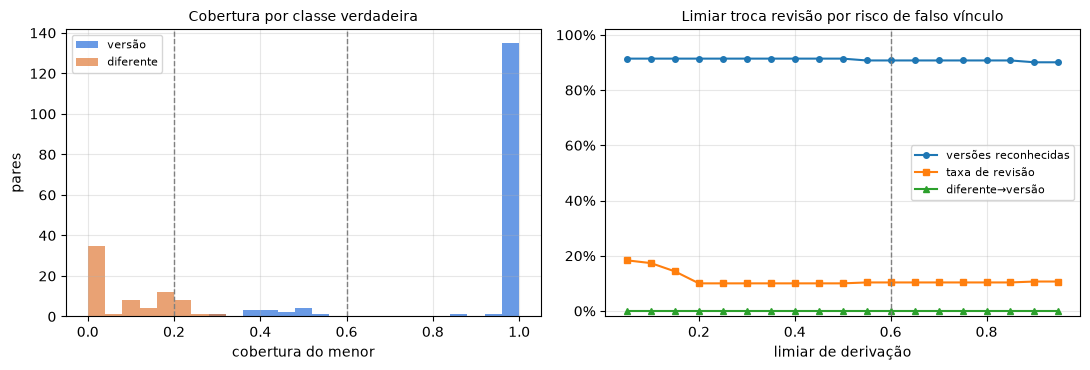

 limiar  versões reconhecidas  taxa de revisão  diferente→versão
   0.10                 91.4%            17.3%              0.0%
   0.20                 91.4%            10.0%              0.0%
   0.30                 91.4%            10.0%              0.0%
   0.40                 91.4%            10.0%              0.0%
   0.50                 91.4%            10.0%              0.0%
   0.60                 90.7%            10.3%              0.0%
   0.70                 90.7%            10.3%              0.0%
   0.80                 90.7%            10.3%              0.0%
   0.90                 90.1%            10.7%              0.0%
falso 'cópia' em toda a grade: [0]


In [31]:
grade = [round(x, 2) for x in np.arange(0.05, 0.96, 0.05)]
curva = []
for t in grade:
    lim = replace(LIMIARES, derivacao=t, diferente=min(LIMIARES.diferente, t))
    prev = [previsto_sistema(l, lim) for l in calibracao]
    versoes = [p for l, p in zip(calibracao, prev) if l["verdade"] == "versão"]
    curva.append({
        "limiar": t,
        "versões reconhecidas": sum(p == "versão" for p in versoes) / len(versoes),
        "taxa de revisão": sum(p == "revisão necessária" for p in prev) / len(prev),
        "diferente→versão": sum(p == "versão" for l, p in zip(calibracao, prev) if l["verdade"] == "diferente") / sum(l["verdade"] == "diferente" for l in calibracao),
        "falso cópia": sum(p in ("cópia", "cópia com ressalva") and l["verdade"] in ("versão", "diferente") for l, p in zip(calibracao, prev)),
    })
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
comparaveis = [l for l in calibracao if l["evidencia"].extracao_ok and not l["evidencia"].so_cosmetico and not l["evidencia"].texto_igual]
for v, cor in [("versão", "#2a6fdb"), ("diferente", "#e07b39")]:
    ax1.hist([l["evidencia"].cobertura_menor for l in comparaveis if l["verdade"] == v], bins=np.linspace(0, 1, 26), alpha=0.7, label=v, color=cor)
for limiar in (LIMIARES.diferente, LIMIARES.derivacao):
    ax1.axvline(limiar, color="gray", linestyle="--", linewidth=1)
ax1.set_xlabel("cobertura do menor")
ax1.set_ylabel("pares")
ax1.set_title("Cobertura por classe verdadeira", fontsize=10)
ax1.legend(fontsize=8)
for chave, estilo in [("versões reconhecidas", "-o"), ("taxa de revisão", "-s"), ("diferente→versão", "-^")]:
    ax2.plot(grade, [c[chave] for c in curva], estilo, label=chave, markersize=4)
ax2.axvline(LIMIARES.derivacao, color="gray", linestyle="--", linewidth=1)
ax2.set_xlabel("limiar de derivação")
ax2.set_ylim(-0.02, 1.02)
ax2.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0))
ax2.legend(fontsize=8, loc="center right")
ax2.set_title("Limiar troca revisão por risco de falso vínculo", fontsize=10)
for ax in (ax1, ax2):
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
print(f"{'limiar':>7}{'versões reconhecidas':>22}{'taxa de revisão':>17}{'diferente→versão':>18}")
for c in curva[1::2]:
    print(f"{c['limiar']:>7.2f}{c['versões reconhecidas']:>22.1%}{c['taxa de revisão']:>17.1%}{c['diferente→versão']:>18.1%}")
print("falso 'cópia' em toda a grade:", sorted({c["falso cópia"] for c in curva}))
assert all(c["falso cópia"] == 0 for c in curva)

### 11.3 Próximo passo do desenho: classificador calibrado na faixa ambígua

A §12 mostra que o custo dominante é humano. As regras abstêm-se, por desenho, na faixa ambígua (cobertura entre 20% e 60%). O próximo passo é um **classificador calibrado** só nessa faixa, com **abstenção com risco controlado**:

- **Entradas:** as evidências que já existem (as duas coberturas, fração de parágrafos alinhados, incluídos e removidos, identidade igual ou não, negação, campos alterados). Em produção, o veredito de um LLM sobre os trechos ambíguos entra como mais uma entrada, validado do mesmo jeito.
- **Garantia (controle de risco):** dois limiares, `t_alto` para decidir “versão” e `t_baixo` para decidir “diferente”, escolhidos num conjunto de calibração separado. O **risco** é a fração de *todos* os pares da faixa ambígua que viram uma decisão errada. Ele só cresce à medida que o limiar fica mais liberal. Aceita-se o limiar mais liberal cujo **limite superior exato de 95%** (Clopper-Pearson) do risco fica ≤ α, numa busca do mais conservador para o mais liberal que para na primeira falha (sequência fixa, como no *Learn-then-Test*). O resto continua em revisão.
- **O que essa garantia não diz:** (1) ela limita o erro sobre a faixa toda, não entre os decididos. Por isso a precisão entre os decididos é reportada junto, com seu próprio limite. (2) Ela vale se produção e calibração vierem da **mesma distribuição**: um cliente novo, com outros modelos de petição, exige calibração por cliente ou tipo de documento e monitoramento da taxa de correção do revisor.
- **O que nunca muda:** o classificador **não produz “cópia”**. Ele só atua onde as regras já se abstiveram por sobreposição parcial; extração falha e texto curto continuam em revisão.

Aqui α = 2% por direção. A demonstração usa o gerador (seed 3), separado do teste. Uma primeira tentativa, com ~90 pares de calibração e o erro medido só entre os decididos, **não certificou nenhum limiar**. É o comportamento correto: sem rótulos suficientes, nada é automatizado.

In [32]:
def faixa_ambigua(ev, limiares=LIMIARES):
    d = decidir(ev, limiares)
    return (d.classe == "revisão necessária" and ev.extracao_ok
            and min(ev.informativos_a, ev.informativos_b) >= limiares.min_shingles and ev.cobertura_menor < limiares.derivacao)


def atributos(ev):
    n_alinhados = len(ev.alinhados)
    total = max(1, n_alinhados + len(ev.adicionados) + len(ev.removidos))
    return np.array([ev.cobertura_menor, ev.cobertura_maior, n_alinhados / total,
                     len(ev.adicionados) / total, len(ev.removidos) / total, float(not ev.trocas_identidade),
                     float(bool(ev.negacoes)), min(len(ev.campos), 3) / 3])


NOMES_ATRIBUTOS = ["cobertura menor", "cobertura maior", "fração alinhada", "fração incluída",
                   "fração removida", "mesma identidade", "negação", "campos alterados"]


def treinar_logistica(X, y, l2=1.0, passos=3000, taxa=0.1):
    media, desvio = X.mean(axis=0), X.std(axis=0) + 1e-9
    Z = np.hstack([np.ones((len(X), 1)), (X - media) / desvio])
    w = np.zeros(Z.shape[1])
    for _ in range(passos):
        p = 1 / (1 + np.exp(-Z @ w))
        w -= taxa * (Z.T @ (p - y) / len(y) + l2 * np.r_[0, w[1:]] / len(y))
    return lambda Xn: 1 / (1 + np.exp(-np.hstack([np.ones((len(Xn), 1)), (Xn - media) / desvio]) @ w)), w


def escolher_limiares(p, y, alfa, grade=np.round(np.arange(0.99, 0.49, -0.01), 2)):
    """Sequência fixa, do limiar mais conservador ao mais liberal. Risco = erros / todos os pares da faixa; aceita enquanto o limite superior ≤ α."""
    n = len(y)
    t_alto = None
    for t in grade:
        if limite_superior(int(((p >= t) & (y == 0)).sum()), n) > alfa:
            break
        t_alto = t
    t_baixo = None
    for t in np.round(1 - grade, 2):
        if limite_superior(int(((p <= t) & (y == 1)).sum()), n) > alfa:
            break
        t_baixo = t
    return t_alto, t_baixo


treino_modelo = [l for l in avaliar(gerar_pares(seed=3, n=8000)) if l["verdade"] in ("versão", "diferente") and faixa_ambigua(l["evidencia"])]
metade = len(treino_modelo) // 2
ajuste, calib = treino_modelo[:metade], treino_modelo[metade:]
ALFA = 0.02


def montar_classificador(colunas, rotulos_trocados=0.0, seed=7):
    """rotulos_trocados simula desacordo entre revisores: uma fração dos rótulos de ajuste e calibração é invertida."""
    r = random.Random(seed)
    rotulo = lambda l: float((l["verdade"] == "versão") != (r.random() < rotulos_trocados))
    Xa = np.array([atributos(l["evidencia"])[colunas] for l in ajuste])
    ya = np.array([rotulo(l) for l in ajuste])
    Xc = np.array([atributos(l["evidencia"])[colunas] for l in calib])
    yc = np.array([rotulo(l) for l in calib])
    modelo, pesos = treinar_logistica(Xa, ya)
    t_alto, t_baixo = escolher_limiares(modelo(Xc), yc, ALFA)
    return {"modelo": modelo, "pesos": pesos, "colunas": colunas, "t_alto": t_alto, "t_baixo": t_baixo}


def decidir_com_modelo(ev, clf, limiares=LIMIARES):
    d = decidir(ev, limiares)
    if not faixa_ambigua(ev, limiares):
        return d
    p = float(clf["modelo"](atributos(ev)[clf["colunas"]][None, :])[0])
    if clf["t_alto"] is not None and p >= clf["t_alto"]:
        subtipo = "outra instância do modelo" if ev.trocas_identidade else "mesma peça"
        return Decisao("versão", [f"classificador calibrado: p = {p:.2f} ≥ {clf['t_alto']} (risco ≤ {ALFA:.0%} a 95%)"] + d.motivos, ev, subtipo)
    if clf["t_baixo"] is not None and p <= clf["t_baixo"]:
        return Decisao("diferente", [f"classificador calibrado: p = {p:.2f} ≤ {clf['t_baixo']} (risco ≤ {ALFA:.0%} a 95%)"] + d.motivos, ev)
    return d


todas = list(range(len(NOMES_ATRIBUTOS)))
so_coberturas = [0, 1]
ambiguos_teste = [l for l in teste if faixa_ambigua(l["evidencia"])]
abstencoes_antes = sum(previsto_sistema(l) == "revisão necessária" for l in teste)
print(f"faixa ambígua: {len(ajuste)} pares para ajuste, {len(calib)} para calibração (seed 3) | teste: {len(ambiguos_teste)} pares ambíguos | α = {ALFA:.0%}\n")
print(f"{'variante':<46}{'t_alto':>7}{'t_baixo':>8}{'decididos':>11}{'erros':>7}{'erro entre decididos (lim. sup.)':>34}{'abstenção total':>18}")
resultados_modelo = {}
for nome, colunas, trocados in [("todos os atributos, rótulos limpos", todas, 0.0),
                                ("todos os atributos, 5% de rótulos trocados", todas, 0.05),
                                ("só coberturas, 5% de rótulos trocados", so_coberturas, 0.05)]:
    clf = montar_classificador(colunas, trocados)
    decisoes = [decidir_com_modelo(l["evidencia"], clf) for l in ambiguos_teste]
    decididos = [(l, d) for l, d in zip(ambiguos_teste, decisoes) if d.classe != "revisão necessária"]
    erros = sum(d.classe != l["verdade"] for l, d in decididos)
    depois = (abstencoes_antes - len(decididos)) / len(teste)
    resultados_modelo[nome] = {"clf": clf, "decididos": len(decididos), "erros": erros, "abstencao": depois}
    precisao = f"{limite_superior(erros, len(decididos)):.1%}" if decididos else "—"
    resultados_modelo[nome]["erro_decididos_sup"] = limite_superior(erros, len(decididos)) if decididos else None
    print(f"{nome:<46}{str(clf['t_alto']):>7}{str(clf['t_baixo']):>8}{len(decididos):>11}{erros:>7}{precisao:>34}"
          f"{f'{abstencoes_antes / len(teste):.1%} → {depois:.1%}':>18}")
    assert all(d.classe != "cópia" for d in decisoes)
    assert erros / len(ambiguos_teste) <= 2 * ALFA

clf_principal = resultados_modelo["todos os atributos, rótulos limpos"]["clf"]
print("\npesos principais (atributos padronizados):",
      ", ".join(f"{NOMES_ATRIBUTOS[c]} {w:+.1f}" for c, w in sorted(zip(clf_principal["colunas"], clf_principal["pesos"][1:]), key=lambda x: -abs(x[1]))[:4]))
print("continuam em revisão (todos os atributos):",
      dict(Counter(l["tipo"] for l in teste if decidir_com_modelo(l["evidencia"], clf_principal).classe == "revisão necessária")))
reducao_abstencao = 1 - resultados_modelo["todos os atributos, rótulos limpos"]["abstencao"] / (abstencoes_antes / len(teste))
reducao_conservadora = 1 - resultados_modelo["todos os atributos, 5% de rótulos trocados"]["abstencao"] / (abstencoes_antes / len(teste))
print(f"redução das revisões: {reducao_abstencao:.0%} com rótulos limpos; {reducao_conservadora:.0%} com 5% de rótulos trocados")
assert reducao_conservadora < reducao_abstencao

# Na plataforma, o classificador entra como `decisor`, sem mudar mais nada do pipeline.
par_ambiguo = next(l for l in teste if l["tipo"] == "reescrita extensa")
for rotulo, decisor in [("só regras", None), ("regras + classificador", lambda ev: decidir_com_modelo(ev, clf_principal))]:
    pl = Plataforma(decisor=decisor)
    pl.criar_caso("cliente-x", "K")
    for nome, texto in (("a.txt", par_ambiguo["a"]), ("b.txt", par_ambiguo["b"])):
        pl.processar(pl.enviar("K", nome, texto.encode("utf-8"), f"k-{nome}"))
    print(f"plataforma com {rotulo}: reescrita extensa → {pl.pares('K')[0][2]}")

faixa ambígua: 285 pares para ajuste, 286 para calibração (seed 3) | teste: 62 pares ambíguos | α = 2%

variante                                       t_alto t_baixo  decididos  erros  erro entre decididos (lim. sup.)   abstenção total
todos os atributos, rótulos limpos                0.5     0.5         62      0                              4.7%      10.1% → 2.4%
todos os atributos, 5% de rótulos trocados       0.98    0.04          5      0                             45.1%      10.1% → 9.5%
só coberturas, 5% de rótulos trocados            None    0.07          4      0                             52.7%      10.1% → 9.6%

pesos principais (atributos padronizados): mesma identidade +1.3, campos alterados -1.2, fração alinhada +1.0, fração removida -0.9
continuam em revisão (todos os atributos): {'extração falhou': 19}
redução das revisões: 77% com rótulos limpos; 6% com 5% de rótulos trocados
plataforma com só regras: reescrita extensa → revisão necessária
plataforma com regras + cla

**Leitura honesta:** com rótulos limpos, os dados sintéticos são separáveis (identidade, campos alterados e fração alinhada bastam) e a faixa ambígua se resolve inteira. Isso diz mais sobre o gerador do que sobre o método. Basta trocar 5% dos rótulos, o tipo de desacordo que existe entre revisores reais, para os limiares certificados recuarem e o classificador decidir só uma fração pequena. **É o comportamento desejado: ele só automatiza o que consegue certificar.** O ganho do desenho não está no número desta célula, e sim no mecanismo, que melhora à medida que a revisão humana gera rótulos (§10) e que torna a concordância entre revisores (kappa) um requisito, não um detalhe.

## 12. Custo e latência

Primeiro **medimos** nesta máquina o tempo de cada etapa por tamanho de documento. Depois **extrapolamos** com premissas explícitas: volume, tamanho dos casos, taxa de revisão e preços. Os preços são hipóteses para ordem de grandeza, não cotações. Os tempos não incluem espera em fila nem I/O de armazenamento.

In [33]:
def medir(func, repeticoes=3):
    tempos = []
    for _ in range(repeticoes):
        t0 = time.perf_counter()
        func()
        tempos.append(time.perf_counter() - t0)
    return min(tempos)


PARAGRAFOS_POR_PAGINA = 6
medicoes = {}
for paginas in (2, 20, 100, 300):
    peca = gerar_peca(random.Random(1000 + paginas), "serviços", n_fatos=(paginas * PARAGRAFOS_POR_PAGINA,) * 2)
    texto_a = peca.texto
    texto_b = texto_a.replace(peca.campos["valor"], "R$ 1,00")
    da, db = indexar(representar("a", texto_a)), indexar(representar("b", texto_b))
    medicoes[paginas] = {
        "indexar": medir(lambda: indexar(representar("a", texto_a))),
        "comparar": medir(lambda: decidir(comparar(da, db))),
    }
pdf_20 = gerar_pdf(gerar_peca(random.Random(1020), "serviços", n_fatos=(100, 100)).paragrafos, "Cabeçalho")
paginas_pdf_20 = pymupdf.open(stream=pdf_20, filetype="pdf").page_count
extracao_por_pagina = medir(lambda: extrair_pdf(pdf_20)) / paginas_pdf_20

print(f"extração de PDF digital: {extracao_por_pagina * 1000:.1f} ms/página (OCR, quando necessário, custa ordens de grandeza a mais)")
print(f"{'páginas':>8}{'indexar (ms)':>14}{'comparar par (ms)':>19}")
for paginas, m in medicoes.items():
    print(f"{paginas:>8}{m['indexar'] * 1000:>14.1f}{m['comparar'] * 1000:>19.1f}")


def interpolar(paginas, etapa):
    xs = sorted(medicoes)
    if paginas <= xs[0]:
        return medicoes[xs[0]][etapa] * paginas / xs[0]
    for x0, x1 in zip(xs, xs[1:]):
        if paginas <= x1:
            f = (paginas - x0) / (x1 - x0)
            return medicoes[x0][etapa] * (1 - f) + medicoes[x1][etapa] * f
    return medicoes[xs[-1]][etapa] * paginas / xs[-1]

extração de PDF digital: 2.1 ms/página (OCR, quando necessário, custa ordens de grandeza a mais)
 páginas  indexar (ms)  comparar par (ms)
       2           1.1                0.5
      20           9.4                4.3
     100          46.7               32.1
     300         141.5              178.1


In [34]:
PREMISSAS = {
    "páginas por documento (mediana)": 20,
    "documentos já no caso (média)": 30,
    "fração de páginas que exigem OCR": 0.10,
    "segundos de OCR por página (CPU)": 2.0,
    "parágrafos por página": PARAGRAFOS_POR_PAGINA,
    "embeddings por segundo por vCPU (e5-base, a medir)": 30,
    "abstenção por par (cenários)": (0.002, 0.005, 0.012),
    "minutos por revisão": 5,
    "R$ por hora de revisor": 60.0,
    "R$ por vCPU-hora": 0.25,
    "tokens de entrada por chamada de LLM": payload["tokens_estimados"],
    "tokens de saída por chamada de LLM": 300,
    "R$ por milhão de tokens de entrada": 15.0,
    "R$ por milhão de tokens de saída": 75.0,
}
for k, v in PREMISSAS.items():
    print(f"  {k}: {v}")


def taxa_documento(p_par, p=PREMISSAS):
    return 1 - (1 - p_par) ** p["documentos já no caso (média)"]


def custo_diario(docs_dia, p_par, p=PREMISSAS, com_embeddings=True):
    pg = p["páginas por documento (mediana)"]
    cpu_s = docs_dia * (pg * extracao_por_pagina + interpolar(pg, "indexar")
                        + p["documentos já no caso (média)"] * interpolar(pg, "comparar")
                        + pg * p["fração de páginas que exigem OCR"] * p["segundos de OCR por página (CPU)"])
    emb_s = docs_dia * pg * p["parágrafos por página"] / p["embeddings por segundo por vCPU (e5-base, a medir)"] if com_embeddings else 0.0
    revisoes = docs_dia * taxa_documento(p_par, p)   # um item de fila por documento (§8)
    llm = revisoes * (p["tokens de entrada por chamada de LLM"] * p["R$ por milhão de tokens de entrada"]
                      + p["tokens de saída por chamada de LLM"] * p["R$ por milhão de tokens de saída"]) / 1e6
    horas_humanas = revisoes * p["minutos por revisão"] / 60
    return {
        "vCPU-hora núcleo": cpu_s / 3600, "vCPU-hora embeddings": emb_s / 3600,
        "R$ CPU": (cpu_s + emb_s) / 3600 * p["R$ por vCPU-hora"], "R$ LLM": llm, "revisões": revisoes,
        "horas de revisão": horas_humanas, "R$ revisão": horas_humanas * p["R$ por hora de revisor"],
    }


print("\nMáquina (independe da taxa de revisão):")
print(f"{'docs/dia':>9}{'vCPU-h núcleo':>15}{'vCPU-h emb.':>13}{'R$ CPU':>10}")
for volume in (1_000, 10_000, 100_000):
    c = custo_diario(volume, 0.0)
    print(f"{volume:>9,}{c['vCPU-hora núcleo']:>15.1f}{c['vCPU-hora embeddings']:>13.1f}{c['R$ CPU']:>10.2f}")

print("\nRevisão por cenário de abstenção (1.000 docs/dia; ×10 e ×100 escalam linearmente):")
print(f"{'por par':>8}{'docs c/ revisão':>17}{'revisões/dia':>14}{'h revisão':>11}{'R$ revisão':>12}{'R$ LLM':>9}{'R$ CPU':>9}")
custos = {}
for p_par in PREMISSAS["abstenção por par (cenários)"]:
    c = custos[p_par] = custo_diario(1_000, p_par)
    print(f"{p_par:>8.1%}{taxa_documento(p_par):>17.1%}{c['revisões']:>14.0f}{c['horas de revisão']:>11.1f}{c['R$ revisão']:>12.0f}"
          f"{c['R$ LLM']:>9.2f}{c['R$ CPU']:>9.2f}")
assert all(c["R$ revisão"] > 10 * (c["R$ CPU"] + c["R$ LLM"]) for c in custos.values())

print("\nCom o classificador calibrado da §11.3 (a redução real depende da qualidade dos rótulos):")
for p_par, c in custos.items():
    print(f"  {p_par:.1%} por par: {c['horas de revisão']:.1f} h/dia → {c['horas de revisão'] * (1 - reducao_abstencao):.1f} h (rótulos limpos) "
          f"a {c['horas de revisão'] * (1 - reducao_conservadora):.1f} h (5% de rótulos trocados)")

  páginas por documento (mediana): 20
  documentos já no caso (média): 30
  fração de páginas que exigem OCR: 0.1
  segundos de OCR por página (CPU): 2.0
  parágrafos por página: 6
  embeddings por segundo por vCPU (e5-base, a medir): 30
  abstenção por par (cenários): (0.002, 0.005, 0.012)
  minutos por revisão: 5
  R$ por hora de revisor: 60.0
  R$ por vCPU-hora: 0.25
  tokens de entrada por chamada de LLM: 826
  tokens de saída por chamada de LLM: 300
  R$ por milhão de tokens de entrada: 15.0
  R$ por milhão de tokens de saída: 75.0

Máquina (independe da taxa de revisão):
 docs/dia  vCPU-h núcleo  vCPU-h emb.    R$ CPU
    1,000            1.2          1.1      0.57
   10,000           11.6         11.1      5.68
  100,000          116.2        111.1     56.82

Revisão por cenário de abstenção (1.000 docs/dia; ×10 e ×100 escalam linearmente):
 por par  docs c/ revisão  revisões/dia  h revisão  R$ revisão   R$ LLM   R$ CPU
    0.2%             5.8%            58        4.9         

**Leitura:** a máquina é barata. O núcleo determinístico custa poucas vCPU-hora por dia mesmo com 100 mil documentos, e o LLM só nos casos de revisão custa pouco. **O custo dominante é o tempo humano de revisão**, mais de uma ordem de grandeza acima do resto em qualquer cenário. E ele é muito sensível à abstenção **por par**: ir de 0,2% para 1,2% por par multiplica as revisões por cerca de 5. Por isso a alavanca econômica é reduzir a abstenção por par *sem* criar erro crítico, e isso só se faz com rótulos reais (§11). O custo cresce linearmente com o volume, porque cada documento só é comparado dentro do seu caso.

In [35]:
rng_lat = random.Random(1200)
latencias = []
for _ in range(2000):
    paginas = min(600, max(1, int(rng_lat.lognormvariate(math.log(20), 0.9))))   # mediana 20 páginas, cauda longa
    ocr = sum(rng_lat.random() < PREMISSAS["fração de páginas que exigem OCR"] for _ in range(paginas)) * PREMISSAS["segundos de OCR por página (CPU)"]
    latencias.append(paginas * extracao_por_pagina + ocr + interpolar(paginas, "indexar")
                     + PREMISSAS["documentos já no caso (média)"] * interpolar(paginas, "comparar"))
latencias.sort()
p50, p95, p99 = (latencias[int(len(latencias) * q)] for q in (0.50, 0.95, 0.99))
print(f"Latência de processamento por documento (sem fila), 2.000 documentos simulados: p50 {p50:.1f}s | p95 {p95:.1f}s | p99 {p99:.1f}s")
pg = PREMISSAS["páginas por documento (mediana)"]
sem_ocr = pg * extracao_por_pagina + interpolar(pg, "indexar") + PREMISSAS["documentos já no caso (média)"] * interpolar(pg, "comparar")
print(f"Documento mediano ({pg} páginas) sem OCR: {sem_ocr:.2f}s. A cauda vem do OCR e de documentos longos.")
print("A meta inicial de p95 ≤ 10 min é folgada; o que a estoura na prática é a fila (picos de upload), não a comparação.")

Latência de processamento por documento (sem fila), 2.000 documentos simulados: p50 4.1s | p95 19.3s | p99 35.7s
Documento mediano (20 páginas) sem OCR: 0.18s. A cauda vem do OCR e de documentos longos.
A meta inicial de p95 ≤ 10 min é folgada; o que a estoura na prática é a fila (picos de upload), não a comparação.


## 13. Painel final

Se o caderno chegou até aqui, **todos os `assert` passaram**. O painel resume a evidência de cada item do enunciado com os números desta execução.

In [36]:
painel = [
    ("1. Representação", "§1, §3, §8", f"hashes, chave cosmética, cabeçalho, elementos não textuais, partes da qualificação, parágrafos com página, shingles, campos; "
     f"hash perceptual: {taxas_imagem['novo scan: ruído + brilho']:.0%} dos novos scans de anexos, {taxas_imagem['falso positivo']:.0%} de falso positivo"),
    ("2. Quase iguais × vocabulário", "§2, §4, §5, §6",
     f"exemplo trabalhado = {exemplo_trabalhado.classe}; {len(tabela_borda)}/{len(tabela_borda)} casos de borda; mesma área com cosseno de palavras >0,9 → diferente; filtro de texto padrão demonstrado"),
    ("3. Documentos longos", "§7", f"{len(paginas_a)} páginas comparadas em {t2 - t1:.2f}s sem LLM; payload ~{payload['tokens_estimados']} tokens vs ~{tokens_documento:,} do documento"),
    ("4. Avaliação", "§11",
     f"teste com {len(teste)} pares: versão→cópia {metricas_teste['versao_para_copia']}/{metricas_teste['n_versoes']} "
     f"(≤{limite_superior(0, metricas_teste['n_versoes']):.1%} a 95%); baseline: {metricas_baseline['versao_para_copia']} versões→cópia; "
     f"revisão por documento ≠ por par (§11.1)"),
    ("5. Depois da classificação", "§8, §10", f"subtipo, relação por trecho (vínculo 'contém'), identidade × cadastro do caso, fila por documento, rótulos; "
     f"cache por parágrafo e por cliente: {segunda['economia']:.1%} dos tokens poupados numa versão"),
    ("6. Custo, latência, precisão", "§9, §11.1, §12",
     f"plataforma com índices exatos + âncoras: recall {recall_plataforma:.1%} comparando {gravados:,} de {n_pares:,} pares; p95 {p95:.0f}s; "
     f"revisão humana domina o custo; classificador calibrado corta {reducao_conservadora:.0%}–{reducao_abstencao:.0%} das revisões"),
]
largura = max(len(p[0]) for p in painel)
for item, secoes, evidencia in painel:
    print(f"✅ {item:<{largura}} | {secoes:<14} | {evidencia}")

✅ 1. Representação              | §1, §3, §8     | hashes, chave cosmética, cabeçalho, elementos não textuais, partes da qualificação, parágrafos com página, shingles, campos; hash perceptual: 90% dos novos scans de anexos, 0% de falso positivo
✅ 2. Quase iguais × vocabulário | §2, §4, §5, §6 | exemplo trabalhado = versão; 34/34 casos de borda; mesma área com cosseno de palavras >0,9 → diferente; filtro de texto padrão demonstrado
✅ 3. Documentos longos          | §7             | 286 páginas comparadas em 0.16s sem LLM; payload ~826 tokens vs ~112,758 do documento
✅ 4. Avaliação                  | §11            | teste com 800 pares: versão→cópia 0/407 (≤0.7% a 95%); baseline: 182 versões→cópia; revisão por documento ≠ por par (§11.1)
✅ 5. Depois da classificação    | §8, §10        | subtipo, relação por trecho (vínculo 'contém'), identidade × cadastro do caso, fila por documento, rótulos; cache por parágrafo e por cliente: 99.7% dos tokens poupados numa versão
✅ 6. Custo, latência,

### Limitações (o que esta demonstração não prova)

- **Dados sintéticos.** O gerador e as regras foram escritos pela mesma pessoa. Os números da §11 medem robustez a perturbações conhecidas, não desempenho em petições reais. O próximo passo é rotular pares reais às cegas, com dois revisores e medida de concordância (kappa).
- **Extração.** PDFs reais têm colunas, tabelas, notas de rodapé e carimbos. O OCR não foi executado (tesseract ausente). A heurística de cabeçalho/rodapé é simples.
- **Embeddings e LLM.** Nesta demo, o embedding é didático e o LLM é simulado. Os dois caminhos de produção estão indicados no código, mas não foram executados.
- **Nomes de partes** não são extraídos como campo (exigiriam NER). Eles aparecem no diff.
- **Texto padrão novo** (ausente da coleção de referência) aumenta revisões até a coleção ser atualizada (§5, §11).
- **Taxa de revisão real é desconhecida.** O gerador não cria ambiguidade entre documentos independentes (§11.1), então a abstenção por par em produção será maior que a medida aqui. A §12 usa cenários por isso.
- **Alinhamento N:M** (vários parágrafos fundidos e divididos ao mesmo tempo) volta ao casamento 1:1 e pode mandar uma versão para revisão.
- **Partes** são extraídas por heurística do parágrafo de qualificação (testada com formato realista em caixa alta, §4.2); em produção, NER ou LLM sobre o 1º parágrafo, conferido com o cadastro do caso (§10.3).
- **Hash perceptual:** taxas medidas em anexos sintéticos, sem inclinação leve (*skew*) nem dobras; com recorte que corta conteúdo, a detecção cai; em páginas de texto do mesmo modelo não separa bem (§8.4). Nunca produz “cópia”.
- **Classificador calibrado:** a garantia é sobre a faixa toda e supõe a mesma distribuição de calibração; com poucos decididos, o limite do erro entre eles fica alto (§11.3). O número real só sai com rótulos reais, por cliente ou tipo de documento.
- **Elementos não textuais** são comparados por impressão digital exata das imagens: uma reexportação que recomprime as imagens gera “cópia com ressalva” (falha segura, custa conferência).
- **Pontuação é material por decisão de projeto:** uma vírgula removida vira “versão”. É uma escolha conservadora que pode ser revista com dados reais.